# T128 launch: ASAM control (T122 + ASAM900), bottleneck PyramidNet-110 / alpha128

This launch copy uses the T128 checklist recipe: identical to T127 (ASAM ρ1.0, η0.01, whole batch, fresh900epochs, T122 architecture and augmentation, bf16, compile reduce-overhead behind the launch preflight; fallback default) except weight decay5e-5 and label smoothing0 (T122's values). Expected4,948,490parameters (model fingerprint = T122). Last/EMA/flip CSV. Only configuration values differ from `E_pyramid_t106_shakedrop.ipynb` (lines marked `T128 launch copy`).

# Scheme E, T106-derived: ShakeDrop and bottleneck PyramidNet (T120 / T121)

NYU Tandon Deep Learning (Fall 2026), Project 1 ([Kaggle competition](https://www.kaggle.com/competitions/cifar-10-res-net-architecture-challenge-dl)).
A residual network is trained **from scratch** on the 50,000 provided CIFAR-10 training images and predicts the
2,000 hidden test images. No pretrained weights and no external data are used.

Fresh 300-epoch runs derived from the T106 recipe (`E_trivialaug_ibn.ipynb`, which is `E_pyramid.ipynb` plus the
`CROP_PADDING_MODE` switch; its IBN switches are removed here so that the default architecture reproduces T106's
model fingerprint exactly). T106 is the parent recipe, not this notebook's task ID. The model identity stays
**model E**: `MODEL="E"`, artifact stem `E_pyramid`, `MODEL_VERSION=None` (allocated at launch) and
`E_VERSION_FLOOR=19` (known started E versions: E18/T118 completed, E19/T119 running; check Drive and teammates
before launch).

| Task | Change versus T106 | Architecture | Parameters | `RUN_NAME` |
|---|---|---|---:|---|
| **T120** (saved preset) | `DROP_PATH` 0.1 → `SHAKEDROP` 0.5; `CROP_PADDING_MODE` constant → reflect; `WEIGHT_DECAY` 5e-4 → 1e-4 | basic PyramidNet-110, α = 98 (same as T106) | 4,963,991 | `shakedrop-reflect` |
| **T121** | T120 recipe; `BLOCK="bottleneck"`, `DEPTH=164`, `ALPHA=100` | bottleneck PyramidNet-164, α = 100 | 4,924,834 | `bottleneck-shakedrop` |

Everything else is T106: 300 epochs, SGD Nesterov 0.9, lr 0.1, weight decay applied to all parameters (BN/bias
included), 5 warmup epochs + cosine (`LR_SCHEDULE="cosine"`), batch 128, label smoothing 0.1, EMA 0.999, crop/flip →
TrivialAugmentWide → normalize → Cutout 16, bf16, channels_last, `COMPILE="reduce-overhead"`, seed 0 / split 0, 45k/5k
split; prediction from the last checkpoint, EMA weights, flip TTA. T120 bundles three changes (reflect padding was
neutral on C: T31 97.06% vs C2 97.08%; weight decay 1e-4 is the ShakeDrop paper's value, against 5e-4 in every earlier
run), so the comparison with T106 cannot isolate them; T121 versus T120 isolates the block type under ShakeDrop.

**ShakeDrop** (`SHAKEDROP`, section 4; Yamada et al., 2019). Block l of L is perturbed with probability
`SHAKEDROP·l/L`, the paper's linear rule with p_L = 1 − `SHAKEDROP` (so 0.5 ⇔ the paper's p_L = 0.5). In training a
gate b ~ Bernoulli(1 − `SHAKEDROP·l/L`) is drawn per image and α ~ U[−1, 1], β ~ U[0, 1] per element of the residual
branch output F(x) (the paper's pixel-level rule); F(x) (after the branch's last BN, before the zero-padded shortcut
is added) is multiplied by b + α − bα in the forward pass and its gradient by b + β − bβ. Evaluation multiplies F(x)
by the expectation 1 − `SHAKEDROP·l/L`. It replaces stochastic depth: `SHAKEDROP > 0` with `DROP_PATH > 0` is
rejected. Draws come from the device's default RNG inside the compiled graph, like `DROP_PATH`.

**Bottleneck PyramidNet** (`BLOCK`, `DEPTH`, `ALPHA`; Han et al., 2017): BN → 1×1 → BN → ReLU → 3×3 (stride) → BN →
ReLU → 1×1 (4× width) → BN, the same parameter-free shortcut, no ReLU after the addition, (depth − 2)/9 blocks per
stage, final BN → ReLU → global average pool → FC(4·final width → 10). All parameter counts are exact and must stay
≤ 5,000,000 (asserted when the model is built).

**SAM / ASAM** (off here; section 5) composes with ShakeDrop: the second pass replays exactly the first pass's
ShakeDrop draws and the RNG advances once per update. Optional refinements, all off by default: `SAM_ETA` (ASAM's
T = |w| + η), `SAM_M` (m-sharpness, a separate perturbation per chunk of m images), `LR_SCHEDULE="multistep"`
(warmup + ×`LR_GAMMA` at `LR_MILESTONE_FRACTIONS` of the epochs) and `CUTMIX` (ported from the T119 notebook; may be
combined with Cutout, exclusive with Mixup). With their defaults the training step and schedule are exactly the
earlier ones. With `COMPILE="reduce-overhead"` whole-batch SAM/ASAM runs the same update through CUDA graphs behind an
automatic real-device preflight against the reference path `COMPILE="default"` (section 5).

**Usage.** Select an A100 in Colab, mount Drive, and Run all. Verify the printed task ID, run ID, parameter count and
`Training crop padding: reflect` before leaving the run. Do not submit the generated CSV without approval.
CPU checks: `Archive/tests/test_e_shakedrop.py`. CUDA-graph behaviour and A100 speed are verified only on Colab.

**Main references.** Han, Kim & Kim, *Deep Pyramidal Residual Networks*, CVPR 2017, and their
[PyTorch implementation](https://github.com/dyhan0920/PyramidNet-PyTorch) (MIT); Yamada, Iwamura, Akiba & Kise,
*ShakeDrop Regularization for Deep Residual Learning*, IEEE Access 2019 (arXiv 1802.02375); Huang et al., *Deep
Networks with Stochastic Depth*, ECCV 2016; Müller & Hutter, *TrivialAugment*, ICCV 2021; DeVries & Taylor,
*Cutout*, 2017. The full list is in `README.md`.

## 1. Configuration

Edit this cell, then Run all. Every new experiment receives a New York timestamp and a separate artifact tree.
Set `RESUME_RUN` to the exact previous run ID to resume; changing a training setting during resume is rejected.
Leave `RUN_NAME=None` when resuming. There is no destructive overwrite option.

Use `VAL_SIZE=5000` for comparisons. After selecting a recipe, use `VAL_SIZE=0`, `TRAIN_SUBSET=0`,
and explicitly set `WEIGHTS="model"` or `"ema"` from the validation experiments for the final refit.
A two-epoch smoke test also needs `WARMUP_EPOCHS=0` or `1` and `TRAIN_SUBSET >= BATCH_SIZE`.

Names now use `MM-DD-HH-mm_<notebook-stem>-ver-<version>-<TXX>-<features>_<role>.<extension>` in `America/New_York`. The full year and timezone remain in metadata. Notebook stems are `A_resnet`, `B_wrn`, `C_seresnet`, `E_pyramid`, `F_shake` and `G_resnext`; feature labels contain one or two words, defaulting to the augmentation and `ema` when enabled. `TASK_ID` records the checklist task (`T00` for original baselines). `MODEL_VERSION=None` chooses the next sequential version for that notebook in this result root. An explicit positive version is allowed only if unused. `RUN_NAME` optionally overrides the feature words (for example `cutout-ema`); it is no longer an arbitrary long label. Resume uses the exact existing `RESUME_RUN` and does not create a version.

For example, the first completed A run is `10-30-08-40_A_resnet-ver-1-T00-cutout-ema`. Its best checkpoint is `checkpoints/10-30-08-40_A_resnet-ver-1-T00-cutout-ema/10-30-08-40_A_resnet-ver-1-T00-cutout-ema_best-ckpt.pt`. Training artifacts use the run-start timestamp. Evaluations and exports use their creation minute and retain the same model/version/features; repeated outputs within a minute get a role suffix such as `submission-2.csv`. Dataset files and caches keep their existing names. Shared project checks/reviews use `project1-ver-<index>-<features>` because they are not attributable to one notebook. Directory-index `README.md` files retain their conventional name.

**T120 preset (saved):** the T106 recipe with `DROP_PATH=0.0`, `SHAKEDROP=0.5`, `CROP_PADDING_MODE="reflect"`, `WEIGHT_DECAY=1e-4` (T106: 5e-4), `LR_SCHEDULE="cosine"`, SAM off, `BLOCK="basic"`, `DEPTH=110`, `ALPHA=98` (4,963,991 parameters), `TASK_ID="T120"`, `RUN_NAME="shakedrop-reflect"`. **T121** differs only in `BLOCK="bottleneck"`, `DEPTH=164`, `ALPHA=100` (4,924,834 parameters), `TASK_ID="T121"`, `RUN_NAME="bottleneck-shakedrop"`. Both keep `MODEL_VERSION=None` and `E_VERSION_FLOOR=19`: the version is allocated at launch from this result root and the floor; verify on Drive and with teammates that no newer E version exists (raise the floor if so). Resume must match all saved scientific settings, including the architecture options and the crop padding.

In [3]:
# LAUNCH COPY T128 (registered 2026-11-03, owner J.H.): ASAM control = T122 + ASAM900. Identical to T127 except
# weight decay 5e-5 and label smoothing 0 (T122's values); bottleneck PyramidNet-110 alpha 128, 4,948,490 parameters,
# model fingerprint = T122. Only the lines marked "T128 launch copy" differ from E_pyramid_t106_shakedrop.ipynb;
# the pre-declared comparison (vs T122 / T127) is in checklist T128.
# Version: E_VERSION_FLOOR 32, so the run takes E >= 33 on J.H.'s Drive (one above T127, so two simultaneous launches
# cannot share a version); check the printed "Run ID:" line.
# COMPILE "reduce-overhead" = the SAM CUDA-graph path; before any run folder exists the automatic launch preflight
# compares it with the reference "default" on this GPU ("[SAM preflight] ... passed"). If the preflight raises, set
# COMPILE = "default" (same update, slower) and Run all again. Measured on a Colab L4 (2026-11-04, bf16): bottleneck-110
# 333.9 ms/step reduce-overhead vs 346.8 default (~128 s/epoch, ~32 h per 900 epochs); A100 not yet measured
# (expected ~55-60 s/epoch, ~14-15 h). Long run: resume after a Colab disconnect with
# RESUME_RUN = "<printed run ID>", RUN_NAME = None, nothing else changed (COMPILE may switch on resume).
# Scheme E (model E, artifact stem E_pyramid): PyramidNet with optional ShakeDrop and bottleneck blocks; section 4.
# Saved preset T120 = the T106 recipe with three changes: DROP_PATH 0.1 -> SHAKEDROP 0.5, CROP_PADDING_MODE
# "constant" -> "reflect" and WEIGHT_DECAY 5e-4 -> 1e-4; basic blocks, depth 110, alpha 98 (4,963,991 parameters),
# cosine schedule. T121 changes only BLOCK = "bottleneck", DEPTH = 164, ALPHA = 100 (4,924,834 parameters), TASK_ID
# and RUN_NAME. E-only training switches SAM (with SAM_ETA / SAM_M), CUTMIX and MIXSTYLE are off.
# Export final/EMA/flip (CHECKPOINT="last", WEIGHTS="ema", TTA=True) like T106; best is also evaluated.
# Edit the values below, then Run all.

RUN_NAME = "asam-t122reg"  # T128 launch copy (was: "shakedrop-reflect")
RESUME_RUN = None        # exact saved run ID to resume, e.g. "10-30-08-40_A_resnet-ver-1-T00-cutout-ema"
EPOCHS = 900  # T128 launch copy (was: 300)
                         # halves the epochs for equal compute (ASAM paper: SGD 400 vs SAM/ASAM 200; PyramidNet-272 1800
                         # vs 900), so SAM at EPOCHS = 150 costs about one 300-epoch SGD run. Not changed automatically.
AUG = "trivialaug"       # T106: basic crop/flip + TrivialAugmentWide (per image on the CPU) + AUTOAUG_ERASE
                         # | "basic" | "cutout" | "autoaug": basic + CIFAR10 AutoAugment + AUTOAUG_ERASE
SEED = 0                 # model initialization, data order and augmentation draws
VAL_SIZE = 5000          # class-balanced validation hold-out (multiple of 10); 0 = train on all 50,000 images
EMA = True               # also keep (and evaluate) an exponential moving average of the weights
AMP = "bf16"             # CUDA only: "auto" = bf16 on GPUs with native bf16 (e.g. A100), else fp16 | "off" | "bf16" | "fp16"
CKPT_EVERY = None        # write last-ckpt.pt every N epochs; None = 5 on Colab (Drive writes are slow), else 1
TRAIN_SUBSET = 0         # > 0: train on this many images only (quick tests; multiple of 10)
# New runs never overwrite previous outputs. Set RESUME_RUN explicitly to continue a run.

# Optimization
BATCH_SIZE = 128         # kept with LR 0.1: the same LR/batch ratio as Fast AutoAugment's PyramidNet-272 (64 / 0.05)
LR = 0.1                 # and the ShakeDrop paper (128 / 0.1); the ASAM paper used 256 / 0.05
MOMENTUM = 0.9
NESTEROV = True
WEIGHT_DECAY = 5e-5  # T128 launch copy (was: 1e-4)
                         # PyramidNet-272 + ShakeDrop config uses 5e-5. With ShakeDrop + TrivialAugment + Cutout the
                         # stronger 5e-4 may over-regularize. Applies to all parameters unless WD_SKIP_BN_BIAS
WD_SKIP_BN_BIAS = False  # True: no weight decay on BN parameters and biases
WARMUP_EPOCHS = 5
LR_SCHEDULE = "cosine"   # "cosine" (T106: linear warmup, then cosine to 0) | "multistep" (same warmup, then the LR is
                         # multiplied by LR_GAMMA after each milestone epoch; A/C T66/T68 semantics). Measured 300-epoch
                         # pairs: A step 96.92% vs cosine 96.86% (T66 vs T65), C step 96.96% vs cosine 96.92% (T68 vs
                         # T67), within noise. The literature mostly uses cosine (Fast AutoAugment PyramidNet-272: cosine
                         # + 5 warmup epochs); the original ShakeDrop paper stepped at epochs 150 and 225 of 300
LR_MILESTONE_FRACTIONS = (0.5, 0.75)  # multistep only: milestones as fractions of EPOCHS (150 and 225 of 300), saved
                         # with the resolved epochs (rounded half up); ignored for cosine
LR_GAMMA = 0.1           # multistep only: LR factor at each milestone
LABEL_SMOOTHING = 0.0  # T128 launch copy (was: 0.1)
EMA_DECAY = 0.999
# Sharpness-aware minimization around the SGD above (section 5); off in this preset. About 2x s/epoch (see EPOCHS).
# The code follows github.com/davda54/sam: e = rho * T^2 g / (||T g|| + 1e-12), all parameters (BN and bias included)
# perturbed, weight decay only in SGD. With SHAKEDROP > 0 every second pass replays its first pass's ShakeDrop draws.
SAM = True  # T128 launch copy (was: False)
SAM_RHO = 1.0  # T128 launch copy (was: 0.05)
                         # teammate T112 used 2.0). The ASAM paper used 0.5 (CIFAR-10 models) and 1.0 (PyramidNet-272)
                         # with eta 0.01, a different T, so its radii are not directly comparable with davda54's. Larger
                         # rho = stronger flatness regularization, with a risk of underfitting or instability
SAM_ADAPTIVE = True  # T128 launch copy (was: False)
SAM_ETA = 0.01  # T128 launch copy (was: 0.0)
                         # so weights near zero still get a nonzero radius; 0.0 = davda54's T = |w| (T112)
SAM_M = None             # m-sharpness: None = one perturbation from the whole batch; an integer m dividing BATCH_SIZE
                         # gives each chunk of m images its own perturbation from its own gradient and averages the chunk
                         # gradients for one SGD step. The SAM paper finds smaller m usually generalizes better; ASAM's
                         # PyramidNet used m = 32 of batch 256. Cost: 2 x BATCH_SIZE/m smaller passes (slower); BatchNorm
                         # uses m-image statistics in every pass, and each chunk's first pass updates the running
                         # statistics (second passes never do). Not combinable with MIXSTYLE

# Data and augmentation
SPLIT_SEED = 0           # seed of the train/validation split; keep it fixed so runs are comparable
CUTOUT_SIZE = 16
CROP_PADDING_MODE = "constant"  # T128 launch copy (was: "reflect")
                         # edge pixel, as in scheme C/T31); training random crop only, validation/test unchanged
AUTOAUG_ERASE = "cutout" # occlusion after AutoAugment or TrivialAugment: "cutout" | "erasing" (RandomErasing) | "none"
ERASING_P = 0.5          # RandomErasing probability

# Training-only Mixup option (P13): off in this preset; enabling it also requires AUG="basic" and smoothing 0 above.
MIXUP = False            # True enables P13 batch Mixup (with AUG="basic" and LABEL_SMOOTHING=0.0)
MIXUP_ALPHA = 0.2        # positive Beta distribution parameter; one lambda per triggered batch
MIXUP_PROB = 0.5         # probability of mixing a training batch; validation/test never mix

# Training-only CutMix (Yun et al., 2019), ported from E_pyramid_t106_cutmix.ipynb (T119); off in this preset.
CUTMIX = False           # True: with probability CUTMIX_PROB a batch gets one rectangle from a shuffled partner batch;
                         # targets weighted by the clipped patch area, label smoothing applied to both. Exclusive with
                         # MIXUP. May be combined with Cutout (AUTOAUG_ERASE="cutout" / AUG="cutout"): the CutMix paper
                         # replaces Cutout (T119 turned it off), Fast AA / TA recipes use Cutout and ASAM's PyramidNet
                         # used AutoAugment + CutMix; stacking both is stronger regularization, with a risk of
                         # underfitting on short schedules. SAM passes and SAM_M chunks share the same mixed batch
CUTMIX_ALPHA = 1.0       # Beta(alpha, alpha) area ratio, one draw per triggered batch
CUTMIX_PROB = 0.5        # probability of mixing a training batch; validation/test never mix

# Training-only MixStyle after PyramidNet stages 1 and 2 (section 4); off in this preset. Parameter-free.
MIXSTYLE = False         # True mixes per-image feature mean/std with a shuffled partner in training; identity in evaluation
MIXSTYLE_P = 0.5         # probability that a MixStyle layer mixes a training batch (drawn per layer and step)
MIXSTYLE_ALPHA = 0.1     # Beta(alpha, alpha) mixing weight, one per image
MIXSTYLE_EPS = 1e-6      # added to the feature variance before the square root

# Hardware (None = automatic: on for CUDA, off for MPS / CPU)
DEVICE = "cuda"          # "cuda" | "mps" | "cpu"; None = $CIFAR_DEVICE, else cuda > mps > cpu
CHANNELS_LAST = None
CUDNN_BENCHMARK = None
PIN_MEMORY = None
WORKERS = None           # DataLoader workers for AUG = "autoaug" / "trivialaug" (always 0 on macOS / Windows, see section 2)
EVAL_BATCH_SIZE = 1000
LOG_INTERVAL = 0         # also print every N steps within an epoch (0 = off)
# Optional speed switches (README "Compilation"); neither is part of the recipe or of any fingerprint.
COMPILE = "reduce-overhead"  # T128 launch copy: SAM CUDA-graph path, gated by the launch preflight (fallback "default")
                         # With SAM: "reduce-overhead" = CUDA graphs behind an automatic launch preflight (section 5),
                         # "default" = the reference SAM path; "max-autotune" is rejected; SAM_M / MIXSTYLE need "default"
BENCHMARK_STEPS = 0      # > 0: only time this many training steps (real data, current COMPILE); no run folder; then stop

# Prediction
CHECKPOINT = "last"      # checkpoint used for the submission: "best" (highest validation accuracy) | "last"
WEIGHTS = "ema"          # "auto" chooses on validation using TTA; for VAL_SIZE=0 set "model" or "ema" explicitly
TTA = True               # average the softmax of each test image and its horizontal flip

# Runtime host, independent of the editor: auto | colab | kaggle | local.
# For a VS Code kernel connected to Colab, set "colab" if auto detection is ambiguous.
RUNTIME_ENV = "colab"    # explicit value overrides CIFAR_ENV; auto uses CIFAR_ENV then detection

# Paths (None = $CIFAR_DATA_DIR / $CIFAR_CACHE_DIR / $CIFAR_RESULT_DIR, else the default of the environment)
AUTO_DOWNLOAD = False     # Kaggle download/login code is commented out; use uploaded data
SAVE_CACHE_TO_DRIVE = True # on Colab, automatically save/verify MyDrive/DL_Project1/cache.zip
DATA_DIR = None          # Colab: MyDrive/DL_Project1/data/ (folder or override with a ZIP path)
CACHE_DIR = None
RESULT_DIR = None
SHOW_SUMMARY = True      # torchinfo layer table in section 4 (skipped if torchinfo is not installed)

# Architecture switches (requirement 15): DROP_PATH, SHAKEDROP, BLOCK, DEPTH and ALPHA (section 4).
TASK_ID = "T128"  # T128 launch copy (was: "T120")
MODEL_VERSION = None     # allocate the next E version at actual launch; no advance reservations
E_VERSION_FLOOR = 32  # T128 launch copy (was: 19)
                         # hold newer E runs. Launch T120 and T121 one after the other (each takes the next version)
DROP_PATH = 0.0          # stochastic depth: block l of L dropped with prob DROP_PATH*l/L; must be 0 with ShakeDrop
SHAKEDROP = 0.5          # ShakeDrop: block l of L perturbed with prob SHAKEDROP*l/L (p_L = 1 - SHAKEDROP); 0 = off
BLOCK = "bottleneck"  # T128 launch copy (was: "basic")
DEPTH = 110              # basic: 6n+2 (110 = 18 blocks per stage); bottleneck: 9n+2 (164, 200, 272)
ALPHA = 128  # T128 launch copy (was: 98)

## 2. Environment, paths and device

| Environment | Data | Cache | Results |
|---|---|---|---|
| Local | `project1/data` | `project1/cache` | `project1/result`, beside `Archive` |
| Colab | `MyDrive/DL_Project1/data` (manual upload), or explicit `DATA_DIR` | `/content/cache` | `MyDrive/DL_Project1/result` |
| Kaggle | Competition directory under `/kaggle/input` | `/kaggle/working/cache` | `/kaggle/working/result` |

Set `DATA_DIR`, `CACHE_DIR`, `RESULT_DIR` explicitly when needed. Their `CIFAR_*_DIR` environment variables
are fallback overrides. On Colab select an A100 GPU. Automatic precision uses bf16 on an A100;
channels-last and cuDNN benchmarking are enabled. AutoAugment uses forked workers on Linux and zero workers
on macOS/Windows. Keep the same hardware settings across architecture comparisons.

Artifacts are grouped by type under `result`: `checkpoints`, `configs`, `logs`, `evaluations/validation`,
`evaluations/test`, `plots`, `progress`, `manifests`, and `exports`. Each uses the same timestamped run ID.
The local default assumes the kernel starts in `project1` or `project1/Archive`; otherwise set paths explicitly.

Detection follows the remote Python kernel, even when the editor is VS Code. Runtime markers take priority
over directory names. Set `RUNTIME_ENV="colab"` in section 1 to explicitly select Colab paths; this overrides
`CIFAR_ENV`. It does not connect or move a local kernel to Colab. Restart the kernel and rerun from section 1
after changing it. Check the printed environment, kernel executable, GPU and paths.


In [4]:
import copy
import csv
import hashlib
import importlib.util
import importlib.metadata
import io
import json
import math
import os
import platform
import random
import re
import shutil
import subprocess
import sys
import time
import tempfile
import zlib
import zipfile
from concurrent.futures import ThreadPoolExecutor
from dataclasses import dataclass
from datetime import datetime
from zoneinfo import ZoneInfo
from pathlib import Path
from types import SimpleNamespace

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import torch
import torch.nn as nn
import torch.nn.functional as F
import torchvision
from matplotlib.ticker import MaxNLocator
from PIL import Image

ENVS = ("local", "colab", "kaggle")
KAGGLE_SLUG = "cifar-10-res-net-architecture-challenge-dl"
DRIVE_PROJECT_DIR = "/content/drive/MyDrive/DL_Project1"
WORK_DIRS = {"colab": "/content", "kaggle": "/kaggle/working"}
COLAB_CKPT_EVERY = 5  # Drive writes are slow; best-ckpt.pt and the final epoch are always saved
PROJECT_DIR = Path.cwd().resolve()
LOCAL_PROJECT_DIR = PROJECT_DIR.parent if PROJECT_DIR.name == "Archive" else PROJECT_DIR
# Start method for the AutoAugment DataLoader workers: "fork" lets them use the Dataset class defined in this
# notebook. Under "spawn" (macOS, Windows) they cannot import it, so the pipeline runs in the main process there.
MP_CONTEXT = "fork" if sys.platform.startswith("linux") else None

_warned = set()


def _getenv(name):
    value = os.environ.get(name, "").strip()
    return value or None


def warn_once(msg):
    if msg not in _warned:
        _warned.add(msg)
        print(f"Warning: {msg}", flush=True)


def _module_exists(name):
    try:
        return importlib.util.find_spec(name) is not None
    except (ImportError, ValueError):
        return False


def detect_env():
    """Detect the kernel host, independent of the notebook editor (browser or VS Code)."""
    configured = str(globals().get("RUNTIME_ENV") or "auto").strip().lower()
    if configured not in ("auto",) + ENVS:
        raise ValueError(f"RUNTIME_ENV={configured!r}; expected auto or one of {ENVS}")
    requested = configured if configured != "auto" else (_getenv("CIFAR_ENV") or "auto").lower()
    if requested not in ("auto",) + ENVS:
        raise ValueError(f"CIFAR_ENV={requested!r}; expected auto or one of {ENVS}")
    if requested != "auto":
        return requested
    # Runtime markers beat directory names: /kaggle/input may also exist on Colab.
    if any(_getenv(key) for key in ("COLAB_RELEASE_TAG", "COLAB_BACKEND_VERSION")):
        return "colab"
    if _getenv("KAGGLE_KERNEL_RUN_TYPE"):
        return "kaggle"
    if _module_exists("google.colab"):
        return "colab"
    # A directory alone is weak evidence; use the full layout only as a fallback.
    if os.path.isdir("/kaggle/input") and os.path.isdir("/kaggle/working"):
        return "kaggle"
    return "local"


def work_dir(env=None):
    env = env or detect_env()
    return Path(_getenv("CIFAR_WORK_DIR") or WORK_DIRS.get(env, PROJECT_DIR))


def drive_dir():
    return Path(_getenv("CIFAR_DRIVE_DIR") or DRIVE_PROJECT_DIR)


def drive_mounted():
    return drive_dir().parent.is_dir()  # .../MyDrive exists once Drive is mounted


def kaggle_input_dir():
    return Path(_getenv("CIFAR_KAGGLE_INPUT") or "/kaggle/input")


def find_competition_data(root=None, max_depth=6):
    """Directories under `root` that contain train_labels.csv, best match first.

    Breadth-first, follows symlinks, skips *_images folders (50k files) and hidden folders.
    """
    root = Path(root or kaggle_input_dir())
    found, frontier = [], [(root, 0)]
    while frontier:
        d, depth = frontier.pop(0)
        try:
            entries = sorted(os.scandir(d), key=lambda e: e.name)
        except OSError:
            continue
        if any(e.name == "train_labels.csv" and e.is_file() for e in entries):
            found.append(d)
        if depth < max_depth:
            frontier += [(Path(e.path), depth + 1) for e in entries
                         if e.is_dir() and not e.name.endswith("_images") and not e.name.startswith(".")]

    def rank(d):
        complete = (d / "test.csv").is_file() and (d / "sample_submission.csv").is_file()
        return (not complete, KAGGLE_SLUG not in str(d), len(d.parts), str(d))

    return sorted(found, key=rank)


@dataclass
class Paths:
    env: str
    data_dir: Path
    cache_dir: Path
    result_dir: Path


def resolve_paths(data_dir=None, cache_dir=None, result_dir=None, env=None):
    """Data, cache and runs directories: argument > environment variable > environment default."""
    env = env or detect_env()
    data = data_dir or _getenv("CIFAR_DATA_DIR")
    cache = cache_dir or _getenv("CIFAR_CACHE_DIR")
    runs = result_dir or _getenv("CIFAR_RESULT_DIR")
    if env == "local":
        data = data or LOCAL_PROJECT_DIR / "data"
        cache = cache or LOCAL_PROJECT_DIR / "cache"
        runs = runs or LOCAL_PROJECT_DIR / "result"
    elif env == "colab":
        cache = cache or work_dir(env) / "cache"
        data = data or drive_dir() / "data"  # manually uploaded ZIPs or extracted competition files
        if runs is None:
            if drive_mounted():
                runs = drive_dir() / "result"
            else:
                runs = work_dir(env) / "result"
                warn_once(f"Google Drive is not mounted ({drive_dir().parent} missing); writing results to "
                          f"{runs}, which is lost when the runtime is recycled")
    else:  # kaggle
        cache = cache or work_dir(env) / "cache"
        runs = runs or work_dir(env) / "result"
        if data is None:
            found = find_competition_data()
            if found:
                data = found[0]
            else:
                data = work_dir(env) / "data"
                warn_once(f"no train_labels.csv found under {kaggle_input_dir()}; checking cache or manually supplied data")
    return Paths(env, Path(data), Path(cache), Path(runs))


def default_ckpt_every(env=None):
    return COLAB_CKPT_EVERY if (env or detect_env()) == "colab" else 1


def available_cpus():
    try:
        return len(os.sched_getaffinity(0))
    except AttributeError:  # macOS
        return os.cpu_count() or 1


def default_workers(device_type):
    """DataLoader workers (used by the per-image AutoAugment pipeline only)."""
    n = available_cpus()
    if device_type == "cuda":
        return min(8, max(2, n - 1))
    return min(4, max(1, n // 2))  # 4 on the 12-core M4 Pro, as before


def get_device(name=None):
    """`name` (DEVICE), else $CIFAR_DEVICE, else cuda > mps > cpu."""
    name = name or _getenv("CIFAR_DEVICE") or "auto"
    if name == "auto":
        if torch.cuda.is_available():
            return torch.device("cuda")
        if torch.backends.mps.is_available():
            return torch.device("mps")
        return torch.device("cpu")
    return torch.device(name)


def cuda_bf16_native(device):
    return torch.cuda.get_device_capability(device) >= (8, 0)  # Ampere or newer (L4, A100, ...)


def resolve_amp(requested, device):
    """'bf16', 'fp16' or 'off'. requested: auto | on | off | bf16 | fp16 (bools accepted)."""
    req = {True: "on", False: "off", None: "auto"}.get(requested, requested)
    req = str(req).lower()
    if req == "off":
        return "off"
    if device.type != "cuda":
        if req != "auto":
            # MPS: fp16 autocast gave no speed-up on an M4 Pro, and torch 2.5.1 GradScaler fails on MPS.
            print(f"Warning: AMP is only used on CUDA; training in fp32 on {device.type}.")
        return "off"
    if req == "fp16":
        return "fp16"
    if cuda_bf16_native(device):
        return "bf16"
    if req == "bf16":
        print("Warning: this GPU has no native bf16; using fp16 autocast + GradScaler instead.")
    return "fp16"


# torch.compile modes for the training step (README "Compilation"); a speed option, never part of the recipe.
COMPILE_MODES = ("off", "default", "reduce-overhead", "max-autotune", "max-autotune-no-cudagraphs")


def resolve_compile(requested, device, name="COMPILE"):
    """One of COMPILE_MODES. Compilation is used on CUDA only; elsewhere it warns and runs uncompiled ("off")."""
    if not isinstance(requested, str) or requested not in COMPILE_MODES:
        raise ValueError(f"{name} = {requested!r}; choose one of {COMPILE_MODES}")
    if requested != "off" and device.type != "cuda":
        print(f"Warning: {name}={requested!r} is only used on CUDA; running uncompiled on {device.type}.")
        return "off"
    return requested


def resolve_hardware(args, device):
    """Fill in the automatic (None) speed settings on `args` for `device`, in place."""
    cuda = device.type == "cuda"
    args.amp = resolve_amp(getattr(args, "amp", "auto"), device)
    args.compile = resolve_compile(getattr(args, "compile", "off"), device)
    if args.channels_last is None:
        args.channels_last = cuda
    elif args.channels_last and device.type == "mps":
        # torch 2.5.1 MPS: backward through conv/BN/ReLU in channels_last raises a stride error.
        print("Warning: CHANNELS_LAST is not supported on MPS with this PyTorch; disabling it.")
        args.channels_last = False
    if getattr(args, "cudnn_benchmark", None) is None:
        args.cudnn_benchmark = cuda
    if getattr(args, "pin_memory", None) is None:
        args.pin_memory = cuda
    if getattr(args, "workers", None) is None:
        args.workers = default_workers(device.type)
    if MP_CONTEXT is None:
        args.workers = 0  # see MP_CONTEXT
    return args


def device_name(device):
    if device.type == "cuda":
        props = torch.cuda.get_device_properties(device)
        return f"cuda ({props.name}, {props.total_memory / 2**30:.0f} GB)"
    if device.type == "cpu":
        return f"cpu ({available_cpus()} cores)"
    return f"{device.type} ({platform.machine()})"


def _on(x):
    return "on" if x else "off"


def summary_line(paths, device=None, args=None):
    """One line: environment, device, torch, speed settings and the output directories."""
    import torch

    parts = [f"env {paths.env}"]
    if device is not None:
        parts.append(device_name(device))
    parts.append(f"torch {torch.__version__}")
    if args is not None:
        parts.append(f"amp {args.amp} | channels_last {_on(args.channels_last)} | "
                     f"cudnn.benchmark {_on(args.cudnn_benchmark)} | workers {args.workers} | "
                     f"pin_memory {_on(args.pin_memory)}")
        if getattr(args, "compile", "off") != "off":
            parts.append(f"compile {args.compile}")
    parts.append(f"data {paths.data_dir} | cache {paths.cache_dir} | result {paths.result_dir}")
    return "[env] " + " | ".join(parts)

def run_timestamp():
    return datetime.now(ZoneInfo("America/New_York")).strftime("%m-%d-%H-%M")


# Exact historical aliases: checkpoint bytes and signed export manifests remain unchanged.
RUN_ID_ALIASES = {'10-30-08-40_A_resnet-ver-1-cutout-ema': '10-30-08-40_A_resnet-ver-1-T00-cutout-ema', '10-30-09-44_B_wrn-ver-1-cutout-ema': '10-30-09-44_B_wrn-ver-1-T00-cutout-ema', '10-30-09-46_C_seresnet-ver-1-cutout-ema': '10-30-09-46_C_seresnet-ver-1-T00-cutout-ema', '10-30-09-50_C_seresnet-ver-2-cutout-ema': '10-30-09-50_C_seresnet-ver-2-T00-cutout-ema', '10-30-19-41_B_wrn-ver-2-wide-ema': '10-30-19-41_B_wrn-ver-2-T08-wide-ema', '10-30-20-03_A_resnet-ver-6-eca-ema': '10-30-20-03_A_resnet-ver-2-T48-eca-ema', '10-30-20-04_C_seresnet-ver-8-se8-ema': '10-30-20-04_C_seresnet-ver-3-T06-se8-ema', '10-30-21-05_E_pyramid-ver-1-basic110-ema': '10-30-21-05_E_pyramid-ver-1-T18-basic110-ema', '10-30-21-07_G_resnext-ver-1-grouped-ema': '10-30-21-07_G_resnext-ver-1-T42-grouped-ema', '10-30-21-17_A_resnet-ver-7-mixup-ema': '10-30-21-17_A_resnet-ver-3-T49-mixup-ema', '10-30-21-18_B_wrn-ver-8-mixup-ema': '10-30-21-18_B_wrn-ver-3-T50-mixup-ema', '10-30-21-42_F_shake-ver-1-shake40': '10-30-21-42_F_shake-ver-1-T35-shake40', '10-30-21-47_C_seresnet-ver-31-mixup-ema': '10-30-21-47_C_seresnet-ver-4-T51-mixup-ema', '10-30-23-09_A_resnet-ver-4-early-ema': '10-30-23-09_A_resnet-ver-4-T22-early-ema', '10-30-23-10_B_wrn-ver-6-deep-ema': '10-30-23-10_B_wrn-ver-4-T24-deep-ema', '10-30-23-43_C_seresnet-ver-3-autoaug-cutout': '10-30-23-43_C_seresnet-ver-5-T01-autoaug-cutout', '10-30-23-56_A_resnet-ver-5-mid-ema': '10-30-23-56_A_resnet-ver-5-T26-mid-ema', '10-31-00-42_B_wrn-ver-5-balanced-ema': '10-31-00-42_B_wrn-ver-5-T23-balanced-ema', '10-31-00-50_C_seresnet-ver-19-reflect-ema': '10-31-00-50_C_seresnet-ver-6-T31-reflect-ema', '10-30-22-34_F_shake-ver-2-shake40-1800ep': '10-30-22-34_F_shake-ver-2-T35-shake40-1800ep', '10-31-20-06_E_pyramid-ver-3-T61-autoaug-only': '10-31-20-06_E_pyramid-ver-3-T69-autoaug-only'}


def canonical_run_id(run_id):
    return RUN_ID_ALIASES.get(run_id, run_id)


def run_task_id(run_id):
    match = re.search(r"-ver-\d+-(T\d{2,})-", canonical_run_id(run_id))
    return match.group(1) if match else "T00"


def run_paths(result_root, run_id, create=False):
    """One timestamped ID across directories grouped by artifact type."""
    if not run_id or Path(run_id).name != run_id or run_id in (".", ".."):
        raise ValueError("Run ID must be a single directory name")
    run_id = canonical_run_id(run_id)
    root = Path(result_root)
    folders = {"checkpoints": "checkpoints", "configs": "configs", "logs": "logs",
               "validation": "evaluations/validation", "test": "evaluations/test",
               "plots": "plots", "progress": "progress", "manifests": "manifests", "exports": "exports"}
    paths = SimpleNamespace(root=root, run_id=run_id,
                            **{key: root / folder / run_id for key, folder in folders.items()})
    if not paths.checkpoints.exists():
        for legacy, canonical in RUN_ID_ALIASES.items():
            old_dir = root / "checkpoints" / legacy
            if canonical == run_id and old_dir.is_dir():
                paths.checkpoints = old_dir
                break
    if create:
        for key in folders:
            getattr(paths, key).mkdir(parents=True, exist_ok=True)
    return paths


def paths_for_run(checkpoint_dir):
    checkpoint_dir = Path(checkpoint_dir)
    if checkpoint_dir.parent.name != "checkpoints":
        raise ValueError("Expected result/checkpoints/<RUN_ID>; legacy flat runs must be migrated explicitly")
    return run_paths(checkpoint_dir.parent.parent, checkpoint_dir.name)


def artifact_path(artifacts, category, role, extension, event=False, unique=False):
    """Stable training paths; dated evaluation/export paths with collision-safe role suffixes."""
    folder = getattr(artifacts, category)
    prefix = artifacts.run_id
    if event:
        identifier = artifacts.run_id.split('_', 1)[1] if '_' in artifacts.run_id else artifacts.run_id
        prefix = f"{run_timestamp()}_{identifier}"
    stem = f"{prefix}_{role}"
    path = folder / (stem + extension)
    if unique:
        index = 1
        while any(folder.glob(path.stem + '*')):
            index += 1
            path = folder / (f"{stem}-{index}" + extension)
    return path


def checkpoint_path(run_dir, which):
    if which not in ('best', 'last'):
        raise ValueError("Checkpoint role must be best or last")
    run_dir = Path(run_dir)
    canonical = canonical_run_id(run_dir.name)
    candidates = [run_dir.parent / canonical / f"{canonical}_{which}-ckpt.pt",
                  run_dir / f"{run_dir.name}_{which}-ckpt.pt"]
    for legacy, target in RUN_ID_ALIASES.items():
        if target == canonical:
            candidates.extend([run_dir.parent / canonical / f"{legacy}_{which}-ckpt.pt",
                               run_dir.parent / legacy / f"{legacy}_{which}-ckpt.pt"])
    return next((p for p in candidates if p.is_file()), candidates[0])


In [5]:
ENV = detect_env()
print(f"[runtime] detected {ENV} | kernel {sys.executable} | cwd {Path.cwd()} | "
      f"RUNTIME_ENV={RUNTIME_ENV!r} | CIFAR_ENV={_getenv('CIFAR_ENV')!r}")
if ENV == "colab":
    try:
        from google.colab import drive
    except ImportError:  # CIFAR_ENV=colab outside Google Colab (testing)
        print("google.colab is not available: skipping drive.mount")
    else:
        drive.mount("/content/drive")

PATHS = resolve_paths(DATA_DIR, CACHE_DIR, RESULT_DIR, ENV)
DEV = get_device(DEVICE)
if ENV == "colab" and DEV.type != "cuda" and (DEVICE or _getenv("CIFAR_DEVICE")) != "cpu":
    raise RuntimeError("No GPU: choose Runtime > Change runtime type > A100 GPU, then Runtime > Run all again")
HW = resolve_hardware(SimpleNamespace(amp=AMP, channels_last=CHANNELS_LAST, cudnn_benchmark=CUDNN_BENCHMARK,
                                      pin_memory=PIN_MEMORY, workers=WORKERS), DEV)
print(summary_line(PATHS, DEV, HW))
print(f"python {platform.python_version()} | torchvision {torchvision.__version__} | numpy {np.__version__} | "
      f"{platform.platform()} | {available_cpus()} CPUs")
if ENV == "colab":
    print(f"Google Drive folder {drive_dir()}: {'found' if drive_dir().is_dir() else 'NOT FOUND'}")
if ENV == "kaggle":
    print(f"Kaggle input {kaggle_input_dir()}: train_labels.csv in "
          f"{[str(d) for d in find_competition_data()] or 'none'}")
if DEV.type == "cuda" and shutil.which("nvidia-smi"):
    print(subprocess.run(["nvidia-smi"], capture_output=True, text=True).stdout)

Mounted at /content/drive
[env] env colab | cuda (NVIDIA A100-SXM4-40GB, 39 GB) | torch 2.11.0+cu130 | amp bf16 | channels_last on | cudnn.benchmark on | workers 8 | pin_memory on | data /content/drive/MyDrive/DL_Project1/data | cache /content/cache | result /content/drive/MyDrive/DL_Project1/result
python 3.13.16 | torchvision 0.26.0+cu130 | numpy 2.4.6 | Linux-6.6.159+-x86_64-with-glibc2.39 | 12 CPUs
Google Drive folder /content/drive/MyDrive/DL_Project1: found
Wed Nov  4 06:57:54 2026       
+-----------------------------------------------------------------------------------------+
| NVIDIA-SMI 580.82.07              Driver Version: 580.82.07      CUDA Version: 13.0     |
+-----------------------------------------+------------------------+----------------------+
| GPU  Name                 Persistence-M | Bus-Id          Disp.A | Volatile Uncorr. ECC |
| Fan  Temp   Perf          Pwr:Usage/Cap |           Memory-Usage | GPU-Util  Compute M. |
|                                       

## 3. Data

### 3.1 Image cache

All PNGs are decoded once into uint8 arrays. The cache describes itself, so training and prediction need neither
the PNGs nor the data folder once it exists:

| File | Content |
|---|---|
| `train_images.npy`, `train_labels.npy`, `train_ids.npy` | uint8 images (50000, 32, 32, 3), labels and ids in `train_labels.csv` order |
| `test_images.npy`, `test_ids.npy` | test images and ids in `test.csv` order |
| `train_labels.csv`, `test.csv`, `sample_submission.csv` | copies of the competition CSVs |
| `meta.json` | format 2: image counts, shape, sha256 of every file and a fingerprint over all of them |

The data cell verifies the local cache, then tries a compatible Drive cache ZIP, then reads
your manually uploaded competition data. Kaggle download, installation, login and token prompts
are commented out; no Kaggle credentials are needed.

On Colab, upload the downloaded competition ZIP (any filename) into **MyDrive/DL_Project1/data/**.
You can instead place the extracted CSVs and image folders there, or the CSVs plus image ZIPs.
Keep just one dataset in that folder. Wrapper folders and nested image ZIPs are supported.
Leave `DATA_DIR=None` to use this folder, or set it to another folder or a specific ZIP file.
ZIPs are copied/extracted on local disk at `/content/data_extracted/`; Drive originals are preserved.
The processed arrays stay at `/content/cache/` for training.

With `SAVE_CACHE_TO_DRIVE=True`, the notebook saves and verifies **MyDrive/DL_Project1/cache.zip**.
Later runs restore this cache without downloading anything. Results remain under **MyDrive/DL_Project1/result/**.
Keep `AUTO_DOWNLOAD=False`; changing it to True is rejected while the download code is disabled.
Google Drive mounting is still required. For VS Code connected to Colab, set `RUNTIME_ENV="colab"`.
Source CSV changes invalidate incompatible caches. If replacing only a ZIP or changing image contents
without changing CSVs, remove the old local cache and Drive cache backups before rebuilding.


In [6]:
NUM_CLASSES = 10
CLASSES = ("airplane", "automobile", "bird", "cat", "deer", "dog", "frog", "horse", "ship", "truck")
CACHE_FORMAT = 2
SOURCE_CSVS = ("train_labels.csv", "test.csv", "sample_submission.csv")
CACHE_ARRAYS = ("train_images.npy", "train_labels.npy", "train_ids.npy", "test_images.npy", "test_ids.npy")


def sha256_file(path, chunk=1 << 22):
    h = hashlib.sha256()
    with open(path, "rb") as f:
        for block in iter(lambda: f.read(chunk), b""):
            h.update(block)
    return h.hexdigest()


def _decode_pngs(paths):
    def load(p):
        with Image.open(p) as im:
            return np.asarray(im.convert("RGB"), dtype=np.uint8)

    with ThreadPoolExecutor(max_workers=min(8, os.cpu_count() or 1)) as pool:
        return np.stack(list(pool.map(load, paths, chunksize=256)))


def _save_npy(path, arr):
    tmp = path.with_suffix(".tmp")
    with open(tmp, "wb") as f:
        np.save(f, arr)
    os.replace(tmp, path)


def _copy_csvs(data_dir, cache_dir):
    if data_dir.resolve() == cache_dir.resolve():
        return
    for name in SOURCE_CSVS:
        tmp = cache_dir / (name + ".tmp")
        shutil.copyfile(data_dir / name, tmp)
        os.replace(tmp, cache_dir / name)


def _write_meta(cache_dir, n_train, n_test, shape, note):
    files = {name: {"sha256": sha256_file(cache_dir / name), "bytes": (cache_dir / name).stat().st_size}
             for name in CACHE_ARRAYS + SOURCE_CSVS}
    fingerprint = hashlib.sha256("".join(f"{n} {files[n]['sha256']}\n" for n in sorted(files)).encode())
    meta = {"format": CACHE_FORMAT, "n_train": n_train, "n_test": n_test, "shape": list(shape),
            "fingerprint": fingerprint.hexdigest(), "files": files, "note": note,
            "written": datetime.now().isoformat(timespec="seconds")}
    tmp = cache_dir / "meta.json.tmp"
    tmp.write_text(json.dumps(meta, indent=2))
    os.replace(tmp, cache_dir / "meta.json")  # written last: a cache without it is incomplete
    return meta


def read_meta(cache_dir):
    path = Path(cache_dir) / "meta.json"
    return json.loads(path.read_text()) if path.exists() else None


def build_cache(data_dir, cache_dir):
    """Decode all PNGs once into uint8 arrays (N, 32, 32, 3) and save them with the CSVs and meta.json."""
    data_dir, cache_dir = Path(data_dir), Path(cache_dir)
    cache_dir.mkdir(parents=True, exist_ok=True)

    train = pd.read_csv(data_dir / "train_labels.csv")
    print(f"[cache] decoding {len(train):,} training PNGs ...", flush=True)
    x = _decode_pngs([data_dir / "train_images" / f for f in train["filename"]])
    _save_npy(cache_dir / "train_images.npy", x)
    _save_npy(cache_dir / "train_labels.npy", train["label"].to_numpy(np.int64))
    _save_npy(cache_dir / "train_ids.npy", train["id"].to_numpy(np.int64))

    test = pd.read_csv(data_dir / "test.csv")
    print(f"[cache] decoding {len(test):,} test PNGs ...", flush=True)
    x = _decode_pngs([data_dir / "test_images" / f for f in test["filename"]])
    _save_npy(cache_dir / "test_images.npy", x)
    _save_npy(cache_dir / "test_ids.npy", test["id"].to_numpy(np.int64))

    _copy_csvs(data_dir, cache_dir)
    validate_cache_arrays(cache_dir)
    meta = _write_meta(cache_dir, len(train), len(test), x.shape[1:], f"built from {data_dir}")
    print(f"[cache] wrote {cache_dir} (fingerprint {meta['fingerprint'][:12]})", flush=True)
    return meta


def _upgrade_format1(data_dir, cache_dir):
    """Add CSV copies and hashes to a format-1 cache if its arrays match the CSVs. Returns success."""
    train = pd.read_csv(data_dir / "train_labels.csv")
    test = pd.read_csv(data_dir / "test.csv")
    try:
        x_train = np.load(cache_dir / "train_images.npy", mmap_mode="r")
        x_test = np.load(cache_dir / "test_images.npy", mmap_mode="r")
        ok = (x_train.shape[0] == len(train) and x_test.shape[0] == len(test)
              and x_train.shape[1:] == x_test.shape[1:]
              and np.array_equal(np.load(cache_dir / "train_labels.npy"), train["label"].to_numpy(np.int64))
              and np.array_equal(np.load(cache_dir / "train_ids.npy"), train["id"].to_numpy(np.int64))
              and np.array_equal(np.load(cache_dir / "test_ids.npy"), test["id"].to_numpy(np.int64)))
    except (OSError, ValueError):
        ok = False
    if not ok:
        return False
    shape = x_train.shape[1:]
    del x_train, x_test
    _copy_csvs(data_dir, cache_dir)
    validate_cache_arrays(cache_dir)
    meta = _write_meta(cache_dir, len(train), len(test), shape, f"format 1 cache upgraded with {data_dir}")
    print(f"[cache] upgraded {cache_dir} to format {CACHE_FORMAT} (arrays unchanged, "
          f"fingerprint {meta['fingerprint'][:12]})", flush=True)
    return True


def _cache_problem(meta, cache_dir, data_dir, has_csvs):
    """None if the format-2 cache is complete and matches the CSVs in data_dir, else the reason."""
    for name, info in meta["files"].items():
        path = cache_dir / name
        if not path.exists() or path.stat().st_size != info["bytes"]:
            return f"{name} is missing or has the wrong size"
    if has_csvs and data_dir.resolve() != cache_dir.resolve():
        for name in SOURCE_CSVS:
            if sha256_file(data_dir / name) != meta["files"][name]["sha256"]:
                return f"{data_dir / name} differs from the cached copy"
    return None


def ensure_cache(data_dir, cache_dir):
    """Return the cache dir, building, upgrading or rebuilding the cache only when needed.

    A complete format-2 cache is used as is; if data_dir also holds the CSVs, they must match the
    cached copies (otherwise the cache is rebuilt from the PNGs).
    """
    data_dir, cache_dir = Path(data_dir), Path(cache_dir)
    has_csvs = all((data_dir / n).is_file() for n in SOURCE_CSVS)
    has_pngs = has_csvs and (data_dir / "train_images").is_dir() and (data_dir / "test_images").is_dir()
    meta = read_meta(cache_dir)
    if meta is not None and meta.get("format") == CACHE_FORMAT:
        problem = _cache_problem(meta, cache_dir, data_dir, has_csvs)
        if problem is None:
            return cache_dir
        print(f"[cache] {problem}; rebuilding", flush=True)
    elif meta is not None and has_csvs and all((cache_dir / n).exists() for n in CACHE_ARRAYS):
        if _upgrade_format1(data_dir, cache_dir):
            return cache_dir
        print("[cache] format 1 cache does not match the CSVs; rebuilding", flush=True)
    if not has_pngs and meta is not None and meta.get("format") is None:
        raise FileNotFoundError(
            f"{cache_dir} is a format-1 cache and {data_dir} has no CSVs to upgrade it with; "
            f"set DATA_DIR to the folder with the competition CSVs")
    if not has_pngs:
        raise FileNotFoundError(
            f"no usable cache in {cache_dir} and no PNG images in {data_dir} to build one; set DATA_DIR "
            f"(folder with train_labels.csv, train_images/, ...) or CACHE_DIR, or on Colab upload cache.zip "
            f"to {drive_dir()}")
    build_cache(data_dir, cache_dir)
    return cache_dir


def verify_cache(cache_dir):
    """Check every cached file against the sha256 in meta.json; return meta (raises on a mismatch)."""
    cache_dir = Path(cache_dir)
    meta = read_meta(cache_dir)
    _check_cache_manifest(meta)
    bad = [n for n, info in meta["files"].items()
           if not (cache_dir / n).exists() or sha256_file(cache_dir / n) != info["sha256"]]
    if bad:
        raise RuntimeError(f"cache files do not match meta.json: {bad}")
    n_train, n_test = validate_cache_arrays(cache_dir)
    if (meta["n_train"], meta["n_test"], meta["shape"]) != (n_train, n_test, [32, 32, 3]):
        raise RuntimeError("Cache metadata does not match its arrays")
    return meta


def validate_cache_arrays(cache_dir):
    """Validate shapes, labels, IDs, and the correspondence between arrays and CSVs."""
    cache_dir = Path(cache_dir)
    frames = {name: pd.read_csv(cache_dir / name) for name in SOURCE_CSVS}
    for name, columns in (("train_labels.csv", ("id", "filename", "label")),
                          ("test.csv", ("id", "filename")),
                          ("sample_submission.csv", ("id", "label"))):
        frame = frames[name]
        if not set(columns).issubset(frame.columns) or frame.empty:
            raise ValueError(f"{name}: missing columns or no rows")
        if not pd.api.types.is_integer_dtype(frame["id"]) or not frame["id"].is_unique:
            raise ValueError(f"{name}: IDs must be unique integers")
        if "filename" in frame and (frame["filename"].isna().any() or not frame["filename"].is_unique):
            raise ValueError(f"{name}: filenames must be present and unique")
    train, test = frames["train_labels.csv"], frames["test.csv"]
    if not pd.api.types.is_integer_dtype(train["label"]) or not train["label"].between(0, 9).all():
        raise ValueError("Training labels must be integers in 0..9")
    for split, frame in (("train", train), ("test", test)):
        images = np.load(cache_dir / f"{split}_images.npy", mmap_mode="r", allow_pickle=False)
        ids = np.load(cache_dir / f"{split}_ids.npy", allow_pickle=False)
        if images.dtype != np.uint8 or images.shape != (len(frame), 32, 32, 3):
            raise ValueError(f"{split} images must be uint8 NHWC with shape (N,32,32,3)")
        if not np.array_equal(ids, frame["id"].to_numpy()):
            raise ValueError(f"{split} array IDs differ from CSV order")
    labels = np.load(cache_dir / "train_labels.npy", allow_pickle=False)
    if not np.issubdtype(labels.dtype, np.integer) or not np.array_equal(labels, train["label"].to_numpy()):
        raise ValueError("Cached labels differ from training CSV")
    if set(frames["sample_submission.csv"]["id"]) != set(test["id"]):
        raise ValueError("Sample submission and test IDs differ")
    return len(train), len(test)


def cache_fingerprint(cache_dir):
    meta = read_meta(cache_dir) or {}
    return meta.get("fingerprint")


def load_train(data_dir, cache_dir, mmap=False):
    cache_dir = ensure_cache(data_dir, cache_dir)
    images = np.load(cache_dir / "train_images.npy", mmap_mode="r" if mmap else None)
    return images, np.load(cache_dir / "train_labels.npy"), np.load(cache_dir / "train_ids.npy")


def load_test(data_dir, cache_dir):
    cache_dir = ensure_cache(data_dir, cache_dir)
    return np.load(cache_dir / "test_images.npy"), np.load(cache_dir / "test_ids.npy")


def _cache_matches_source(meta, source_dir):
    """An explicitly supplied set of CSVs must agree with a reused cache."""
    source_dir = Path(source_dir)
    return all(not (source_dir / name).is_file() or
               sha256_file(source_dir / name) == meta['files'][name]['sha256'] for name in SOURCE_CSVS)


def _check_cache_manifest(meta):
    required = set(CACHE_ARRAYS + SOURCE_CSVS)
    if (not isinstance(meta, dict) or meta.get('format') != CACHE_FORMAT
            or not isinstance(meta.get('files'), dict) or set(meta['files']) != required):
        raise ValueError('Cache needs a format-2 manifest with all required files')
    for info in meta['files'].values():
        if (not isinstance(info, dict) or not isinstance(info.get('bytes'), int)
                or info['bytes'] <= 0 or not isinstance(info.get('sha256'), str)
                or not re.fullmatch(r'[0-9a-f]{64}', info['sha256'])):
            raise ValueError('Invalid cache file size or SHA256 in manifest')
    fingerprint = hashlib.sha256(''.join(
        f"{name} {meta['files'][name]['sha256']}\n" for name in sorted(required)).encode()).hexdigest()
    if fingerprint != meta.get('fingerprint'):
        raise ValueError('Cache ZIP fingerprint differs from its manifest')
    return required


def verify_cache_zip(path):
    """Check ZIP contents and every uncompressed file hash, not just the ZIP header."""
    with zipfile.ZipFile(path) as z:
        names = z.namelist()
        if len(names) != len(set(names)) or set(names) != set(CACHE_ARRAYS + SOURCE_CSVS + ('meta.json',)):
            raise ValueError('Cache ZIP must contain exactly the required files at its root')
        meta = json.loads(z.read('meta.json'))
        for name in _check_cache_manifest(meta):
            info = meta['files'][name]
            digest = hashlib.sha256()
            with z.open(name) as f:
                for block in iter(lambda: f.read(1 << 22), b''):
                    digest.update(block)
            if z.getinfo(name).file_size != info['bytes'] or digest.hexdigest() != info['sha256']:
                raise ValueError(f'Cache ZIP checksum mismatch: {name}')
    return meta


def extract_zip_checked(archive, destination):
    """Extract inside a staging folder, rejecting escaping paths and symlink entries."""
    destination = Path(destination)
    destination.mkdir(parents=True, exist_ok=True)
    root = destination.resolve()
    with zipfile.ZipFile(archive) as z:
        for member in z.infolist():
            target = (destination / member.filename).resolve()
            if ('\\' in member.filename or not target.is_relative_to(root)
                    or (member.external_attr >> 16) & 0o170000 == 0o120000):
                raise ValueError(f'Unsafe ZIP member: {member.filename}')
        z.extractall(destination)  # decompression also checks each member's CRC


def publish_data_directory(staged, destination):
    """Keep the previous directory until the validated replacement can be published."""
    staged, destination = Path(staged), Path(destination)
    destination.parent.mkdir(parents=True, exist_ok=True)
    previous = destination.with_name(f'.{destination.name}.previous-{time.time_ns()}')
    if destination.exists():
        os.replace(destination, previous)
    try:
        os.replace(staged, destination)
    except BaseException:
        if previous.exists():
            try:
                os.replace(previous, destination)
            except OSError:
                # Keep recovery files even if the filesystem also refuses rollback.
                print(f'[data] previous files preserved at {previous}; restore them before retrying')
        raise
    else:
        if previous.is_dir() and not previous.is_symlink():
            shutil.rmtree(previous)
        else:
            previous.unlink(missing_ok=True)


def drive_cache_candidates(folder):
    folder = Path(folder)
    if not folder.is_dir():
        return []
    pattern = re.compile(r'cache(?: \(\d+\))?\.zip$')
    return sorted((p for p in folder.iterdir() if p.is_file() and pattern.fullmatch(p.name)),
                  key=lambda p: (p.stat().st_mtime_ns, p.name), reverse=True)


def fetch_drive_cache(folder, cache_dir, source_dir=None):
    """Try Drive cache copies newest first; never replace a cache with an unverified ZIP."""
    cache_dir = Path(cache_dir)
    cache_dir.parent.mkdir(parents=True, exist_ok=True)
    for archive in drive_cache_candidates(folder):
        try:
            with tempfile.TemporaryDirectory(prefix='.restore-cache-', dir=cache_dir.parent) as tmp:
                local_zip, staged = Path(tmp) / 'cache.zip', Path(tmp) / 'cache'
                shutil.copyfile(archive, local_zip)
                meta = verify_cache_zip(local_zip)
                if source_dir is not None and not _cache_matches_source(meta, source_dir):
                    print(f'[cache] skipping {archive.name}: source CSVs differ')
                    continue
                extract_zip_checked(local_zip, staged)
                verify_cache(staged)
                publish_data_directory(staged, cache_dir)
            print(f'[cache] restored {archive} -> {cache_dir}')
            return cache_dir
        except (OSError, ValueError, KeyError, RuntimeError, zipfile.BadZipFile, zlib.error, EOFError) as exc:
            print(f'[cache] cannot reuse {archive.name}: {type(exc).__name__}; trying another source')
    raise FileNotFoundError('No valid compatible Drive cache was found')


def save_drive_cache(cache_dir, folder):
    """Publish a verified cache.zip once; skip writing an identical valid backup."""
    cache_dir, folder = Path(cache_dir), Path(folder)
    meta = verify_cache(cache_dir)
    folder.mkdir(parents=True, exist_ok=True)
    destination = folder / 'cache.zip'
    if destination.is_file():
        try:
            if verify_cache_zip(destination)['fingerprint'] == meta['fingerprint']:
                print(f'[cache] Drive backup already verified: {destination}')
                return destination
        except (OSError, ValueError, KeyError, RuntimeError, zipfile.BadZipFile, zlib.error, EOFError):
            print('[cache] replacing an invalid Drive backup after verifying its replacement')
    partial = folder / f'.cache-{time.time_ns()}.zip.tmp'
    try:
        with tempfile.TemporaryDirectory(prefix='.export-cache-', dir=cache_dir.parent) as tmp:
            archive = Path(tmp) / 'cache.zip'
            with zipfile.ZipFile(archive, 'w', zipfile.ZIP_DEFLATED, compresslevel=1) as z:
                for name in CACHE_ARRAYS + SOURCE_CSVS + ('meta.json',):
                    z.write(cache_dir / name, arcname=name)
            verify_cache_zip(archive)
            shutil.copyfile(archive, partial)
            verify_cache_zip(partial)  # check the Drive copy before replacing the old backup
            os.replace(partial, destination)
    finally:
        partial.unlink(missing_ok=True)
    print(f'[cache] saved reusable Drive backup: {destination}')
    return destination


def find_raw_data(root, require_images=False):
    """Find CSVs under a wrapper folder, optionally checking every referenced PNG exists."""
    for folder in find_competition_data(root):
        if not all((folder / name).is_file() for name in SOURCE_CSVS):
            continue
        if not require_images:
            return folder
        complete = True
        for split, csv_name in (('train', 'train_labels.csv'), ('test', 'test.csv')):
            frame = pd.read_csv(folder / csv_name)
            if 'filename' not in frame or frame.empty or frame['filename'].isna().any():
                complete = False
                break
            image_root = (folder / f'{split}_images').resolve()
            for filename in frame['filename']:
                image = (image_root / str(filename)).resolve()
                if not image.is_relative_to(image_root) or not image.is_file():
                    complete = False
                    break
            if not complete:
                break
        if complete:
            return folder
    return None


# Kaggle download and login disabled: use manually uploaded data instead.
# def run_kaggle_download():
#     """Use KaggleHub in this notebook process and honor its returned cache/input path."""
#     if not _getenv('KAGGLE_CONFIG_DIR') and (Path('/content') / 'kaggle.json').is_file():
#         os.environ['KAGGLE_CONFIG_DIR'] = '/content'
#     try:
#         kagglehub = importlib.import_module('kagglehub')
#     except ModuleNotFoundError as exc:
#         if exc.name != 'kagglehub':
#             raise RuntimeError('A KaggleHub dependency is missing. Run %pip install -U "kagglehub>=1,<2", '
#                                'restart the kernel, and rerun from the configuration cell.') from None
#         print('[download] installing KaggleHub in this kernel environment')
#         installed = subprocess.run([sys.executable, '-m', 'pip', 'install', '--quiet',
#                                     '--disable-pip-version-check', 'kagglehub>=1,<2'],
#                                    capture_output=True, text=True)
#         if installed.returncode:
#             raise RuntimeError('Cannot install KaggleHub. Check internet access and use Python 3.11+; '
#                                'alternatively provide extracted data or a saved cache.')
#         importlib.invalidate_caches()
#         kagglehub = importlib.import_module('kagglehub')
#     print(f'[download] KaggleHub competition_download({KAGGLE_SLUG!r})', flush=True)
#     try:
#         # Do not assume a ZIP filename or pass newer optional API arguments.
#         # This also preserves credentials set by kagglehub.login() in this kernel.
#         downloaded = Path(kagglehub.competition_download(KAGGLE_SLUG))
#     except Exception as exc:
#         response = getattr(exc, 'response', None)
#         status = getattr(response, 'status_code', None)
#         if not isinstance(status, int):
#             status = getattr(exc, 'error_code', None)
#         status_text = f', HTTP {status}' if isinstance(status, int) and 100 <= status <= 599 else ''
#         kind = type(exc).__name__
#         if status == 401 or kind in ('UnauthenticatedError', 'CredentialError'):
#             print('[auth] Kaggle login is needed for this download. Enter your own API token in the login prompt.')
#             try:
#                 kagglehub.login()
#             except Exception as login_error:
#                 raise RuntimeError(
#                     f'Cannot open/complete Kaggle login ({type(login_error).__name__}). '
#                     'For notebook widgets, install ipywidgets and enable widget support in your editor, '
#                     'or use a masked getpass prompt to set KAGGLE_API_TOKEN (see README.md). '
#                     'Then rerun this data cell.') from None
#             # Notebook login displays an asynchronous widget. The kernel must become idle
#             # for its Login button to work; do not block/poll or download again immediately.
#             raise RuntimeError(
#                 f'Data setup paused for Kaggle login ({kind}{status_text}). '
#                 'Complete the login prompt above, then rerun THIS DATA CELL and continue the remaining cells. '
#                 'Do not restart the kernel after login. Existing data and valid caches need no login.') from None
#         if status == 403:
#             advice = ('Your account may need competition access or rule acceptance. '
#                       'If you need to switch credentials, use kagglehub.login() or set KAGGLE_API_TOKEN. '
#                       f'Confirm competition access and accepted rules at https://www.kaggle.com/competitions/{KAGGLE_SLUG}/rules.')
#         elif status == 404:
#             advice = f'Check the competition name {KAGGLE_SLUG!r} and that your account can access it.'
#         elif status == 429:
#             advice = 'Kaggle rate-limited the request. Wait before retrying.'
#         elif kind in ('ConnectionError', 'ConnectTimeout', 'ReadTimeout', 'Timeout'):
#             advice = 'Check the runtime internet connection and retry the data cell.'
#         elif isinstance(exc, OSError):
#             advice = 'Check local free space and write permissions for the KaggleHub cache.'
#         else:
#             advice = ('Check KaggleHub installation and account access; use kagglehub.login() or '
#                       'KAGGLE_API_TOKEN if authentication is required.')
#         # Keep useful diagnostics without echoing request URLs/tokens from exception text.
#         raise RuntimeError(f'KaggleHub download failed ({kind}{status_text}). {advice} '
#                            'Rerun the data cell after correcting the issue.') from None
#     if not downloaded.exists():
#         raise FileNotFoundError(f'KaggleHub returned a path that does not exist: {downloaded}')
#     print(f'[download] KaggleHub returned: {downloaded}')
#     return downloaded
#
#
# def download_competition_data(data_dir):
#     """Normalize a KaggleHub folder/ZIP or a legacy downloaded ZIP into the raw data directory."""
#     data_dir = Path(data_dir)
#     data_dir.parent.mkdir(parents=True, exist_ok=True)
#     legacy_archive = data_dir.parent / 'downloads' / KAGGLE_SLUG / f'{KAGGLE_SLUG}.zip'
#     downloaded = None
#     if legacy_archive.is_file():
#         try:
#             with zipfile.ZipFile(legacy_archive) as z:
#                 if z.testzip() is None:
#                     downloaded = legacy_archive
#         except (OSError, zipfile.BadZipFile, zlib.error, EOFError):
#             pass
#     if downloaded is None:
#         downloaded = run_kaggle_download()
#     else:
#         print(f'[download] reusing completed legacy archive: {downloaded}')
#     if downloaded.is_dir() and (downloaded.resolve().is_relative_to(data_dir.resolve())
#                                 or data_dir.resolve().is_relative_to(downloaded.resolve())):
#         raw = find_raw_data(downloaded, require_images=True)
#         if raw is not None:
#             return raw  # reuse overlapping complete data without moving or modifying the provider cache
#         raise ValueError('KaggleHub cache overlaps DATA_DIR. Choose a separate DATA_DIR for extraction.')
#     with tempfile.TemporaryDirectory(prefix='.extract-data-', dir=data_dir.parent) as tmp:
#         extracted = Path(tmp) / 'extracted'
#         if downloaded.is_dir():
#             # KaggleHub normally already extracted the competition archive. Work on a copy:
#             # its cache (or Kaggle's read-only input mount) must not be moved or unpacked in place.
#             shutil.copytree(downloaded, extracted, copy_function=shutil.copyfile)
#             for directory, _, _ in os.walk(extracted):
#                 Path(directory).chmod(0o700)  # only the working copy must allow nested ZIP extraction
#         elif zipfile.is_zipfile(downloaded):
#             extract_zip_checked(downloaded, extracted)
#         else:
#             raise ValueError(f'Expected a competition folder or ZIP from KaggleHub, received {downloaded}')
#         unpacked = set()
#         for _ in range(4):
#             raw = find_raw_data(extracted, require_images=True)
#             if raw is not None:
#                 publish_data_directory(raw, data_dir)
#                 print(f'[data] ready: {data_dir}')
#                 return data_dir
#             nested = [p for p in extracted.rglob('*.zip') if p not in unpacked]
#             if not nested:
#                 break
#             for path in nested:
#                 target = path.parent
#                 if path.stem in ('train_images', 'test_images'):
#                     with zipfile.ZipFile(path) as z:
#                         if not any(name.startswith(path.stem + '/') for name in z.namelist()):
#                             target = target / path.stem
#                 extract_zip_checked(path, target)
#                 unpacked.add(path)
#     raise ValueError(f'Downloaded files at {downloaded} lack complete train_images/, test_images/ and '
#                      'the three CSVs. Inspect that folder or set DATA_DIR to complete extracted data. '
#                      'If the KaggleHub cache is incomplete, refresh it with '
#                      'kagglehub.competition_download(..., force_download=True).')
#
#

def prepare_uploaded_data(uploaded, data_dir):
    """Read a user-supplied folder/ZIP; unpack only into local staging, without network access."""
    uploaded, data_dir = Path(uploaded), Path(data_dir)
    if not uploaded.exists():
        raise FileNotFoundError(
            f'No complete data or valid cache. Upload the competition ZIP or extracted files to '
            f'{uploaded}. On Colab the default is MyDrive/DL_Project1/data/. '
            'Kaggle downloads and login are disabled.')
    if (uploaded.resolve().is_relative_to(data_dir.resolve())
            or data_dir.resolve().is_relative_to(uploaded.resolve())):
        raise ValueError('Uploaded source and local extraction directory must be separate.')
    data_dir.parent.mkdir(parents=True, exist_ok=True)
    print(f'[data] reading manually uploaded files: {uploaded}')
    with tempfile.TemporaryDirectory(prefix='.extract-data-', dir=data_dir.parent) as tmp:
        extracted = Path(tmp) / 'extracted'
        if uploaded.is_dir():
            shutil.copytree(uploaded, extracted, copy_function=shutil.copyfile)
            for directory, _, _ in os.walk(extracted):
                Path(directory).chmod(0o700)
        elif zipfile.is_zipfile(uploaded):
            extract_zip_checked(uploaded, extracted)
        else:
            raise ValueError(f'Expected an uploaded competition folder or ZIP, received {uploaded}')
        unpacked = set()
        for _ in range(4):
            raw = find_raw_data(extracted, require_images=True)
            if raw is not None:
                publish_data_directory(raw, data_dir)
                print(f'[data] ready: {data_dir}')
                return data_dir
            nested = [p for p in extracted.rglob('*.zip') if p not in unpacked]
            if not nested:
                break
            for path in nested:
                target = path.parent
                if path.stem in ('train_images', 'test_images'):
                    with zipfile.ZipFile(path) as z:
                        if not any(name.startswith(path.stem + '/') for name in z.namelist()):
                            target = target / path.stem
                extract_zip_checked(path, target)
                unpacked.add(path)
    raise ValueError(
        f'Uploaded files at {uploaded} lack complete train_images/, test_images/, '
        'train_labels.csv, test.csv and sample_submission.csv. Upload all competition files; '
        'ZIP and extracted-folder layouts are supported.')


def prepare_data(paths, auto_download=False, save_to_drive=True):
    """Valid local cache -> compatible Drive cache -> manually uploaded folder/ZIP."""
    if auto_download:
        raise ValueError("Kaggle download/login is disabled. Keep AUTO_DOWNLOAD=False and upload data manually.")
    cache = paths.cache_dir
    persist = paths.env == 'colab' and save_to_drive
    if persist and not drive_mounted():
        raise RuntimeError('Mount Google Drive before data setup to save cache.zip, or explicitly set '
                           'SAVE_CACHE_TO_DRIVE=False for temporary storage only.')
    source = find_raw_data(paths.data_dir) or paths.data_dir
    meta = None
    if (cache / 'meta.json').is_file():
        try:
            candidate = verify_cache(cache)
            if _cache_matches_source(candidate, source):
                meta = candidate
                print(f'[cache] reusing verified local cache: {cache}')
            else:
                print('[cache] source CSVs changed; rebuilding from the requested data')
        except (OSError, ValueError, KeyError, RuntimeError, EOFError) as exc:
            print(f'[cache] local cache is incomplete or invalid ({type(exc).__name__})')
    if meta is None and paths.env == 'colab' and drive_mounted():
        try:
            fetch_drive_cache(drive_dir(), cache, source)
            meta = verify_cache(cache)
        except FileNotFoundError:
            pass
    if meta is None:
        if paths.data_dir.resolve() == cache.resolve():
            raise ValueError('Use separate DATA_DIR and CACHE_DIR when building from uploaded data')
        raw = find_raw_data(paths.data_dir, require_images=True)
        if raw is None:
            raw = prepare_uploaded_data(paths.data_dir, cache.parent / 'data_extracted')
        paths.data_dir = raw
        cache.parent.mkdir(parents=True, exist_ok=True)
        with tempfile.TemporaryDirectory(prefix='.build-cache-', dir=cache.parent) as tmp:
            staged = Path(tmp) / 'cache'
            build_cache(raw, staged)
            meta = verify_cache(staged)
            publish_data_directory(staged, cache)
    else:
        paths.data_dir = source
    if persist:
        save_drive_cache(cache, drive_dir())
    return cache, meta


In [7]:
CACHE, META = prepare_data(PATHS, auto_download=AUTO_DOWNLOAD, save_to_drive=SAVE_CACHE_TO_DRIVE)
# Keep later training/evaluation cells on the resolved source folder (including wrapper directories).
DATA_DIR = str(PATHS.data_dir)
CACHE_DIR = str(CACHE)
print(f"[cache] {CACHE}: format {META['format']} | {META['n_train']:,} train / {META['n_test']:,} test images "
      f"{tuple(META['shape'])} | fingerprint {META['fingerprint'][:12]} | sha256 verified")
counts = np.bincount(np.load(CACHE / "train_labels.npy"), minlength=NUM_CLASSES)
print("Training images per class: " + ", ".join(f"{c} {n:,}" for c, n in zip(CLASSES, counts)))

[cache] restored /content/drive/MyDrive/DL_Project1/cache.zip -> /content/cache
[cache] Drive backup already verified: /content/drive/MyDrive/DL_Project1/cache.zip
[cache] /content/cache: format 2 | 50,000 train / 2,000 test images (32, 32, 3) | fingerprint 42749a486a13 | sha256 verified
Training images per class: airplane 5,000, automobile 5,000, bird 5,000, cat 5,000, deer 5,000, dog 5,000, frog 5,000, horse 5,000, ship 5,000, truck 5,000


### 3.2 Split, normalization and augmentation

- **Validation split**: `VAL_SIZE` images are held out, the same number from every class, with the fixed
  `SPLIT_SEED`, so every run sees the same split.
- **Normalization**: per-channel mean and standard deviation of the *training split only*; they are stored in the
  checkpoint and reused for validation and test images. Nothing is computed from the test images.
- **Augmentation** (`AUG`):
  - `basic`: random crop to 32×32 with 4-pixel zero padding, plus horizontal flip;
  - `cutout`: `basic` plus one 16×16 Cutout square per image. As in the original Cutout code, the square's center
    is uniform over the image (so it can be clipped at the border), and it is applied after normalization, so the
    patch takes the training-set mean colour;
  - `autoaug`: `basic` plus AutoAugment (CIFAR-10 policy), then Cutout or RandomErasing (`AUTOAUG_ERASE`);
  - `trivialaug` (E only): `basic` plus TrivialAugmentWide (Müller & Hutter, 2021; torchvision defaults: one random
    operation per image, uniform magnitude from 31 bins, nearest interpolation, fill 0, like AutoAugment here), then
    the same `AUTOAUG_ERASE` occlusion (`"cutout"`, `"erasing"` or `"none"`).
- For `basic` and `cutout`, the uint8 training split stays on the accelerator and crop, flip and Cutout are applied to
  the whole batch at once, with an independent random draw for every image. torchvision's `AutoAugment` picks one
  sub-policy per call, so `autoaug` applies it to one image at a time on the CPU (in DataLoader workers on Linux);
  `trivialaug` uses the same uint8 CPU path, normalization order and worker handling (0 workers on macOS / Windows).
- All randomness of the data order and augmentation comes from generators seeded by `(SEED, epoch)`; AutoAugment and
  TrivialAugment seed each image from its position in the epoch. A resumed run therefore sees exactly the same data as an
  uninterrupted one, independent of the device and the number of workers.

In [8]:
# ---- split and normalization statistics

def _per_class(n, what):
    if not isinstance(n, (int, np.integer)) or isinstance(n, (bool, np.bool_)) or n < 0:
        raise ValueError(f"{what} must be a nonnegative integer, got {n!r}")
    if n % NUM_CLASSES:
        raise ValueError(f"{what} must be a multiple of {NUM_CLASSES} for a class-balanced split, got {n}")
    return n // NUM_CLASSES


def stratified_split(labels, val_size, seed=0):
    """Hold out `val_size` images, the same number from every class. Returns sorted (train_idx, val_idx)."""
    labels = np.asarray(labels)
    if labels.ndim != 1 or not np.issubdtype(labels.dtype, np.integer) or not len(labels):
        raise ValueError("labels must be a nonempty one-dimensional integer array")
    if np.any((labels < 0) | (labels >= NUM_CLASSES)):
        raise ValueError("labels must be in 0..9")
    k = _per_class(val_size, "val_size")
    if val_size >= len(labels):
        raise ValueError("Validation size must leave at least one training image")
    if np.any(np.bincount(labels, minlength=NUM_CLASSES) < k):
        raise ValueError("Not enough examples per class for the requested validation split")
    all_idx = np.arange(len(labels))
    if val_size == 0:
        return all_idx, np.array([], dtype=np.int64)
    k = _per_class(val_size, "val_size")
    rng = np.random.default_rng(seed)
    val = np.concatenate([rng.permutation(np.flatnonzero(labels == c))[:k] for c in range(NUM_CLASSES)])
    val = np.sort(val)
    return np.setdiff1d(all_idx, val), val


def stratified_subset(indices, labels, size, seed=0):
    """Class-balanced subset of `indices` (used for quick smoke tests)."""
    k = _per_class(size, "train_subset")
    if size == 0 or size > len(indices) or np.any(np.bincount(labels[indices], minlength=NUM_CLASSES) < k):
        raise ValueError("Subset size must be positive and available in every training class")
    rng = np.random.default_rng(seed + 1)
    sub = [rng.permutation(indices[labels[indices] == c])[:k] for c in range(NUM_CLASSES)]
    return np.sort(np.concatenate(sub))


def channel_stats(images):
    """Per-channel mean/std in [0, 1] units over uint8 NHWC images (computed in chunks)."""
    s = np.zeros(3)
    ss = np.zeros(3)
    n = 0
    for i in range(0, len(images), 5000):
        chunk = np.asarray(images[i:i + 5000], dtype=np.float64) / 255.0
        s += chunk.sum(axis=(0, 1, 2))
        ss += (chunk ** 2).sum(axis=(0, 1, 2))
        n += chunk.shape[0] * chunk.shape[1] * chunk.shape[2]
    mean = s / n
    std = np.sqrt(ss / n - mean ** 2)
    return mean.tolist(), std.tolist()


# ---- batch augmentation on the accelerator

def _to_dev(t, dev):
    """Copy a small CPU tensor to `dev`; on CUDA via pinned memory without a host sync."""
    if dev.type == "cuda":
        return t.pin_memory().to(dev, non_blocking=True)
    return t.to(dev)


def epoch_generator(seed, epoch, stream):
    """CPU generator for a given (seed, epoch, stream); device independent and resumable."""
    state = np.random.SeedSequence([seed, epoch, stream]).generate_state(1, dtype=np.uint64)[0]
    return torch.Generator().manual_seed(int(state))


def to_float_nchw(x_u8, mean, std, channels_last=False):
    """uint8 NHWC on device -> normalized float NCHW (channels_last strides are free from NHWC)."""
    x = x_u8.permute(0, 3, 1, 2).float().div_(255.0)
    x = (x - mean) / std
    return x.contiguous(memory_format=torch.channels_last if channels_last else torch.contiguous_format)


def crop_pad(x_u8, pad=4, padding_mode="constant"):
    """Pad uint8 NHWC images before random cropping; reflect excludes the edge pixel (same code as scheme C/T31)."""
    if padding_mode not in ("constant", "reflect"):
        raise ValueError("crop_padding_mode must be constant or reflect")
    if padding_mode == "constant":
        return F.pad(x_u8, (0, 0, pad, pad, pad, pad))  # original black-padding path
    h, w = x_u8.shape[1:3]
    if not isinstance(pad, int) or not 0 <= pad < min(h, w):
        raise ValueError("Reflection padding must be nonnegative and smaller than the image")
    # Integer indexing preserves uint8 on both CPU and CUDA, with no random draws.
    rows = torch.arange(-pad, h + pad, device=x_u8.device)
    cols = torch.arange(-pad, w + pad, device=x_u8.device)
    rows = torch.where(rows < 0, -rows, torch.where(rows >= h, 2 * h - 2 - rows, rows))
    cols = torch.where(cols < 0, -cols, torch.where(cols >= w, 2 * w - 2 - cols, cols))
    return x_u8.index_select(1, rows).index_select(2, cols)


def random_crop_flip(x_u8, gen, pad=4, padding_mode="constant"):
    """Per-sample random crop with the selected padding plus horizontal flip on a uint8 NHWC batch."""
    b, h, w, _ = x_u8.shape
    dev = x_u8.device
    padded = crop_pad(x_u8, pad, padding_mode)
    offs = _to_dev(torch.randint(0, 2 * pad + 1, (b, 2), generator=gen), dev)
    flip = _to_dev(torch.rand(b, generator=gen) < 0.5, dev)
    rows = offs[:, 0, None] + torch.arange(h, device=dev)
    cols = torch.arange(w, device=dev).expand(b, w)
    cols = torch.where(flip[:, None], cols.flip(1), cols) + offs[:, 1, None]
    bidx = torch.arange(b, device=dev)[:, None, None]
    return padded[bidx, rows[:, :, None], cols[:, None, :]]


def cutout(x, gen, size=16):
    """Zero a size x size square per sample, center uniform over the image (DeVries & Taylor, 2017).

    Applied after normalization, so zero equals the training-set mean colour, as in the paper's code.
    """
    b, _, h, w = x.shape
    dev = x.device
    cy = _to_dev(torch.randint(0, h, (b,), generator=gen), dev)
    cx = _to_dev(torch.randint(0, w, (b,), generator=gen), dev)
    ys = torch.arange(h, device=dev)
    xs = torch.arange(w, device=dev)
    in_y = (ys[None] >= (cy - size // 2)[:, None]) & (ys[None] < (cy + size - size // 2)[:, None])
    in_x = (xs[None] >= (cx - size // 2)[:, None]) & (xs[None] < (cx + size - size // 2)[:, None])
    mask = ~(in_y[:, :, None] & in_x[:, None, :])
    return x * mask[:, None].to(x.dtype)


def random_erasing(x, gen, p=0.5, scale=(0.02, 0.33), ratio=(0.3, 3.3), attempts=10):
    """Per-sample RandomErasing (Zhong et al., 2020) with value 0, same sampling as torchvision."""
    b, _, h, w = x.shape
    area = h * w
    target = area * torch.empty(b, attempts).uniform_(scale[0], scale[1], generator=gen)
    log_r = torch.empty(b, attempts).uniform_(np.log(ratio[0]), np.log(ratio[1]), generator=gen)
    r = torch.exp(log_r)
    eh = torch.sqrt(target * r).round().long()
    ew = torch.sqrt(target / r).round().long()
    valid = (eh < h) & (ew < w)
    first = valid.float().argmax(1)  # first attempt that fits (torchvision tries up to 10)
    pick = torch.arange(b)
    eh, ew = eh[pick, first], ew[pick, first]
    apply = valid.any(1) & (torch.rand(b, generator=gen) < p)
    top = (torch.rand(b, generator=gen) * (h - eh + 1)).long()
    left = (torch.rand(b, generator=gen) * (w - ew + 1)).long()
    params = _to_dev(torch.stack([top, left, eh, ew, apply.long()], 1), x.device)
    ys = torch.arange(h, device=x.device)[None]
    xs = torch.arange(w, device=x.device)[None]
    t, l, hh, ww, a = params.unbind(1)
    in_y = (ys >= t[:, None]) & (ys < (t + hh)[:, None])
    in_x = (xs >= l[:, None]) & (xs < (l + ww)[:, None])
    mask = ~(in_y[:, :, None] & in_x[:, None, :] & a.bool()[:, None, None])
    return x * mask[:, None].to(x.dtype)


# ---- AutoAugment / TrivialAugment, one image at a time on the CPU

# AUG values whose policy runs per image on the CPU; AUTOAUG_ERASE then chooses the occlusion after normalization.
CPU_POLICY_AUGS = ("autoaug", "trivialaug")


class AutoAugmentDataset(torch.utils.data.Dataset):
    """Applies RandomCrop(32, pad 4) + flip + a per-image policy to one uint8 image at a time.

    `policy` "autoaug" is AutoAugment (CIFAR10 policy); "trivialaug" is TrivialAugmentWide (Mueller & Hutter, 2021)
    with torchvision's defaults (31 magnitude bins, nearest interpolation, fill 0), the same defaults as AutoAugment.
    Indices arrive as `epoch * len(self) + position` from `EpochSampler`; the per-image RNG is seeded
    from that number, so results do not depend on which worker handles which image.
    """

    def __init__(self, images_path, indices, labels, seed, policy="autoaug", padding_mode="constant"):
        from torchvision.transforms import v2

        if policy not in CPU_POLICY_AUGS:
            raise ValueError(f"policy = {policy!r}; choose one of {CPU_POLICY_AUGS}")
        self.images_path = str(images_path)
        self.indices = np.asarray(indices)
        self.labels = torch.as_tensor(labels[self.indices], dtype=torch.long)
        self.seed = int(seed)
        self.policy = policy
        self.images = None  # opened lazily as a memmap inside each worker
        if padding_mode not in ("constant", "reflect"):
            raise ValueError("crop_padding_mode must be constant or reflect")
        self.padding_mode = padding_mode
        self.transform = v2.Compose([
            v2.RandomCrop(32, padding=4, padding_mode=padding_mode),
            v2.RandomHorizontalFlip(),
            v2.AutoAugment(v2.AutoAugmentPolicy.CIFAR10) if policy == "autoaug" else v2.TrivialAugmentWide(),
        ])

    def describe(self):
        """The installed policy and its settings, as recorded in the run configuration."""
        op = self.transform.transforms[-1]
        return {"policy": self.policy, "crop_padding_mode": self.padding_mode,
                "transform": repr(self.transform), "operation": type(op).__name__,
                "num_magnitude_bins": getattr(op, "num_magnitude_bins", None),
                "interpolation": str(op.interpolation.value), "fill": op.fill,
                "order": "uint8 crop/flip -> policy (CPU) -> float/normalize -> AUTOAUG_ERASE occlusion"}

    def __len__(self):
        return len(self.indices)

    def __getitem__(self, g):
        if self.images is None:
            self.images = np.load(self.images_path, mmap_mode="r")
        pos = g % len(self.indices)
        torch.manual_seed((self.seed * 10**10 + g) % 2**63)
        img = torch.from_numpy(np.array(self.images[self.indices[pos]])).permute(2, 0, 1)
        return self.transform(img).permute(1, 2, 0).contiguous(), self.labels[pos]  # back to HWC


class EpochSampler(torch.utils.data.Sampler):
    """Shuffles positions with a (seed, epoch) generator and encodes the epoch into each index."""

    def __init__(self, n, seed):
        self.n, self.seed, self.epoch = n, seed, 0

    def set_epoch(self, epoch):
        self.epoch = epoch

    def __iter__(self):
        perm = torch.randperm(self.n, generator=epoch_generator(self.seed, self.epoch, 0))
        return iter((perm + self.epoch * self.n).tolist())

    def __len__(self):
        return self.n


# ---- training batches for one epoch

class TrainBatches:
    """Yields normalized, augmented (x, y) training batches on `device` for one epoch at a time."""

    def __init__(self, images, labels, train_idx, args, mean, std, device, images_path=None):
        self.args, self.device = args, device
        self.mean = torch.tensor(mean, device=device).view(1, 3, 1, 1)
        self.std = torch.tensor(std, device=device).view(1, 3, 1, 1)
        self.n = len(train_idx)
        self.batch_size = args.batch_size
        if self.batch_size <= 0 or self.n < self.batch_size:
            raise ValueError(f"Need at least one complete training batch: {self.n} images, batch {self.batch_size}")
        self.steps_per_epoch = self.n // self.batch_size  # drop the last partial batch
        self.loader = None
        if args.aug in CPU_POLICY_AUGS:
            ds = AutoAugmentDataset(images_path, train_idx, labels, args.seed, policy=args.aug,
                                    padding_mode=getattr(args, "crop_padding_mode", "constant"))
            self.sampler = EpochSampler(self.n, args.seed)
            batch_sampler = torch.utils.data.BatchSampler(self.sampler, self.batch_size, drop_last=True)
            kw = dict(num_workers=args.workers, pin_memory=bool(getattr(args, "pin_memory", device.type == "cuda")))
            if args.workers > 0:
                kw.update(persistent_workers=True, prefetch_factor=4, multiprocessing_context=MP_CONTEXT)
            else:
                name = "AutoAugment" if args.aug == "autoaug" else "TrivialAugment"
                print(f"{name} runs in the main process (workers = 0; see section 2)")
            self.loader = torch.utils.data.DataLoader(ds, batch_sampler=batch_sampler, **kw)
        else:
            self.x = torch.from_numpy(np.ascontiguousarray(images[train_idx])).to(device)
            self.y = torch.from_numpy(labels[train_idx]).to(device)

    def _finish(self, x_u8, gen):
        a = self.args
        x = to_float_nchw(x_u8, self.mean, self.std, a.channels_last)
        if a.aug == "cutout" or (a.aug in CPU_POLICY_AUGS and a.autoaug_erase == "cutout"):
            x = cutout(x, gen, a.cutout_size)
        elif a.aug in CPU_POLICY_AUGS and a.autoaug_erase == "erasing":
            x = random_erasing(x, gen, p=a.erasing_p)
        if a.channels_last:  # keep NHWC strides after the masking ops (no-op if already)
            x = x.contiguous(memory_format=torch.channels_last)
        return x

    def epoch(self, epoch):
        seed = self.args.seed
        gen = epoch_generator(seed, epoch, 1)
        if self.loader is not None:
            self.sampler.set_epoch(epoch)
            for x_u8, y in self.loader:
                x_u8 = x_u8.to(self.device, non_blocking=True)
                yield self._finish(x_u8, gen), y.to(self.device, non_blocking=True)
            return
        perm = torch.randperm(self.n, generator=epoch_generator(seed, epoch, 0)).to(self.device)
        for i in range(self.steps_per_epoch):
            idx = perm[i * self.batch_size:(i + 1) * self.batch_size]
            x_u8 = (random_crop_flip(self.x[idx], gen,
                                     padding_mode=getattr(self.args, "crop_padding_mode", "constant"))
                    if self.args.aug in ("basic", "cutout") else self.x[idx])
            yield self._finish(x_u8, gen), self.y[idx]

## 4. Model: E, PyramidNet (basic-110 α = 98 by default; optional ShakeDrop and bottleneck blocks)

**Default (T106, T120): basic blocks, depth 110, α = 98.** A PyramidNet (Han, Kim & Kim, 2017) with 54 basic blocks,
18 per stage. Instead of doubling at each downsampling, the width grows additively by α/54 = 98/54 ≈ 1.81 after every
block, from 16 to 114 channels. As in the [reference implementation](https://github.com/dyhan0920/PyramidNet-PyTorch),
the width is accumulated as a float and each block uses `int(round(width))` channels; the stages end at 49, 81 and 114
channels. Each block computes BN-conv3×3-BN-ReLU-conv3×3-BN and adds a parameter-free shortcut: the identity, a 2×2
average pool (stride 2) in the first block of stages 2 and 3, and zero padding for the extra channels. There is no
ReLU after the addition; a final BN-ReLU precedes global average pooling and the linear classifier. α = 98 is our
choice, made to fill the parameter budget (the paper's α = 84 has 3,904,446 parameters here, α = 99 would have
5,039,793). This implementation (rounded widths, bias-free convolutions) has exactly 4,963,991 parameters.
Convolutions use Kaiming-normal initialization (fan-out), BatchNorm starts at γ = 1, β = 0.

**Bottleneck blocks (`BLOCK="bottleneck"`, T121).** Han et al.'s bottleneck block: BN → conv1×1 (in → w) → BN → ReLU →
conv3×3 (w → w, stride 2 in the first block of stages 2 and 3) → BN → ReLU → conv1×1 (w → 4w) → BN, added to the same
shortcut (2×2 average pool with `ceil_mode` where downsampling, then zero-padded channels), no ReLU after the
addition. The depth is 9n + 2 with n blocks per stage, the pyramid width w grows by α/(3n) per block from 16 with the
same rounding, each block outputs 4w channels and the classifier is FC(4·final w → 10). Exact counts of this code
(all ≤ 5M are checked when the model is built; larger ones are rejected):

| `BLOCK` | `DEPTH` | `ALPHA` | blocks/stage | stage outputs | parameters |
|---|---:|---:|---:|---|---:|
| basic | 110 | 98 | 18 | 49 / 81 / 114 | 4,963,991 |
| bottleneck | 164 | 100 | 18 | 4·49 / 4·83 / 4·116 = 196 / 332 / 464 | 4,924,834 |
| bottleneck | 200 | 88 | 22 | 180 / 300 / 416 | 4,916,318 |
| bottleneck | 272 | 72 | 30 | 160 / 256 / 352 | 4,943,934 |

For reference, the same code gives 26,210,842 parameters for bottleneck-272 α = 200 and 27,216,021 for
bottleneck-164 α = 270 (the paper reports 26.0M and 27.0M).

**Stochastic depth (`DROP_PATH`, default 0 = off).** Linear decay rule: block l of L drops its residual branch with
probability `DROP_PATH` · l / L, independently per image during training, and surviving branches are scaled by
1 / (1 − p); evaluation uses every block. The masks come from the device's default torch RNG, so the seed and the
checkpointed RNG state cover them.

**ShakeDrop (`SHAKEDROP`, default 0 = off; T120/T121 use 0.5).** Yamada et al. (2019) on the residual branch output
F(x) (after the last BN of the branch, before the shortcut is added), for basic and bottleneck blocks alike. Block l of
L is perturbed with probability p_l = `SHAKEDROP` · l / L, the paper's linear rule with p_L = 1 − `SHAKEDROP`.
Training: one gate b ~ Bernoulli(1 − p_l) per image, and α ~ U[−1, 1], β ~ U[0, 1] per element of F(x) (the paper's
pixel-level rule, used for its PyramidNet results). Forward output b·F + (1 − b)·αF, i.e. coefficient b + α − bα;
backward coefficient b + β − bβ. Evaluation: F(x) · (1 − p_l) = E[b + α − bα]. The implementation needs no custom
autograd function: y = c_b·F + (c_f − c_b)·stopgrad(F) has the value c_f·F and the gradient c_b. Coefficients and the
product are computed in float32 and cast back to F's dtype (bf16 under autocast); channels_last is preserved. The draws
(gate, then α, then β) come from the device's default RNG inside the training graph, exactly like DropPath's masks,
so `COMPILE` keeps the RNG in-graph. Per-element β needs one stored float32 coefficient per branch-output element for
the backward pass (eager arithmetic estimate: about 0.53 GB at batch 128 for basic-110 and 2.1 GB for bottleneck-164;
what the compiled graph stores, and the A100 memory and speed, are not yet measured).
`SHAKEDROP > 0` together with `DROP_PATH > 0` is rejected (both act on the same branch).

**Identity and compatibility.** `DROP_PATH`, `SHAKEDROP`, `BLOCK`, `DEPTH` and `ALPHA` are architecture options: they
are saved with the run configuration and checkpoints, appear in the model description and enter the architecture
fingerprint; resuming with different values is rejected and evaluation rebuilds the saved options whatever the current
switches. The four new options are **omitted from the saved options when at their defaults** (`0.0`, `"basic"`, `110`,
`98`) and a ShakeDrop module is registered only when its rate is positive, so with the new switches at their defaults
the options, description, `repr`, state_dict keys (931), parameter count and model fingerprint are exactly those of
E1/T18 (`DROP_PATH=0`) and T106 (`DROP_PATH=0.1`); old E checkpoints load through their saved architecture
dictionaries. ShakeDrop adds no parameters or buffers, so T120's state_dict keys equal T106's. Checkpoints with IBN
options (T113, T115–T117) are rejected as unknown options; evaluate them with `E_trivialaug_ibn.ipynb`. Q08 and the
distillation notebook do not know these options and cannot rebuild T120/T121 checkpoints until their loaders are
updated. Default feature labels (when `RUN_NAME=None`): `bottleneck`, else `shakedrop`, else `stochdepth`.

`MIXSTYLE` in the configuration cell (default off) enables MixStyle (Zhou et al., ICLR 2021, "random" mixing) after
stages 1 and 2 (`MIXSTYLE_AFTER_STAGES`). During training only, with probability `MIXSTYLE_P` per batch and layer, each
image's per-channel feature mean and standard deviation over the spatial positions (float32, unbiased variance +
`MIXSTYLE_EPS`, detached as in the reference code) are replaced by a Beta(`MIXSTYLE_ALPHA`, `MIXSTYLE_ALPHA`)-weighted
mix with those of a partner from a random permutation of the batch. It is parameter-free and adds no module: the
parameter count, state_dict keys, model description and fingerprint are unchanged, the training forward merely accepts
the draws (`forward(x, mixstyle=...)`), and evaluation is exactly the plain network. MixStyle is therefore a training
setting of section 5, not an architecture option; its checkpoints load anywhere, also with the switch off.

In [9]:
MODEL = "E"
MODEL_DESCRIPTION = "PyramidNet-110 basic, alpha=98 (widths 16->114)"  # the default (E1/T18, T106) architecture
EXPECTED_PARAMS = 4_963_991  # default basic-110, alpha 98; other BLOCK / DEPTH / ALPHA values: expected_param_count()


class DropPath(nn.Module):
    """Stochastic depth (Huang et al., 2016) for one residual branch, per sample.

    In training, each image's branch is dropped with probability p and survivors are scaled by 1 / (1 - p);
    in evaluation it is the identity. The mask comes from the global torch RNG of the input's device.
    """

    def __init__(self, p=0.0):
        super().__init__()
        self.p = float(p)

    def forward(self, x):
        if not self.training or self.p == 0.0:
            return x
        keep = 1.0 - self.p
        mask = torch.rand(x.shape[0], 1, 1, 1, device=x.device) < keep
        return x * mask.to(x.dtype) / keep

    def extra_repr(self):
        return f"p={self.p:.4f}"


class ShakeDrop(nn.Module):
    """ShakeDrop (Yamada, Iwamura, Akiba & Kise, 2019, arXiv 1802.02375) on one residual branch output F(x).

    p is the probability that this block is perturbed. Training: a gate b ~ Bernoulli(1 - p) per image, then
    alpha ~ U[-1, 1] and beta ~ U[0, 1] per element of F(x) (the paper's pixel-level rule). The forward pass
    multiplies F(x) by b + alpha - b*alpha, the backward pass multiplies the gradient by b + beta - b*beta: a kept
    branch (b = 1) is untouched, a perturbed one is scaled by alpha forward and by beta backward. Evaluation multiplies
    F(x) by E[b + alpha - b*alpha] = 1 - p. Like DropPath, the draws come from the default RNG of the input's device
    (gate, then alpha, then beta), inside the (compiled) training graph; no custom autograd.Function is needed:
    y = beta_coef * F + (alpha_coef - beta_coef) * F.detach() has the forward value alpha_coef * F and the gradient
    beta_coef. Coefficients and the product are computed in float32 and cast back to F's dtype (bf16 under autocast);
    channels_last is preserved. No parameters or buffers.
    """

    def __init__(self, p=0.0):
        super().__init__()
        self.p = float(p)

    def coefficients(self, x):
        """(forward, backward) float32 coefficients for a training batch shaped like x (one gate per image).

        b + alpha - b*alpha is computed as b + (1 - b) * alpha, which is exactly 1 for a kept branch (b = 1) and exactly
        alpha for a perturbed one (b = 0); likewise for beta.
        """
        keep = 1.0 - self.p
        gate = (torch.rand(x.shape[0], 1, 1, 1, device=x.device) < keep).to(torch.float32)
        alpha = torch.rand_like(x, dtype=torch.float32) * 2.0 - 1.0  # U[-1, 1]
        beta = torch.rand_like(x, dtype=torch.float32)  # U[0, 1]
        perturbed = 1.0 - gate
        return gate + perturbed * alpha, gate + perturbed * beta

    def forward(self, x):
        if self.p == 0.0:
            return x
        if not self.training:
            return x * (1.0 - self.p)  # E[b + alpha - b*alpha] = keep probability
        forward, backward = self.coefficients(x)
        x32 = x.float()
        return (x32 * backward + x32.detach() * (forward - backward)).to(x.dtype)

    def extra_repr(self):
        return f"p={self.p:.4f}"


def sam_replay_needed(model):
    """True if the training forward draws ShakeDrop coefficients: SAM's second pass then replays the first pass's
    draws by restoring the device RNG (SharpnessAwareMinimization, section 5). DropPath masks stay independent."""
    return any(isinstance(m, ShakeDrop) and m.p > 0 for m in model.modules())


MIXSTYLE_AFTER_STAGES = (1, 2)  # training-only MixStyle (MIXSTYLE, section 1) mixes the outputs of stages 1 and 2


def mix_feature_styles(x, apply, lam, perm, eps):
    """MixStyle (Zhou et al., ICLR 2021), "random" variant, on one training batch; parameter-free.

    Each image's per-channel mean mu and standard deviation sigma over the spatial positions (unbiased variance + eps,
    computed in float32 and detached, as in the reference code) are replaced by lam * stat + (1 - lam) * stat of its
    partner image perm[i]; the result is cast back to x's dtype. `apply` (0-dim bool tensor) selects the mixed batch
    or exactly x; lam has shape (B, 1, 1, 1). The draws come from the trainer's MixStyleSampler (section 5).
    """
    x32 = x.float()
    mu = x32.mean(dim=(2, 3), keepdim=True).detach()
    sigma = (x32.var(dim=(2, 3), keepdim=True) + eps).sqrt().detach()
    mixed_mu = lam * mu + (1 - lam) * mu[perm]
    mixed_sigma = lam * sigma + (1 - lam) * sigma[perm]
    mixed = ((x32 - mu) / sigma * mixed_sigma + mixed_mu).to(x.dtype)
    return torch.where(apply, mixed, x)


class PyramidBlock(nn.Module):
    """BN-conv-BN-ReLU-conv-BN (Han et al., 2017), added to a parameter-free shortcut; no ReLU after the addition.

    The ShakeDrop module is registered only when its rate is positive, so the default block (and the T106 model
    fingerprint, which includes repr(model)) is unchanged.
    """

    def __init__(self, in_ch, out_ch, stride=1, drop_path=0.0, shakedrop=0.0):
        super().__init__()
        self.bn1 = nn.BatchNorm2d(in_ch)
        self.conv1 = nn.Conv2d(in_ch, out_ch, 3, stride, 1, bias=False)
        self.bn2 = nn.BatchNorm2d(out_ch)
        self.conv2 = nn.Conv2d(out_ch, out_ch, 3, 1, 1, bias=False)
        self.bn3 = nn.BatchNorm2d(out_ch)
        self.drop_path = DropPath(drop_path)
        self.shakedrop = ShakeDrop(shakedrop) if shakedrop else None
        # Shortcut: identity, 2x2 average pool where the block downsamples, zero padding for the extra channels.
        self.pool = nn.AvgPool2d(2, 2, ceil_mode=True) if stride != 1 else nn.Identity()
        self.extra_ch = out_ch - in_ch

    def forward(self, x):
        out = self.conv1(self.bn1(x))
        out = self.conv2(F.relu(self.bn2(out)))
        out = self.drop_path(self.bn3(out))
        if self.shakedrop is not None:  # F(x) before the shortcut addition
            out = self.shakedrop(out)
        shortcut = self.pool(x)
        if self.extra_ch:
            shortcut = F.pad(shortcut, (0, 0, 0, 0, 0, self.extra_ch))
        return out + shortcut


class PyramidBottleneck(nn.Module):
    """Bottleneck PyramidNet block (Han et al., 2017; dyhan0920/PyramidNet-PyTorch): BN-conv1x1-BN-ReLU-conv3x3
    (stride)-BN-ReLU-conv1x1(x4)-BN, added to the same parameter-free shortcut (2x2 average pool where the block
    downsamples, zero-padded channels); no ReLU after the addition. `planes` is the pyramid width; the block outputs
    4 * planes channels."""

    expansion = 4

    def __init__(self, in_ch, planes, stride=1, drop_path=0.0, shakedrop=0.0):
        super().__init__()
        out_ch = planes * self.expansion
        self.bn1 = nn.BatchNorm2d(in_ch)
        self.conv1 = nn.Conv2d(in_ch, planes, 1, bias=False)
        self.bn2 = nn.BatchNorm2d(planes)
        self.conv2 = nn.Conv2d(planes, planes, 3, stride, 1, bias=False)
        self.bn3 = nn.BatchNorm2d(planes)
        self.conv3 = nn.Conv2d(planes, out_ch, 1, bias=False)
        self.bn4 = nn.BatchNorm2d(out_ch)
        self.drop_path = DropPath(drop_path)
        self.shakedrop = ShakeDrop(shakedrop) if shakedrop else None
        self.pool = nn.AvgPool2d(2, 2, ceil_mode=True) if stride != 1 else nn.Identity()
        self.extra_ch = out_ch - in_ch

    def forward(self, x):
        out = self.conv1(self.bn1(x))
        out = self.conv2(F.relu(self.bn2(out)))
        out = self.conv3(F.relu(self.bn3(out)))
        out = self.drop_path(self.bn4(out))
        if self.shakedrop is not None:
            out = self.shakedrop(out)
        shortcut = self.pool(x)
        if self.extra_ch:
            shortcut = F.pad(shortcut, (0, 0, 0, 0, 0, self.extra_ch))
        return out + shortcut


# BLOCK -> (layers per block, so depth = 3 * layers * n + 2, and the block's output channels per pyramid width)
PYRAMID_BLOCKS = {"basic": (2, 1), "bottleneck": (3, PyramidBottleneck.expansion)}


def blocks_per_stage(depth, block):
    """n blocks per stage: (depth - 2) / 6 for basic blocks, (depth - 2) / 9 for bottlenecks."""
    if block not in PYRAMID_BLOCKS:
        raise ValueError(f"BLOCK = {block!r}; choose one of {tuple(PYRAMID_BLOCKS)}")
    per_stage = 3 * PYRAMID_BLOCKS[block][0]
    if type(depth) is not int or depth < per_stage + 2 or (depth - 2) % per_stage:
        raise ValueError(f"DEPTH = {depth!r} is invalid for {block} blocks: use {per_stage}n + 2 with n >= 1 "
                         f"(e.g. {'110' if block == 'basic' else '164, 200 or 272'})")
    return (depth - 2) // per_stage


class PyramidNet(nn.Module):
    """3x3 stem (16 channels, BN), 3 stages of n pyramidal blocks, BN-ReLU, global average pool, linear.

    n = (depth-2)/6 basic or (depth-2)/9 bottleneck blocks per stage. The width grows by alpha / N after each of the
    N = 3n blocks. As in the reference implementation, the width is accumulated as a float and each block uses
    int(round(width)) channels (bottlenecks output 4x that). Block l of N drops its residual branch with probability
    drop_path * l / N (linear decay rule of Huang et al., 2016), or, with ShakeDrop, is perturbed with probability
    shakedrop * l / N (Yamada et al.'s linear rule with p_L = 1 - shakedrop); the two are exclusive. A training forward
    may receive MixStyle draws for the points after stages MIXSTYLE_AFTER_STAGES; this adds no module, parameter or
    buffer.
    """

    mixstyle_layers = len(MIXSTYLE_AFTER_STAGES)  # number of MixStyle draws a training forward accepts

    def __init__(self, depth=110, alpha=98, drop_path=0.0, num_classes=10, block="basic", shakedrop=0.0):
        super().__init__()
        if drop_path and shakedrop:
            raise ValueError("DropPath and ShakeDrop act on the same residual branch; enable only one of them")
        n = blocks_per_stage(depth, block)
        unit = PyramidBlock if block == "basic" else PyramidBottleneck
        expansion = PYRAMID_BLOCKS[block][1]
        total = 3 * n
        add_rate = alpha / total
        self.stem = nn.Sequential(nn.Conv2d(3, 16, 3, 1, 1, bias=False), nn.BatchNorm2d(16))
        stages, in_ch, width, index = [], 16, 16.0, 0
        for i in range(3):
            layers = []
            for j in range(n):
                index += 1
                width += add_rate
                planes = int(round(width))
                stride = 2 if (i > 0 and j == 0) else 1
                layers.append(unit(in_ch, planes, stride, drop_path * index / total, shakedrop * index / total))
                in_ch = planes * expansion
            stages.append(nn.Sequential(*layers))
        self.stages = nn.Sequential(*stages)
        self.bn = nn.BatchNorm2d(in_ch)
        self.fc = nn.Linear(in_ch, num_classes)

    def forward(self, x, mixstyle=None):
        """`mixstyle` = (apply, lam, perm, eps) from MixStyleSampler.draw, or None. Without draws, and always in
        evaluation mode, this is exactly the plain PyramidNet forward."""
        x = self.stem(x)
        if mixstyle is None or not self.training:
            x = self.stages(x)
        else:
            apply, lam, perm, eps = mixstyle
            layer = 0
            for index, stage in enumerate(self.stages, 1):
                x = stage(x)
                if index in MIXSTYLE_AFTER_STAGES:
                    x = mix_feature_styles(x, apply[layer], lam[layer], perm[layer], eps)
                    layer += 1
        x = F.relu(self.bn(x))
        return self.fc(torch.flatten(F.adaptive_avg_pool2d(x, 1), 1))


def pyramid_widths(depth=110, alpha=98, block="basic"):
    """Pyramid width of every block and output channels of each stage, by PyramidNet's int(round(width)) rule."""
    n = blocks_per_stage(depth, block)
    rate = alpha / (3 * n)
    width, planes = 16.0, []
    for _ in range(3 * n):
        width += rate
        planes.append(int(round(width)))
    expansion = PYRAMID_BLOCKS[block][1]
    return planes, [planes[(i + 1) * n - 1] * expansion for i in range(3)]


# Always-present options (unchanged since E1) and optional ones that are omitted from the saved options when at their
# default, so the E1/T18 and T106 options, descriptions and model fingerprints are reproduced exactly.
ARCH_DEFAULTS = {"implementation_version": 1, "drop_path": 0.0}
ARCH_OPTION_DEFAULTS = {"shakedrop": 0.0, "block": "basic", "depth": 110, "alpha": 98}


def arch_option(options, key):
    return options.get(key, ARCH_OPTION_DEFAULTS[key])


def architecture_from_config():
    return {"drop_path": DROP_PATH, "shakedrop": SHAKEDROP, "block": BLOCK, "depth": DEPTH, "alpha": ALPHA}


def validate_architecture(options):
    """Check the resolved options in place (SHAKEDROP becomes a float, an integral float ALPHA an int)."""
    rate = options["drop_path"]
    if isinstance(rate, bool) or not isinstance(rate, (int, float)) or not 0 <= rate < 1:
        raise ValueError(f"DROP_PATH = {rate!r}; choose a rate in [0, 1) (0 = no stochastic depth)")
    shake = options["shakedrop"]
    if isinstance(shake, bool) or not isinstance(shake, (int, float)) or not 0 <= shake < 1:
        raise ValueError(f"SHAKEDROP = {shake!r}; choose a rate in [0, 1) (0 = off; 0.5 = the paper's p_L = 0.5)")
    options["shakedrop"] = float(shake)
    if rate > 0 and shake > 0:
        raise ValueError(f"DROP_PATH = {rate!r} and SHAKEDROP = {shake!r}: both act on the same residual branch; "
                         "set one of them to 0")
    blocks_per_stage(options["depth"], options["block"])  # checks BLOCK and DEPTH
    alpha = options["alpha"]
    if isinstance(alpha, bool) or not isinstance(alpha, (int, float)) or not math.isfinite(alpha) or alpha <= 0:
        raise ValueError(f"ALPHA = {alpha!r}; choose a finite positive widening (98 for basic-110)")
    if isinstance(alpha, float) and alpha.is_integer():
        options["alpha"] = int(alpha)  # 100.0 and 100 are the same architecture and fingerprint
    count = expected_param_count(options)
    if count > PARAM_BUDGET:
        raise ValueError(f"{options['block']} PyramidNet-{options['depth']} with alpha {options['alpha']} has "
                         f"{count:,} parameters, over the {PARAM_BUDGET:,} budget")


def describe_architecture(options):
    # The rates are saved with the options and enter the architecture fingerprint: resuming with another rate is
    # rejected, and evaluation rebuilds the saved options whatever the current switches. For the default options the
    # first part is exactly MODEL_DESCRIPTION.
    block, depth, alpha = arch_option(options, "block"), arch_option(options, "depth"), arch_option(options, "alpha")
    planes, ends = pyramid_widths(depth, alpha, block)
    text = (f"PyramidNet-{depth} {block}, alpha={alpha} (widths 16->{planes[-1]}"
            + (f", block outputs {planes[0] * PYRAMID_BLOCKS[block][1]}->{ends[-1]}" if block != "basic" else "")
            + f"), stochastic depth DROP_PATH={float(options['drop_path'])!r}")
    shake = arch_option(options, "shakedrop")
    if shake:
        total = 3 * blocks_per_stage(depth, block)
        text += (f", ShakeDrop SHAKEDROP={float(shake)!r} (block l of L={total} perturbed with probability "
                 f"{float(shake)!r}*l/L, p_L={1 - shake:g}; gate per image, alpha/beta per element)")
    return text


def architecture_feature(options):
    if arch_option(options, "block") != "basic":
        return "bottleneck"
    if arch_option(options, "shakedrop") > 0:
        return "shakedrop"
    return "stochdepth" if options["drop_path"] > 0 else None


def expected_param_count(options):
    """Exact trainable parameters from the widths (bias-free convolutions, BN gamma/beta, linear weight and bias).
    DropPath, ShakeDrop and MixStyle add none."""
    block, depth, alpha = arch_option(options, "block"), arch_option(options, "depth"), arch_option(options, "alpha")
    planes, _ = pyramid_widths(depth, alpha, block)
    expansion = PYRAMID_BLOCKS[block][1]
    total, in_ch = 3 * 16 * 9 + 2 * 16, 16  # stem conv + BN
    for p in planes:
        out = p * expansion
        if block == "basic":
            total += 2 * in_ch + 9 * in_ch * p + 2 * p + 9 * p * p + 2 * p
        else:
            total += 2 * in_ch + in_ch * p + 2 * p + 9 * p * p + 2 * p + p * out + 2 * out
        in_ch = out
    return total + 2 * in_ch + in_ch * NUM_CLASSES + NUM_CLASSES  # final BN + linear


def architecture_topology(options):
    """Stem width, output channels of each stage (the width grows by alpha/N in every block) and blocks per stage."""
    block, depth, alpha = arch_option(options, "block"), arch_option(options, "depth"), arch_option(options, "alpha")
    n = blocks_per_stage(depth, block)
    return {"stem_channels": 16, "stage_channels": pyramid_widths(depth, alpha, block)[1], "blocks": [n, n, n]}


def make_model(num_classes=10, architecture=None):
    options = resolve_architecture(architecture)
    return PyramidNet(depth=arch_option(options, "depth"), alpha=arch_option(options, "alpha"),
                      drop_path=options["drop_path"], num_classes=num_classes, block=arch_option(options, "block"),
                      shakedrop=arch_option(options, "shakedrop"))

In [10]:
PARAM_BUDGET = 5_000_000


def init_weights(model):
    """Kaiming-normal (fan_out) convs and unit/zero BN, as in torchvision's ResNet."""
    for m in model.modules():
        if isinstance(m, nn.Conv2d):
            nn.init.kaiming_normal_(m.weight, mode="fan_out", nonlinearity="relu")
        elif isinstance(m, nn.BatchNorm2d):
            nn.init.ones_(m.weight)
            nn.init.zeros_(m.bias)
    return model


def count_params(model):
    """Number of trainable parameters (conv/linear weights and biases, BN gamma/beta)."""
    return sum(p.numel() for p in model.parameters() if p.requires_grad)


ARCHITECTURE_IMPLEMENTATION_VERSION = 1  # Bump when the meaning of a switch/forward pass changes.


def resolve_architecture(options=None):
    """None reads UI switches; an explicit dict (including {}) uses saved/baseline options."""
    options = architecture_from_config() if options is None else options
    if not isinstance(options, dict):
        raise ValueError("Architecture options must be a dictionary")
    unknown = set(options) - (set(ARCH_DEFAULTS) | set(ARCH_OPTION_DEFAULTS))
    if unknown:
        raise ValueError(f"Unknown architecture options for model {MODEL}: {sorted(unknown)}")
    resolved = {**ARCH_DEFAULTS, **ARCH_OPTION_DEFAULTS, **options}
    version = resolved["implementation_version"]
    if type(version) is not int or version != ARCHITECTURE_IMPLEMENTATION_VERSION:
        raise ValueError("Unsupported architecture implementation_version; use the matching notebook code")
    validate_architecture(resolved)
    # Canonical omission: default-valued optional options (SHAKEDROP 0, basic blocks, depth 110, alpha 98) are dropped,
    # so E1/T18 and T106 options, architecture records and fingerprints are reproduced exactly.
    return {k: v for k, v in resolved.items() if k not in ARCH_OPTION_DEFAULTS or v != ARCH_OPTION_DEFAULTS[k]}


def saved_architecture(args):
    """Missing legacy fields mean baseline; malformed saved options must never read UI globals."""
    options = args.get("architecture", ARCH_DEFAULTS)
    if not isinstance(options, dict):
        raise ValueError("Saved architecture options must be a dictionary")
    return resolve_architecture(options)


def architecture_details(options):
    """Resolved topology accompanies options in configs, checkpoints and evaluation reports."""
    details = resolve_architecture(options)
    if MODEL not in ("A", "B", "C"):  # E/F/G define architecture_topology next to their model (section 4)
        return dict(details, model=MODEL, **architecture_topology(details), num_classes=NUM_CLASSES)
    channels = WIDTH_PRESETS[details["width_preset"]] if MODEL == "B" else (64, 128, 256)
    return dict(details, model=MODEL, stem_channels=16 if MODEL == "B" else 64,
                stage_channels=list(channels), blocks=[3, 3, 3] if MODEL == "B" else [3, 5, 3],
                num_classes=NUM_CLASSES)


def build_model(num_classes=NUM_CLASSES, architecture=None):
    """Build this notebook's model, check the 5M budget, and return (model, n_trainable_params)."""
    options = resolve_architecture(architecture)
    model = init_weights(make_model(num_classes, architecture=options))
    # Plain attributes do not alter legacy state_dict keys or baseline repr/fingerprints.
    model._project_architecture = options
    model._project_description = describe_architecture(options)
    n_params = count_params(model)
    assert n_params <= PARAM_BUDGET, f"model {MODEL} has {n_params:,} trainable params > {PARAM_BUDGET:,}"
    return model, n_params


_model, N_PARAMS = build_model()
print(f"Model {MODEL}: {_model._project_description}")
print(f"Architecture options: {_model._project_architecture}")
print(f"Trainable parameters: {N_PARAMS:,} (budget {PARAM_BUDGET:,})")
assert N_PARAMS <= PARAM_BUDGET
assert N_PARAMS == expected_param_count(_model._project_architecture), "Unexpected architecture parameter count"
if SHOW_SUMMARY:
    try:
        from torchinfo import summary
    except ImportError:
        print("torchinfo is not installed; layer summary skipped (the parameter count above is complete)")
    else:
        print(summary(_model, input_size=(1, 3, 32, 32), depth=3, col_names=("output_size", "num_params"),
                      device="cpu", verbose=0))
del _model

Model E: PyramidNet-110 bottleneck, alpha=128 (widths 16->144, block outputs 80->576), stochastic depth DROP_PATH=0.0, ShakeDrop SHAKEDROP=0.5 (block l of L=36 perturbed with probability 0.5*l/L, p_L=0.5; gate per image, alpha/beta per element)
Architecture options: {'implementation_version': 1, 'drop_path': 0.0, 'shakedrop': 0.5, 'block': 'bottleneck', 'alpha': 128}
Trainable parameters: 4,948,490 (budget 5,000,000)
torchinfo is not installed; layer summary skipped (the parameter count above is complete)


## 5. Training

The recipe is SGD with Nesterov momentum, warmup and cosine decay, optional Mixup, and EMA.
The current P13 preset explicitly uses basic crop/flip and zero label smoothing. Mixup is applied after
normalization to training batches only: a probability0.5 trigger, one Beta(0.2,0.2) lambda and shuffled partners.
The loss and augmented training accuracy weight both target labels by lambda and1−lambda. Validation/test
remain unmixed. A dedicated PCG64 stream seeded by `[SEED, 0x4D495855]` is saved in every full checkpoint;
missing or incompatible Mixup state is rejected on resume. Pre-Mixup checkpoints imply disabled Mixup.
Training precision defaults to bf16 on an A100; fp16 uses a gradient scaler and only successful optimizer
updates advance the scheduler and EMA. Validation uses fp32 and ordinary cross-entropy.

**SAM (E, `SAM=True`, default off).** Sharpness-aware minimization (Foret et al., ICLR 2021) wraps the same SGD.
Each update runs a first forward/backward at the weights w, moves to w + e with e = ρ·g/‖g‖ (`SAM_RHO`, default
0.05; `SAM_ADAPTIVE=True` gives ASAM, Kwon et al. 2021, e = ρ·w²g/‖wg‖ elementwise, typically ρ ≈ 2.0), runs a second
forward/backward there on the same augmented batch (same Mixup partners and MixStyle draws), restores w exactly and
lets SGD (momentum, Nesterov and weight decay unchanged) step with the second gradient. The perturbation uses the loss
gradient only (weight decay stays in SGD), as in the reference implementation `davda54/sam`. BatchNorm normalizes the
second pass with its batch statistics, but its running statistics are restored to their first-pass update. Stochastic
depth draws independent masks in the two passes. **ShakeDrop draws are replayed:** right before the first forward the
trainer saves the state of the device's default RNG (`SharpnessAwareMinimization.capture_rng`); the second pass
restores it, so its gates and per-element α/β are exactly those of the first pass, and afterwards the RNG must be
exactly where the first pass left it (checked; a mismatch raises). The RNG therefore advances once per update and
the checkpointed RNG state keeps resume deterministic. Nothing else in the step draws from that RNG (Mixup and
MixStyle have their own streams, augmentation uses its own generators) and DropPath, which also uses it, cannot be
combined with ShakeDrop, so DropPath+SAM behaves exactly as before. The replay is verified eagerly and with
`torch.compile` mode `"default"` on CPU, and on the real device by the launch preflight below. The LR schedule and EMA advance once per update; `train_loss` /
`train_acc` come from the first pass, the CSV adds `sam_loss` (second pass) and `sam_grad_norm`. SAM keeps no state
between updates. It doubles the forward/backward cost (about 2× s/epoch). SAM rejects fp16 (use bf16 or fp32) and
`COMPILE="max-autotune"`; `"reduce-overhead"` (CUDA graphs) is accepted for whole-batch SAM without MixStyle (next
paragraph); `"default"`, `"max-autotune-no-cudagraphs"` and `"off"` work as before.

**SAM speed: CUDA graphs (`COMPILE="reduce-overhead"`).** Without CUDA graphs the two-pass step is bound by kernel
launches: on the A100 (bf16) T112's ASAM took 80.6 s/epoch with `"default"`, 4.4× the 18.3 s of its SGD parent with
`"reduce-overhead"`, not 2×. With `"reduce-overhead"`, whole-batch SAM/ASAM (`SAM_M=None`, no MixStyle) runs the same
update through CUDA graphs: one compiled forward serves both passes (separate recorded graphs for the forward and
backward of each pass), the perturbation and the exact restores act in place on the same weight and BN tensors
(stable addresses), and the ShakeDrop replay restores the device generator state, which a graph replay reads when it
starts, so the second pass replays the first pass's gates and α/β. The only other difference: the two per-step finite
checks (first-pass loss; ‖Tg‖ + second-pass loss) stay on the GPU and are read once at the end of the epoch
(`DeferredFiniteCheck`) instead of making the host wait for the GPU twice per step. A nonfinite step still stops
training before that epoch's validation, CSV row or checkpoint, but only after the epoch's remaining steps. The update
itself is unchanged: same formula and ε, parameters, restore order, RNG use, LR-schedule and EMA counts; no version
bump, and checkpoints, CSV columns and resume are as before. `COMPILE` stays a runtime setting, so a run may switch
between `"default"` and `"reduce-overhead"` on resume. `COMPILE="default"` remains the reference path, unchanged.

**Launch preflight (automatic with SAM and `"reduce-overhead"`).** Before any run folder or version exists,
`sam_cudagraph_preflight` trains two copies of the model on the real device with synthetic batches of the training
shape, one through `"reduce-overhead"` and the reference through `"default"`. Before each of its 4 updates (CUDA-graph
warm-up, recording, replays) the reference copy is set bit for bit to the fast copy's weights, BN buffers and momentum,
and both start from the same RNG state, so every update is compared from identical state and batch. Drifting runs
cannot be compared: bf16 training of this network is chaotic (on CPU, a 1e-7 relative weight change moved bf16 logits
by 6% and gradients by 83%). **Exact** on both paths: weights restored bit for bit, BN running statistics equal to the
first pass's, with ShakeDrop the second pass starting from the first pass's RNG state and the RNG ending where the first
pass left it (and advanced), finite losses; exact between the paths: the RNG state after every update and
`num_batches_tracked`. **Relative L2 difference ≤ 1e-2** (`SAM_PREFLIGHT_RTOL`, about 2.5 bf16 units in the last place,
2⁻⁸ = 3.9e-3): first-pass logits and loss, ‖Tg‖, the perturbation e, second-pass logits and loss, the update gradient,
and the changes of the weights, BN statistics and momentum. The failures it guards against are 30× larger or more: for
the T127/T128 network (bottleneck-110, α = 128, ShakeDrop 0.5) at initialization, bf16 on CPU, a second pass with other
ShakeDrop draws changes the logits by 0.61 and the gradient by 1.37, and a second pass without the perturbation
(SAM ρ = 0.05, ASAM ρ = 1–2) by 0.32–0.37 and 1.26–1.37. cuDNN runs with `deterministic=True, benchmark=False` during
the preflight only, so the paths are expected to agree bit for bit (recorded as `bitwise_identical`); training then
uses the configured `CUDNN_BENCHMARK`. Then **bit-exact probes** on each path's own graphs: the first-pass graph at
w + e from the second pass's RNG state reproduces the second-pass logits (the graphs see the in-place perturbation and
the replayed draws); with ρ = 0 the second pass reproduces the first (replay); without the RNG restore it does not (the
probe sees the draws). The global RNG is restored, the copies are discarded and the compiler/CUDA-graph caches are reset,
so the run's model, optimizer, RNG and data stream are untouched; the cost is about two extra compilations per session
(minutes). A failure raises with every failed check before anything is created; then use `COMPILE="default"`. A pass
prints `[SAM preflight] …` (also in the run's stdout log) and saves the summary under `hardware.sam_preflight` of the
configuration (and of each `resumed` entry). `BENCHMARK_STEPS` runs the same preflight first. Measured on a Colab L4
(2026-11-04, torch 2.11.0+cu130, bf16, `BENCHMARK_STEPS=200`; preflight passed bit for bit for both networks):
T127/T128 network (bottleneck-110, α = 128) 333.9 ms/step with `"reduce-overhead"` vs 346.8 ms/step with `"default"`
(only ~3.5% faster: the L4 is compute-bound; ~128 vs ~132 s/epoch incl. validation), identical mean training loss over
the 210 steps, peak CUDA memory 10,028 vs 5,031 MiB; bottleneck-74, α = 162: 280.6 ms/step (~107 s/epoch). The A100
is not yet measured; the gain is expected to be larger there (launch-bound), roughly 55–60 s/epoch for bottleneck-110.
The CPU tests cover the logic, not CUDA graphs.

**ASAM's η (`SAM_ETA`, default 0).** With `SAM_ADAPTIVE=True` and `SAM_ETA` = η > 0 the scaling becomes
T = |w| + η element-wise (Kwon et al., 2021, p = 2) inside the same formula e = ρ·T²g / (‖Tg‖ + 1e-12), for every
parameter as in davda54 (the official ASAM code scales only weight tensors and leaves biases at T = 1). η keeps weights
near zero from getting a zero radius. η = 0 is exactly the previous code (the addition is skipped); η > 0 without SAM
and ASAM is rejected. Radii are convention-dependent: davda54 recommends ρ = 2.0 for its T = |w| (T112), the ASAM
paper used ρ = 0.5 (CIFAR-10) and 1.0 (PyramidNet-272) with η = 0.01, the SAM paper ρ = 0.05.

**m-sharpness (`SAM_M`, default `None` = whole batch).** With an integer m dividing `BATCH_SIZE` (every training batch
is full: the last partial batch is always dropped), each update splits the batch into k = batch/m chunks and, chunk by
chunk, runs a first forward/backward at w, a perturbation e_i from that chunk's gradient alone, a second
forward/backward at w + e_i and an exact restore of w. The k second-pass gradients are averaged (each chunk loss is a
mean over m images, so the average has the whole-batch loss scale) and SGD steps once; the LR schedule and EMA advance
once. **BatchNorm:** every pass normalizes with the m-image statistics of its chunk; each chunk's first pass updates
the running statistics as an ordinary training forward would (k updates of momentum 0.1 per step, each from m
images), every second pass's update is undone, so the running statistics are those left by the k first passes.
With ShakeDrop each chunk's second pass replays that chunk's draws, so the RNG advances only through the k first
passes and resume stays exact. `train_loss`/`train_acc` come from the chunk first passes; `sam_loss`/`sam_grad_norm`
are chunk means. m = `BATCH_SIZE` is exactly the whole-batch step. The SAM paper finds smaller m usually generalizes
better; the ASAM PyramidNet used m = 32 of batch 256. Cost: 2k smaller passes per update (slower than whole-batch
SAM). Rejected with MixStyle (its partners are drawn over the whole batch) and with the CUDA-graph modes (use `"default"`).

**CutMix (`CUTMIX`, default off).** Ported unchanged from `E_pyramid_t106_cutmix.ipynb` (T119): with probability
`CUTMIX_PROB` a training batch gets one rectangle (area ratio from Beta(`CUTMIX_ALPHA`, `CUTMIX_ALPHA`), clipped at the
border) from a shuffled partner batch, and the loss is lam·CE(y) + (1 − lam)·CE(partner) with lam corrected for the
clipped area and the configured label smoothing applied to both targets. Its draws come from an independent PCG64
stream (`[SEED, 0x4355544D]`) saved in checkpoints, so the global RNG and ShakeDrop replay are unaffected. It is
applied after the batch is built, i.e. after crop/flip, the policy, normalization and the `AUTOAUG_ERASE` occlusion.
**CutMix and Cutout may be combined:** the CutMix paper replaces Cutout (T119 turned Cutout off), while the Fast AA /
TrivialAugment recipes use Cutout and ASAM's PyramidNet used AutoAugment + CutMix; stacking both is stronger
regularization, with a risk of underfitting on short schedules. CutMix and Mixup are exclusive. With SAM both passes,
and with `SAM_M` every chunk, use the same mixed batch; each chunk's loss uses that chunk's targets and partners. The CSV
adds `cutmix_batches`, `cutmix_fraction`, `cutmix_lambda_mean`; `train_acc` is then lambda-weighted. Resume refuses a
changed CutMix setting; runs saved before the switch mean CutMix off. With CutMix off nothing changes (no extra CSV
column or checkpoint key).

**LR schedule (`LR_SCHEDULE`, default `"cosine"` = unchanged).** `"multistep"` keeps the linear warmup and then
multiplies the LR by `LR_GAMMA` (0.1) after each milestone epoch, with A/C's T66/T68 semantics (absolute epochs,
counted by successful updates; the drop applies to updates after the completed epoch). Milestones are given as
`LR_MILESTONE_FRACTIONS` of `EPOCHS` (default 0.5, 0.75 → epochs 150 and 225 of 300, the ShakeDrop paper's schedule)
and saved as fractions and resolved epochs. The schedule is saved in the arguments, the configuration and the report;
resuming with another schedule, milestone or factor is rejected, and runs saved before the switch mean cosine.

**MixStyle (E, `MIXSTYLE=True`, default off; section 4).** The draws (mix or not with probability `MIXSTYLE_P`, one
Beta(α, α) weight per image, a partner permutation; per step and layer) come from a dedicated PCG64 stream seeded by
`[SEED, 0x4D495853]`, independent of the global RNG, and its state is saved in every full checkpoint; missing state
is rejected on resume. The CSV adds `mixstyle_fraction`. Runs saved before these switches existed mean SAM and
MixStyle off; resuming with either switch or its settings changed is rejected. Settings of a disabled switch are
ignored. With `RUN_NAME=None` the default feature words become `sam-ema`, `mixstyle-ema` or `sam-mixstyle`.

An improved `<RUN_ID>_best-ckpt.pt` is saved immediately. `<RUN_ID>_last-ckpt.pt` is saved every `CKPT_EVERY` epochs and at completion.
Each is a complete resume point. Resume selects the newest readable compatible checkpoint and checks its
dataset fingerprint, architecture, exact split/subset, and training settings. Interrupted file writes never
fall back to overwriting an existing checkpoint with a partial copy. Resume is at a saved epoch boundary;
unsaved epochs are rerun. Numerical results may differ across devices or library versions.

Logs, configuration and checkpoints are in separate folders under the same run ID. The final report includes
compute time, end-to-end session time and peak CUDA allocation. Keep the Colab results on mounted Drive.

Mixup CSV logs add `mixup_batches`, `mixup_fraction` and `mixup_lambda_mean` (triggered batches only;1.0 when none trigger). The saved `train_acc` is lambda-weighted augmented accuracy, not clean training accuracy. Disabling Mixup retains the old CSV schema and ordinary hard-label objective.


In [11]:
# Training-only Mixup; the original model fingerprint is unchanged.
MIXUP_DEFAULTS = {"mixup": False, "mixup_alpha": 0.2, "mixup_prob": 0.5,
                  "mixup_implementation_version": 1}
MIXUP_SEED_DOMAIN = 0x4D495855


def mixup_metadata(args):
    settings = {key: args.get(key, value) for key, value in MIXUP_DEFAULTS.items()}
    return {**settings, "rng": "numpy.PCG64", "seed_sequence": [args["seed"], MIXUP_SEED_DOMAIN],
            "application": "training only, after crop/flip and normalization",
            "train_accuracy": "lambda-weighted augmented accuracy" if settings["mixup"] else "hard-label augmented accuracy",
            "lambda_mean": "triggered batches only; 1.0 when no batch triggers"}


class BatchMixup:
    """One Beta draw and shuffled partner batch per trigger, with an independent RNG."""

    def __init__(self, alpha, probability, seed):
        if (isinstance(alpha, bool) or not isinstance(alpha, (int, float)) or
                not math.isfinite(alpha) or alpha <= 0):
            raise ValueError("MIXUP_ALPHA must be finite and positive")
        if (isinstance(probability, bool) or not isinstance(probability, (int, float)) or
                not math.isfinite(probability) or not 0 <= probability <= 1):
            raise ValueError("MIXUP_PROB must be finite and in [0,1]")
        if not isinstance(seed, int) or isinstance(seed, bool) or seed < 0:
            raise ValueError("Mixup requires a nonnegative integer SEED")
        self.alpha, self.probability, self.seed = float(alpha), float(probability), seed
        self.rng = np.random.Generator(np.random.PCG64(np.random.SeedSequence([seed, MIXUP_SEED_DOMAIN])))

    def apply(self, x, y):
        if self.probability == 0 or self.rng.random() >= self.probability:
            return x, y, 1.0, False
        lam = float(self.rng.beta(self.alpha, self.alpha))
        order = torch.as_tensor(self.rng.permutation(len(y)), device=y.device, dtype=torch.long)
        return lam * x + (1.0 - lam) * x[order], y[order], lam, True

    def state_dict(self):
        return {"implementation_version": 1, "alpha": self.alpha, "probability": self.probability,
                "seed": self.seed, "seed_domain": MIXUP_SEED_DOMAIN,
                "rng_state": copy.deepcopy(self.rng.bit_generator.state)}

    def load_state_dict(self, state):
        expected = self.state_dict()
        if not isinstance(state, dict) or set(state) != set(expected):
            raise ValueError("Checkpoint Mixup state is missing or malformed; cannot reproduce resume")
        if any(state[k] != expected[k] for k in expected if k != "rng_state"):
            raise ValueError("Checkpoint Mixup settings or implementation version differ")
        try:
            if state["rng_state"]["bit_generator"] != "PCG64":
                raise ValueError("Expected PCG64")
            self.rng.bit_generator.state = copy.deepcopy(state["rng_state"])
        except (KeyError, TypeError, ValueError) as exc:
            raise ValueError("Checkpoint Mixup RNG state is invalid") from exc


def mixup_loss_and_correct(logits, y, partner_y, lam, criterion):
    """Weighted hard-target CE equals soft-target CE, without allocating a one-hot target.

    Also CutMix's loss: lam * CE(y) + (1 - lam) * CE(partner), each with the criterion's own label smoothing, exactly
    the cutmix_loss_and_correct of E_pyramid_t106_cutmix.ipynb (same arithmetic)."""
    loss = criterion(logits, y)
    if lam != 1.0:
        loss = lam * loss + (1.0 - lam) * criterion(logits, partner_y)
    with torch.no_grad():
        prediction = logits.argmax(1)
        correct = lam * (prediction == y).float().sum() + (1.0 - lam) * (prediction == partner_y).float().sum()
    return loss, correct


# Training-only CutMix (Yun et al., ICCV 2019), ported unchanged from E_pyramid_t106_cutmix.ipynb (T119): one Beta draw,
# one rectangle and a shuffled partner batch per triggered batch, lambda corrected for the clipped patch area, from an
# independent PCG64 stream saved in checkpoints. Off by default; exclusive with Mixup; may be combined with Cutout.
CUTMIX_DEFAULTS = {"cutmix": False, "cutmix_alpha": 1.0, "cutmix_prob": 0.5,
                   "cutmix_implementation_version": 1}
CUTMIX_SEED_DOMAIN = 0x4355544D
CUTMIX_LOG_FIELDS = ["cutmix_batches", "cutmix_fraction", "cutmix_lambda_mean"]


def cutmix_metadata(args):
    settings = {key: args.get(key, value) for key, value in CUTMIX_DEFAULTS.items()}
    return {**settings, "rng": "numpy.PCG64", "seed_sequence": [args["seed"], CUTMIX_SEED_DOMAIN],
            "application": "training only, after crop/flip, policy, normalization and AUTOAUG_ERASE occlusion; lambda "
                           "corrected for the clipped patch area; SAM passes and SAM_M chunks share the mixed batch",
            "train_accuracy": "lambda-weighted augmented accuracy" if settings["cutmix"] else "hard-label augmented accuracy",
            "lambda_mean": "triggered batches only; 1.0 when no batch triggers"}


class BatchCutMix:
    """One area-corrected rectangle and shuffled partner batch per trigger."""

    def __init__(self, alpha, probability, seed):
        if (isinstance(alpha, bool) or not isinstance(alpha, (int, float)) or
                not math.isfinite(alpha) or alpha <= 0):
            raise ValueError("CUTMIX_ALPHA must be finite and positive")
        if (isinstance(probability, bool) or not isinstance(probability, (int, float)) or
                not math.isfinite(probability) or not 0 <= probability <= 1):
            raise ValueError("CUTMIX_PROB must be finite and in [0,1]")
        if not isinstance(seed, int) or isinstance(seed, bool) or seed < 0:
            raise ValueError("CutMix requires a nonnegative integer SEED")
        self.alpha, self.probability, self.seed = float(alpha), float(probability), seed
        self.rng = np.random.Generator(np.random.PCG64(np.random.SeedSequence([seed, CUTMIX_SEED_DOMAIN])))

    def apply(self, x, y):
        if self.probability == 0 or self.rng.random() >= self.probability:
            return x, y, 1.0, False
        lam = float(self.rng.beta(self.alpha, self.alpha))
        height, width = x.shape[-2:]
        ratio = math.sqrt(1.0 - lam)
        cut_h, cut_w = int(height * ratio), int(width * ratio)
        center_y, center_x = self.rng.integers(height), self.rng.integers(width)
        y1, y2 = max(0, center_y - cut_h // 2), min(height, center_y + (cut_h + 1) // 2)
        x1, x2 = max(0, center_x - cut_w // 2), min(width, center_x + (cut_w + 1) // 2)
        order = torch.as_tensor(self.rng.permutation(len(y)), device=y.device, dtype=torch.long)
        mixed = x.clone()
        mixed[:, :, y1:y2, x1:x2] = x[order, :, y1:y2, x1:x2]
        lam = 1.0 - ((y2 - y1) * (x2 - x1)) / (height * width)
        return mixed, y[order], lam, True

    def state_dict(self):
        return {"implementation_version": 1, "alpha": self.alpha, "probability": self.probability,
                "seed": self.seed, "seed_domain": CUTMIX_SEED_DOMAIN,
                "rng_state": copy.deepcopy(self.rng.bit_generator.state)}

    def load_state_dict(self, state):
        expected = self.state_dict()
        if not isinstance(state, dict) or set(state) != set(expected):
            raise ValueError("Checkpoint CutMix state is missing or malformed; cannot reproduce resume")
        if any(state[k] != expected[k] for k in expected if k != "rng_state"):
            raise ValueError("Checkpoint CutMix settings or implementation version differ")
        try:
            if state["rng_state"]["bit_generator"] != "PCG64":
                raise ValueError("Expected PCG64")
            self.rng.bit_generator.state = copy.deepcopy(state["rng_state"])
        except (KeyError, TypeError, ValueError) as exc:
            raise ValueError("Checkpoint CutMix RNG state is invalid") from exc


def make_batch_mixer(args):
    """BatchMixup, BatchCutMix or None from the (validated) arguments; Mixup and CutMix are exclusive."""
    if getattr(args, "mixup", False) and getattr(args, "cutmix", False):
        raise ValueError("MIXUP and CUTMIX are exclusive: enable at most one batch-mixing switch")
    if getattr(args, "mixup", False):
        return BatchMixup(args.mixup_alpha, args.mixup_prob, args.seed)
    if getattr(args, "cutmix", False):
        return BatchCutMix(args.cutmix_alpha, args.cutmix_prob, args.seed)
    return None


# Optional SAM / MixStyle training switches, used by E's trainer (section 1 there); off by default. A run saved
# without these fields trained without them. Neither changes the model, its parameters or the model fingerprint.
# sam_eta / sam_m (ASAM's T = |w| + eta, m-sharpness) are optional refinements; absent fields mean 0.0 / None, which
# is exactly the earlier davda54-style SAM/ASAM on the whole batch.
SAM_DEFAULTS = {"sam": False, "sam_rho": 0.05, "sam_adaptive": False, "sam_implementation_version": 1,
                "sam_eta": 0.0, "sam_m": None}
MIXSTYLE_DEFAULTS = {"mixstyle": False, "mixstyle_p": 0.5, "mixstyle_alpha": 0.1, "mixstyle_eps": 1e-6,
                     "mixstyle_implementation_version": 1}
MIXSTYLE_SEED_DOMAIN = 0x4D495853  # "MIXS"
SAM_LOG_FIELDS = ["sam_loss", "sam_grad_norm"]  # epoch means of the second-pass loss and of ||T g||
MIXSTYLE_LOG_FIELDS = ["mixstyle_fraction"]  # fraction of (step, MixStyle layer) pairs that mixed


def _positive_finite(value):
    return not isinstance(value, bool) and isinstance(value, (int, float)) and math.isfinite(value) and value > 0


def validate_sam_mixstyle_args(args):
    """Fill in (absent = off) and check the SAM / MixStyle settings in place. Settings of a disabled switch are reset
    to their defaults, so they never block resuming a run saved before the switch existed."""
    for key, default in {**SAM_DEFAULTS, **MIXSTYLE_DEFAULTS}.items():
        if not hasattr(args, key):
            setattr(args, key, default)
    for key in ("sam", "sam_adaptive", "mixstyle"):
        if not isinstance(getattr(args, key), bool):
            raise ValueError(f"{key.upper()} must be True or False")
    for key in ("sam_implementation_version", "mixstyle_implementation_version"):
        if type(getattr(args, key)) is not int or getattr(args, key) != 1:
            raise ValueError(f"Unsupported {key.split('_')[0]} implementation version")
    eta, m = args.sam_eta, args.sam_m
    if isinstance(eta, bool) or not isinstance(eta, (int, float)) or not math.isfinite(eta) or eta < 0:
        raise ValueError(f"SAM_ETA = {eta!r}; choose a finite value >= 0 (0 = T = |w|; the ASAM paper used 0.01)")
    if eta > 0 and not (args.sam and args.sam_adaptive):
        raise ValueError(f"SAM_ETA = {eta!r} only changes ASAM's T = |w| + eta; it needs SAM=True and SAM_ADAPTIVE=True")
    args.sam_eta = float(eta)
    if m is not None:
        if not args.sam:
            raise ValueError(f"SAM_M = {m!r} (m-sharpness) needs SAM=True; use SAM_M = None without SAM")
        if type(m) is not int or m < 2:
            raise ValueError(f"SAM_M = {m!r}; choose None (whole batch) or an integer >= 2 that divides BATCH_SIZE")
        batch = getattr(args, "batch_size", None)
        if batch is not None and (m > batch or batch % m):
            raise ValueError(f"SAM_M = {m} must divide BATCH_SIZE = {batch} (every training batch is full)")
        if args.mixstyle:
            raise ValueError("SAM_M with MIXSTYLE is not supported: MixStyle partners are drawn over the whole batch")
    if args.sam:
        if not _positive_finite(args.sam_rho):
            raise ValueError(f"SAM_RHO = {args.sam_rho!r}; choose a finite positive radius (SAM 0.05; ASAM about 2.0)")
        if args.sam_adaptive and args.sam_rho < 0.1:
            raise ValueError(f"SAM_ADAPTIVE=True with SAM_RHO={args.sam_rho!r}: ASAM scales the step by |w|, so plain-SAM "
                             "radii are far too small; the reference implementation suggests SAM_RHO about 2.0")
        mode = getattr(args, "compile", "off")
        if mode in CUDAGRAPH_COMPILE_MODES:  # CUDA graphs: only "reduce-overhead", whole batch, no MixStyle (preflight)
            if mode not in SAM_CUDAGRAPH_COMPILE_MODES:
                raise ValueError(f"SAM with COMPILE={mode!r} is not supported: of the modes with CUDA graphs only "
                                 "'reduce-overhead' is verified with the two-pass SAM step (launch preflight); use "
                                 "'reduce-overhead', 'default', 'max-autotune-no-cudagraphs' or 'off'")
            if m is not None:
                raise ValueError(f"SAM_M = {m} with COMPILE={mode!r} is not supported: CUDA graphs are verified only "
                                 "for the whole-batch SAM step; use COMPILE='default' with SAM_M")
            if args.mixstyle:
                raise ValueError(f"SAM with MIXSTYLE and COMPILE={mode!r} is not supported: CUDA graphs are verified "
                                 "only without MixStyle; use COMPILE='default'")
        if getattr(args, "amp", None) == "fp16":
            raise ValueError("SAM needs bf16 or fp32 training (AMP='bf16', 'auto' on a bf16 GPU, or 'off'); "
                             "the fp16 gradient scaler is not supported with two backward passes")
    elif args.sam_adaptive:
        raise ValueError("SAM_ADAPTIVE=True selects ASAM, which also needs SAM=True")
    else:
        args.sam_rho, args.sam_adaptive = SAM_DEFAULTS["sam_rho"], SAM_DEFAULTS["sam_adaptive"]
    if args.mixstyle:
        MixStyleSampler(args.mixstyle_p, args.mixstyle_alpha, args.mixstyle_eps, args.seed, 1)  # checks the values
    else:
        for key in ("mixstyle_p", "mixstyle_alpha", "mixstyle_eps"):
            setattr(args, key, MIXSTYLE_DEFAULTS[key])
    return args


def sam_mixstyle_label(args):
    """Default feature words of a SAM and/or MixStyle run when RUN_NAME is None (None otherwise)."""
    words = [word for word, on in (("sam", args.sam), ("mixstyle", args.mixstyle)) if on]
    if not words:
        return None
    return "-".join(words) if len(words) == 2 else words[0] + ("-ema" if args.ema else "")


def sam_metadata(args):
    settings = {key: args.get(key, value) for key, value in SAM_DEFAULTS.items()}
    if not settings["sam"]:
        return settings
    variant = ("SAM (T = 1)" if not settings["sam_adaptive"] else
               "ASAM (T = |w| + eta)" if settings["sam_eta"] else "ASAM (T = |w|)")
    m = settings["sam_m"]
    return {**settings, "variant": variant,
            "perturbation": "e = rho * T^2 g / (||T g|| + 1e-12) from the loss gradient g only (weight decay stays "
                            "in SGD), all parameters, as in github.com/davda54/sam"
                            + (f"; T = |w| + {settings['sam_eta']} element-wise (ASAM paper)"
                               if settings["sam_adaptive"] and settings["sam_eta"] else ""),
            "m_sharpness": ("whole batch: one perturbation per update" if m is None else
                            f"chunks of m = {m}: per chunk a first pass, its own perturbation from that chunk's "
                            "gradient, a second pass and an exact restore; the mean of the chunk second-pass "
                            "gradients feeds one SGD step; BatchNorm uses m-image batch statistics in every pass and "
                            "each chunk's first pass updates the running statistics (k = batch / m updates per step)"),
            "second_pass": "same augmented batch, Mixup/CutMix and MixStyle draws; ShakeDrop gates and alpha/beta replayed "
                           "from the first pass (device RNG restored, advancing once per update); independent "
                           "stochastic-depth masks; BatchNorm normalizes with batch statistics, its running "
                           "statistics are restored after",
            "update": "base SGD step with the second-pass gradient at the exactly restored weights; LR schedule and "
                      "EMA advance once per update",
            "train_metrics": "train_loss/train_acc from the first pass (unperturbed weights); sam_loss from the second",
            "cost": "two forward/backward passes per update (about 2x s/epoch)"
                    + ("" if m is None else f", run as 2 x batch/{m} smaller passes (slower)")}


def mixstyle_metadata(args, after_stages=()):
    settings = {key: args.get(key, value) for key, value in MIXSTYLE_DEFAULTS.items()}
    if not settings["mixstyle"]:
        return settings
    return {**settings, "after_stages": list(after_stages), "mixing": "random partner (batch permutation)",
            "statistics": "per image and channel over spatial positions; float32, unbiased variance + eps, detached",
            "draws": "per step and layer: apply with probability p, Beta(alpha, alpha) lam per image, permutation",
            "rng": "numpy.PCG64", "seed_sequence": [args["seed"], MIXSTYLE_SEED_DOMAIN],
            "application": "training forward only (both SAM passes share one draw); identity in evaluation"}


class SharpnessAwareMinimization:
    """SAM (Foret et al., ICLR 2021) around the existing optimizer; ASAM (Kwon et al., ICML 2021) if adaptive.

    As in the reference implementation github.com/davda54/sam: e = rho * T^2 g / (||T g|| + 1e-12), with T = 1 (SAM)
    or |w| elementwise (ASAM) for every parameter, where g is the loss gradient of the first pass (weight decay is
    added inside the base SGD step, never to the perturbation). second_pass(loss_fn) saves w exactly, moves to w + e,
    backpropagates loss_fn() there, then restores w bit for bit and the BatchNorm running statistics of the first
    pass. The caller then steps the base optimizer, which sees only the second-pass gradient. No state is kept
    between updates, so checkpoints and resume need nothing extra.

    replay_device (set when the model has ShakeDrop, sam_replay_needed): capture_rng() saves the state of that device's
    default RNG right before the first forward; second_pass() restores it before its forward, so the second pass
    draws exactly the same ShakeDrop gates and alpha/beta, and checks that the RNG ends where the first pass left it.
    Without replay_device (e.g. DropPath) the two passes draw independently, as before.

    eta (ASAM only; Kwon et al., 2021, element-wise, p = 2): T = |w| + eta for every parameter, inserted into the same
    formula e = rho * T^2 g / (||T g|| + 1e-12); eta = 0 is exactly the davda54 ASAM above (the extra addition is
    skipped). The official SamsungLabs/ASAM code scales only "weight" tensors and leaves biases at T = 1; here, as in
    davda54, every parameter (BN and bias included) uses the same T, so eta is the only difference.
    m (m-sharpness, Foret et al., 2021): see m_sharpness_step; None = one perturbation for the whole batch.
    """

    def __init__(self, model, optimizer, rho, adaptive=False, replay_device=None, eta=0.0, m=None):
        if not _positive_finite(rho):
            raise ValueError("SAM_RHO must be finite and positive")
        if isinstance(eta, bool) or not isinstance(eta, (int, float)) or not math.isfinite(eta) or eta < 0:
            raise ValueError("SAM_ETA must be finite and >= 0")
        if eta and not adaptive:
            raise ValueError("SAM_ETA > 0 needs SAM_ADAPTIVE=True (it only changes ASAM's T)")
        if m is not None and (type(m) is not int or m < 2):
            raise ValueError("SAM_M must be None or an integer >= 2")
        self.optimizer, self.rho, self.adaptive = optimizer, float(rho), bool(adaptive)
        self.eta, self.m = float(eta), m
        self.params = [p for group in optimizer.param_groups for p in group["params"]]
        self.saved = [torch.empty_like(p) for p in self.params]
        self.bn_buffers = [b for m in model.modules() if isinstance(m, nn.modules.batchnorm._BatchNorm)
                           for b in (m.running_mean, m.running_var, m.num_batches_tracked) if b is not None]
        self.bn_saved = [torch.empty_like(b) for b in self.bn_buffers]
        self.replay_device = None if replay_device is None else torch.device(replay_device)
        self.rng_before_first = None

    def capture_rng(self):
        """Call right before the first forward of every update (a no-op without replay_device)."""
        if self.replay_device is not None:
            self.rng_before_first = device_rng_state(self.replay_device)

    @torch.no_grad()
    def ascend(self):
        """Save w and the BN running statistics, move to w + e; returns ||T g|| (0-dim tensor, no host sync)."""
        params = [p for p in self.params if p.grad is not None]
        if not params:
            raise RuntimeError("SAM: no parameter has a first-pass gradient")
        torch._foreach_copy_(self.saved, self.params)
        if self.bn_buffers:
            torch._foreach_copy_(self.bn_saved, self.bn_buffers)
        grads = [p.grad for p in params]
        if self.adaptive:
            scales = torch._foreach_abs(params)
            if self.eta:
                torch._foreach_add_(scales, self.eta)  # ASAM paper: T = |w| + eta, element-wise
            grads = torch._foreach_mul(grads, scales)  # T g
        norm = torch.linalg.vector_norm(torch.stack(torch._foreach_norm(grads)))
        steps = torch._foreach_mul(grads, scales) if self.adaptive else [g.clone() for g in grads]  # T^2 g
        torch._foreach_mul_(steps, self.rho / (norm + 1e-12))
        torch._foreach_add_(params, steps)
        self.optimizer.zero_grad(set_to_none=True)
        return norm

    @torch.no_grad()
    def restore(self):
        """Back to the exact first-pass weights and BN running statistics; .grad keeps the second-pass gradient."""
        torch._foreach_copy_(self.params, self.saved)
        if self.bn_buffers:
            torch._foreach_copy_(self.bn_buffers, self.bn_saved)

    def second_pass(self, loss_fn):
        """Gradient at w + e from loss_fn() (forward + loss on the same batch); returns (||T g||, detached loss)."""
        norm = self.ascend()
        if self.replay_device is not None:
            if self.rng_before_first is None:
                raise RuntimeError("SAM replay: call capture_rng() right before the first forward of every update")
            rng_after_first = device_rng_state(self.replay_device)
            set_device_rng_state(self.replay_device, self.rng_before_first)
            self.rng_before_first = None
        loss = loss_fn()
        loss.backward()
        self.restore()
        if self.replay_device is not None and not torch.equal(device_rng_state(self.replay_device), rng_after_first):
            raise RuntimeError("SAM replay: the second pass consumed different random numbers than the first pass")
        return norm, loss.detach().float()

    def m_sharpness_step(self, objective, batch_size):
        """m-sharpness: k = batch_size / m chunks, each with its own perturbation; leaves the update gradient in .grad.

        objective(part) returns (mean loss, correct count) of the batch slice `part` at the current weights (forward
        under autocast). For each chunk in order: first pass at w (gradient g_i), ascend with g_i alone, second pass at
        w + e_i, exact restore of w and of the BN running statistics left by that chunk's first pass (second passes
        never change them; each first pass does, so the running statistics see k updates of m images per step). The
        chunk second-pass gradients are averaged: every chunk loss is a mean over m images, so the average has the
        scale of the whole-batch mean loss. With ShakeDrop (replay_device) each chunk's second pass replays that
        chunk's draws, so the RNG advances only through the k first passes. k = 1 is exactly the whole-batch step.
        The caller steps the base optimizer once. Returns 0-dim tensors (mean first-pass loss, correct count,
        mean ||T g_i||, mean second-pass loss).
        """
        if self.m is None or batch_size % self.m:
            raise ValueError(f"m-sharpness needs SAM_M dividing the batch size {batch_size}, got {self.m!r}")
        chunks = batch_size // self.m
        total = [None] * len(self.params)
        losses, corrects, norms, seconds = [], [], [], []
        for i in range(chunks):
            part = slice(i * self.m, (i + 1) * self.m)
            self.optimizer.zero_grad(set_to_none=True)
            self.capture_rng()
            loss, correct = objective(part)
            loss.backward()
            norm, second = self.second_pass(lambda: objective(part)[0])
            with torch.no_grad():
                for j, p in enumerate(self.params):
                    if p.grad is not None:
                        total[j] = p.grad if total[j] is None else total[j].add_(p.grad)
            losses.append(loss.detach().float())
            corrects.append(correct)
            norms.append(norm)
            seconds.append(second)
        with torch.no_grad():
            for p, grad in zip(self.params, total):
                if grad is not None and chunks > 1:
                    grad.div_(chunks)
                p.grad = grad
        return (torch.stack(losses).mean(), torch.stack(corrects).sum(), torch.stack(norms).mean(),
                torch.stack(seconds).mean())


class MixStyleSampler:
    """MixStyle training draws (Zhou et al., ICLR 2021) from an independent RNG, so the global RNG, the data order and
    the model are unaffected (like BatchMixup).

    Per step and MixStyle layer: whether the layer mixes (probability p), one Beta(alpha, alpha) weight per image and
    a random partner permutation ("random" mixing). Weights and partners are drawn even when a layer does not mix,
    so the stream advances by the same amount every step. The draws are passed to the model's training forward.
    """

    def __init__(self, p, alpha, eps, seed, layers):
        if isinstance(p, bool) or not isinstance(p, (int, float)) or not math.isfinite(p) or not 0 <= p <= 1:
            raise ValueError(f"MIXSTYLE_P = {p!r}; choose a probability in [0, 1] (paper 0.5)")
        if not _positive_finite(alpha):
            raise ValueError(f"MIXSTYLE_ALPHA = {alpha!r}; choose a finite positive Beta parameter (paper 0.1)")
        if not _positive_finite(eps):
            raise ValueError(f"MIXSTYLE_EPS = {eps!r}; choose a small finite positive value (paper 1e-6)")
        if not isinstance(seed, int) or isinstance(seed, bool) or seed < 0:
            raise ValueError("MixStyle requires a nonnegative integer SEED")
        if not isinstance(layers, int) or isinstance(layers, bool) or layers < 1:
            raise ValueError("MixStyle needs a model with at least one MixStyle layer")
        self.p, self.alpha, self.eps, self.seed, self.layers = float(p), float(alpha), float(eps), seed, layers
        self.rng = np.random.Generator(np.random.PCG64(np.random.SeedSequence([seed, MIXSTYLE_SEED_DOMAIN])))
        self.applied = 0  # mixed (step, layer) pairs since the last pop_applied()

    def draw(self, batch_size, device):
        """(apply, lam, perm, eps): apply (layers,) bool, lam (layers, B, 1, 1, 1) float32, perm (layers, B) int64."""
        apply = np.empty(self.layers, dtype=bool)
        lam = np.empty((self.layers, batch_size), dtype=np.float32)
        perm = np.empty((self.layers, batch_size), dtype=np.int64)
        for layer in range(self.layers):
            apply[layer] = self.rng.random() < self.p
            lam[layer] = self.rng.beta(self.alpha, self.alpha, size=batch_size)
            perm[layer] = self.rng.permutation(batch_size)
        self.applied += int(apply.sum())
        lam_t = torch.from_numpy(lam).view(self.layers, batch_size, 1, 1, 1)
        return (_to_dev(torch.from_numpy(apply), device), _to_dev(lam_t, device),
                _to_dev(torch.from_numpy(perm), device), self.eps)

    def pop_applied(self):
        applied, self.applied = self.applied, 0
        return applied

    def state_dict(self):
        return {"implementation_version": 1, "p": self.p, "alpha": self.alpha, "eps": self.eps, "seed": self.seed,
                "seed_domain": MIXSTYLE_SEED_DOMAIN, "layers": self.layers,
                "rng_state": copy.deepcopy(self.rng.bit_generator.state)}

    def load_state_dict(self, state):
        expected = self.state_dict()
        if not isinstance(state, dict) or set(state) != set(expected):
            raise ValueError("Checkpoint MixStyle state is missing or malformed; cannot reproduce resume")
        if any(state[k] != expected[k] for k in expected if k != "rng_state"):
            raise ValueError("Checkpoint MixStyle settings or implementation version differ")
        try:
            if state["rng_state"]["bit_generator"] != "PCG64":
                raise ValueError("Expected PCG64")
            self.rng.bit_generator.state = copy.deepcopy(state["rng_state"])
        except (KeyError, TypeError, ValueError) as exc:
            raise ValueError("Checkpoint MixStyle RNG state is invalid") from exc


def synchronize(device):
    if device.type == "cuda":
        torch.cuda.synchronize()
    elif device.type == "mps":
        torch.mps.synchronize()


def set_seed(seed):
    random.seed(seed)
    np.random.seed(seed)
    torch.manual_seed(seed)  # also seeds CUDA and MPS


def get_rng_state():
    state = {"python": random.getstate(), "numpy": np.random.get_state(), "torch": torch.get_rng_state()}
    if torch.cuda.is_available():
        state["cuda"] = torch.cuda.get_rng_state_all()
    if torch.backends.mps.is_available():
        state["mps"] = torch.mps.get_rng_state()
    return state


def set_rng_state(state):
    random.setstate(state["python"])
    np.random.set_state(state["numpy"])
    torch.set_rng_state(state["torch"])
    if "cuda" in state and torch.cuda.is_available():
        torch.cuda.set_rng_state_all(state["cuda"])
    if "mps" in state and torch.backends.mps.is_available():
        torch.mps.set_rng_state(state["mps"])


def device_rng_state(device):
    """State of the default RNG of `device`, the generator in-graph random ops (DropPath, ShakeDrop) draw from."""
    device = torch.device(device)
    if device.type == "cuda":
        return torch.cuda.get_rng_state(device)
    if device.type == "mps":
        return torch.mps.get_rng_state()
    return torch.get_rng_state()


def set_device_rng_state(device, state):
    device = torch.device(device)
    if device.type == "cuda":
        torch.cuda.set_rng_state(state, device)
    elif device.type == "mps":
        torch.mps.set_rng_state(state)
    else:
        torch.set_rng_state(state)


AMP_DTYPES = {"bf16": torch.bfloat16, "fp16": torch.float16}


def autocast(device, mode):
    """bf16 or fp16 autocast on CUDA (mode 'bf16' / 'fp16'; True means fp16); a no-op otherwise."""
    mode = "fp16" if mode is True else mode
    enabled = device.type == "cuda" and mode in AMP_DTYPES
    return torch.autocast(device.type if device.type == "cuda" else "cpu",
                          dtype=AMP_DTYPES.get(mode, torch.float16), enabled=enabled)


class ModelEMA:
    """Exponential moving average of weights and BN running stats (cf. timm's ModelEmaV2).

    The effective decay is min(decay, (1 + n) / (10 + n)) after n updates, so early on the average
    follows the model closely instead of being dominated by the random initialization.
    """

    def __init__(self, model, decay=0.999):
        self.module = copy.deepcopy(model).eval()
        for p in self.module.parameters():
            p.requires_grad_(False)
        self.decay = decay
        self.updates = 0

    @torch.no_grad()
    def update(self, model):
        self.updates += 1
        d = min(self.decay, (1 + self.updates) / (10 + self.updates))
        torch._foreach_lerp_(list(self.module.parameters()), list(model.parameters()), 1.0 - d)
        for eb, b in zip(self.module.buffers(), model.buffers()):
            if eb.dtype.is_floating_point:
                eb.lerp_(b, 1.0 - d)
            else:
                eb.copy_(b)  # num_batches_tracked

    def state_dict(self):
        return {"module": self.module.state_dict(), "updates": self.updates, "decay": self.decay}

    def load_state_dict(self, state):
        self.module.load_state_dict(state["module"])
        self.updates = state["updates"]
        self.decay = state["decay"]


# Optional speed switches (README "Compilation"): recorded with each run, never part of the recipe, the model
# fingerprint or a resume check. Compiled training is not bit-identical to uncompiled training.
PERFORMANCE_DEFAULTS = {"compile": "off", "benchmark_steps": 0}
CUDAGRAPH_COMPILE_MODES = ("reduce-overhead", "max-autotune")  # torch.compile modes that replay CUDA graphs
BENCHMARK_WARMUP_STEPS = 10  # untimed first benchmark steps: compilation, CUDA graph recording, cuDNN autotuning


def compile_module(module, mode):
    """Callable for training-step forwards: `module` itself for "off", else a torch.compile wrapper sharing its weights.

    Shapes are static (dynamic=False): every training batch is full because the last partial batch is dropped. Only
    the training forward/backward goes through the wrapper; checkpoints, EMA, evaluation, TTA and prediction use the
    original module, so saved state_dict keys never carry the wrapper's "_orig_mod." prefix.
    """
    if mode == "off":
        return module
    return torch.compile(module, mode=None if mode == "default" else mode, dynamic=False)


def compile_step_begin(*modes):
    """Start of a training step in a CUDA graph mode: the previous step's graph outputs may now be overwritten."""
    if any(mode in CUDAGRAPH_COMPILE_MODES for mode in modes):
        mark = getattr(getattr(torch, "compiler", None), "cudagraph_mark_step_begin", None)
        if mark is not None:
            mark()


# SAM with CUDA graphs (section 5, "SAM speed"): whole-batch SAM / ASAM may run with COMPILE = "reduce-overhead". The
# update is the same code as with COMPILE = "default" (the reference path): one compiled forward runs both passes, the
# perturbation, the restores and the ShakeDrop replay act in place on the same tensors (stable addresses for the CUDA
# graphs), and the RNG advances once per update. Only two things differ: CUDA graphs replay the compiled kernels, and the
# two per-step finite checks stay on the device (DeferredFiniteCheck) instead of waiting for the GPU every step.
# sam_cudagraph_preflight() verifies the path on the real device before any run folder exists; a failed check stops
# the launch. SAM_M and MixStyle are not combined with CUDA graphs (validate_sam_mixstyle_args).
SAM_CUDAGRAPH_COMPILE_MODES = ("reduce-overhead",)
SAM_PREFLIGHT_STEPS = 4  # synchronized updates per path: CUDA-graph warm-up, recording, then replays of every graph
SAM_PREFLIGHT_RTOL = 1e-2  # relative L2 bound, fast vs reference path, for one update from identical state (section 5)
SAM_PREFLIGHT_SEED = 0x53414D50  # "SAMP": private CPU generator of the synthetic preflight batches


def sam_cudagraph_path(args):
    """True when whole-batch SAM runs through CUDA graphs (COMPILE resolved to "reduce-overhead"; SAM_M is None)."""
    return bool(getattr(args, "sam", False)) and getattr(args, "compile", "off") in SAM_CUDAGRAPH_COMPILE_MODES


class DeferredFiniteCheck:
    """First step of an epoch whose loss or SAM statistics are nonfinite, recorded on the device (SAM CUDA-graph path).

    update() takes the same two quantities the reference path checks with a host read after every step (the first-pass
    loss, and ||T g|| + second-pass loss), so the host never waits for the GPU inside a step. raise_if_nonfinite()
    reads the record once, at the end of the epoch and before its validation, CSV row or checkpoint: a nonfinite step
    still stops training without saving anything of that epoch, only after the remaining steps of the epoch."""

    def __init__(self, device, steps):
        self.index = torch.arange(steps, device=device)
        self.first = torch.full((), -1, dtype=torch.long, device=device)

    @torch.no_grad()
    def update(self, step, *values):
        bad = ~torch.isfinite(values[0])
        for value in values[1:]:
            bad = bad | ~torch.isfinite(value)
        self.first = torch.where(bad & (self.first < 0), self.index[step], self.first)

    def raise_if_nonfinite(self, where):
        first = int(self.first.item())
        if first >= 0:
            raise FloatingPointError(f"Nonfinite loss or SAM statistics at {where}, step {first + 1} (SAM CUDA-graph "
                                     "path: found at the end of the epoch; nothing of this epoch was saved)")


def _relative_l2(values, reference, base=None):
    """||values - reference|| / ||reference - base|| (/ ||reference|| without base) over matching tensor lists, in
    float64 (one host read); exactly 0.0 when the lists are equal, nan or inf when something is nonfinite."""
    num = float(sum(((a.double() - b.double()) ** 2).sum() for a, b in zip(values, reference)))
    if num == 0.0:
        return 0.0
    scale = reference if base is None else [b.double() - c.double() for b, c in zip(reference, base)]
    den = float(sum((s.double() ** 2).sum() for s in scale))
    return math.sqrt(num / den) if den > 0 else math.inf


class _SAMPreflightPath:
    """A copy of the training model with its own SGD optimizer, SAM wrapper and compiled forward (one COMPILE mode)."""

    def __init__(self, args, model, device, mode):
        self.args, self.device, self.mode = args, device, mode
        net = copy.deepcopy(model).to(device)
        self.net = (net.to(memory_format=torch.channels_last) if args.channels_last else net).train()
        self.optimizer = build_optimizer(self.net, args)
        self.sam = SharpnessAwareMinimization(self.net, self.optimizer, args.sam_rho, args.sam_adaptive,
                                              replay_device=device if sam_replay_needed(self.net) else None,
                                              eta=args.sam_eta, m=None)
        self.criterion = nn.CrossEntropyLoss(label_smoothing=args.label_smoothing)
        self.forward = compile_module(self.net, mode)
        self.float_buffers = [b for b in self.sam.bn_buffers if b.dtype.is_floating_point]
        self.count_buffers = [b for b in self.sam.bn_buffers if not b.dtype.is_floating_point]

    def momentum(self):
        state = self.optimizer.state
        return [state[p]["momentum_buffer"].clone() if "momentum_buffer" in state.get(p, {}) else torch.zeros_like(p)
                for p in self.sam.params]

    @torch.no_grad()
    def load_state_from(self, other):
        """Make this copy's weights, BN buffers and SGD momentum bit-identical to `other`'s (in place)."""
        for mine, theirs in ((self.net.parameters(), other.net.parameters()), (self.net.buffers(), other.net.buffers())):
            for a, b in zip(mine, theirs):
                a.copy_(b)
        self.optimizer.state.clear()
        for p, q in zip(self.sam.params, other.sam.params):
            if q in other.optimizer.state:
                self.optimizer.state[p] = {k: v.clone() if torch.is_tensor(v) else copy.deepcopy(v)
                                           for k, v in other.optimizer.state[q].items()}

    def update(self, x, y, step=True, rho=None, replay=True):
        """One SAM update exactly as train() runs it (probes may set rho, disable the replay or skip the SGD step);
        returns the measurements and the exact per-path invariants."""
        sam, device, amp = self.sam, self.device, self.args.amp
        saved = sam.rho, sam.replay_device
        sam.rho = sam.rho if rho is None else rho
        sam.replay_device = sam.replay_device if replay else None
        try:
            momentum_before = self.momentum()
            bn_before = [b.clone() for b in self.float_buffers]
            compile_step_begin(self.mode)
            self.optimizer.zero_grad(set_to_none=True)
            rng_before = device_rng_state(device)
            sam.capture_rng()
            with autocast(device, amp):
                logits = self.forward(x)
                loss = self.criterion(logits, y)
            loss.backward()
            rng_first = device_rng_state(device)
            weights = [p.detach().clone() for p in sam.params]
            bn_first = [b.clone() for b in sam.bn_buffers]
            second = {}

            def perturbed_loss():
                second.update(perturbed=[p.detach().clone() for p in sam.params], rng=device_rng_state(device))
                with autocast(device, amp):
                    out = self.forward(x)
                    second["logits"] = out.detach().float().clone()
                    return self.criterion(out, y)

            norm, second_loss = sam.second_pass(perturbed_loss)
            replayed = sam.replay_device is not None
            record = {
                "logits": logits.detach().float().clone(), "loss": loss.detach().float().clone(),
                "norm": norm.detach().clone(), "second_logits": second["logits"], "second_loss": second_loss.clone(),
                "perturbed": second["perturbed"], "rng_second": second["rng"], "weights": weights,
                "grads": [torch.zeros_like(p) if p.grad is None else p.grad.detach().clone() for p in sam.params],
                "restored": all(torch.equal(p, w) for p, w in zip(sam.params, weights)),
                "bn_restored": all(torch.equal(b, s) for b, s in zip(sam.bn_buffers, bn_first)),
                "replayed": not replayed or (torch.equal(second["rng"], rng_before)
                                             and torch.equal(device_rng_state(device), rng_first)),
                "advanced": not replayed or not torch.equal(rng_first, rng_before),
                "momentum_before": momentum_before, "bn_before": bn_before}
            if step:
                self.optimizer.step()
            record.update(params=[p.detach().clone() for p in sam.params], momentum=self.momentum(),
                          bn=[b.clone() for b in self.float_buffers], counts=[b.clone() for b in self.count_buffers],
                          rng_after=device_rng_state(device))
            return record
        finally:
            sam.rho, sam.replay_device = saved


def _sam_preflight_probes(path, x, y, draws, check, where):
    """Bit-exact probes on one path's own compiled graphs (see sam_cudagraph_preflight); returns what they observed."""
    sam = path.sam
    first = path.update(x, y, step=False)  # the configured rho: pass 1 at w, pass 2 at w + e
    with torch.no_grad():
        torch._foreach_copy_(sam.params, first["perturbed"])  # now at w + e
    set_device_rng_state(path.device, first["rng_second"])
    at = path.update(x, y, step=False, rho=0.0)  # rho = 0: both passes at w + e, from the second pass's RNG state
    seen = torch.equal(at["logits"], first["second_logits"])
    check(seen, where, "the second pass did not compute the network at the perturbed weights w + e with its RNG "
                       "state (the first-pass graph at w + e differs)")
    replayed = None
    if sam.replay_device is not None:
        replayed = torch.equal(at["second_logits"], at["logits"])
        check(replayed, where, "with rho = 0 the second pass differs from the first (ShakeDrop draws not replayed)")
    independent = None
    if draws:
        free = path.update(x, y, step=False, rho=0.0, replay=False)
        independent = not torch.equal(free["second_logits"], free["logits"])
        check(independent, where, "without the RNG restore the second pass still equals the first (the probe "
                                  "cannot see the random draws)")
    with torch.no_grad():
        torch._foreach_copy_(sam.params, first["weights"])
    return {"second_pass_at_w_plus_e": seen, "replayed_at_rho_0": replayed, "independent_without_replay": independent}


def _reset_compiled_state(device):
    """Drop compiled frames and recorded CUDA graphs (the preflight copies'); on-disk compiler caches stay warm."""
    try:
        torch._dynamo.reset()
    except Exception as exc:  # pragma: no cover - depends on the torch build
        print(f"Warning: torch._dynamo.reset() failed after the SAM preflight: {exc}")
    try:
        importlib.import_module("torch._inductor.cudagraph_trees").reset_cudagraph_trees()
    except Exception:  # pragma: no cover - older or CPU-only builds
        pass
    if device.type == "cuda":
        torch.cuda.empty_cache()
        torch.cuda.reset_peak_memory_stats(device)  # the run's peak_vram_mib excludes the preflight copies


def sam_cudagraph_preflight(args, model, device, steps=SAM_PREFLIGHT_STEPS, reference_mode="default"):
    """Launch gate of the SAM CUDA-graph path on the real device; a no-op (None) unless sam_cudagraph_path(args).

    Two copies of `model` train on the same synthetic batches: the fast path through compile_module(copy, args.compile)
    and the reference through compile_module(copy, reference_mode), the path T111/T112 trained with. Before each of
    `steps` updates the reference copy is set bit for bit to the fast copy's weights, BN buffers and momentum and both
    start from the same device RNG state, so every update is compared from identical state and batch (bf16 training of
    this network is chaotic: a 1e-7 relative weight change moves later gradients by O(1), so only synchronized single
    updates are comparable). Checked for every update:
      exact, on both paths: weights restored bit for bit after the second pass; BN running statistics after the update
      equal those after the first pass; with ShakeDrop the second pass starts from the first pass's RNG state, the RNG
      ends where the first pass left it and has advanced; losses and ||T g|| finite. Exact between the paths: the RNG
      state after the update and num_batches_tracked.
      within SAM_PREFLIGHT_RTOL (relative L2), fast vs reference: first-pass logits and loss, ||T g||, the perturbation
      e, second-pass logits and loss, the update gradient, and the changes of the weights, BN running statistics and
      SGD momentum.
    Then bit-exact probes on each path's own graphs: the first-pass graph at w + e with the second pass's RNG state
    reproduces the second-pass logits (the graph sees the in-place perturbation and the replayed draws); with rho = 0 the
    second pass reproduces the first (replay); without the RNG restore it does not (the draws are visible).
    cudnn.deterministic=True / cudnn.benchmark=False hold during the preflight only, so the paths are expected to agree
    bit for bit; training then uses the configured CUDNN_BENCHMARK (algorithm choice changes rounding, not the step).
    The global RNG (CPU and device) is restored, the copies are discarded and the compiler / CUDA-graph caches reset:
    the run's model, optimizer, RNG and data stream are untouched. Raises RuntimeError listing every failed check;
    returns a JSON-ready summary (saved in the run configuration under hardware.sam_preflight).
    """
    if not sam_cudagraph_path(args):
        return None
    import gc
    start, cuda, rtol = time.perf_counter(), device.type == "cuda", SAM_PREFLIGHT_RTOL
    failures, worst, identical, probes = [], {}, [True], {}
    replay = sam_replay_needed(model)
    draws = replay or any(isinstance(m, DropPath) and m.p > 0 for m in model.modules())
    generator = torch.Generator().manual_seed(SAM_PREFLIGHT_SEED)

    def batch():
        x = torch.randn(args.batch_size, 3, 32, 32, generator=generator).to(device)
        y = torch.randint(0, NUM_CLASSES, (args.batch_size,), generator=generator).to(device)
        return (x.contiguous(memory_format=torch.channels_last) if args.channels_last else x), y

    def check(ok, where, what, key=None):
        if not ok:
            failures.append((key or what, f"{where}: {what}"))

    def close(name, value, where):
        worst[name] = max(worst.get(name, 0.0), value) if value == value else math.nan
        identical[0] = identical[0] and value == 0.0
        check(value <= rtol, where, f"{name} differs by {value:.3g} (relative L2; tolerance {rtol})", key=name)

    def invariants(r, where):
        check(r["restored"], where, "weights not restored bit for bit after the second pass")
        check(r["bn_restored"], where, "BN running statistics changed by the second pass")
        check(r["replayed"], where, "the second pass did not start from the first pass's RNG state or did not end "
                                    "where the first pass left it")
        check(r["advanced"], where, "the first pass drew no random numbers although the model has ShakeDrop")
        check(all(bool(torch.isfinite(r[k]).all()) for k in ("loss", "norm", "second_loss")), where,
              "nonfinite loss or ||T g||")

    def run():
        ref = _SAMPreflightPath(args, model, device, reference_mode)
        fast = _SAMPreflightPath(args, model, device, args.compile)
        for step in range(1, steps + 1):
            x, y = batch()
            rng = device_rng_state(device)
            ref.load_state_from(fast)
            set_device_rng_state(device, rng)
            a = ref.update(x, y)
            set_device_rng_state(device, rng)
            b = fast.update(x, y)
            where = f"update {step}"
            invariants(a, f"{where}, reference COMPILE={reference_mode!r}")
            invariants(b, f"{where}, COMPILE={args.compile!r}")
            check(torch.equal(a["rng_after"], b["rng_after"]), where, "the paths consumed different random numbers")
            check(all(torch.equal(u, v) for u, v in zip(a["counts"], b["counts"])), where,
                  "num_batches_tracked differs")
            for name, key, base in (("first-pass logits", "logits", None), ("first-pass loss", "loss", None),
                                    ("||T g||", "norm", None), ("perturbation e", "perturbed", "weights"),
                                    ("second-pass logits", "second_logits", None),
                                    ("second-pass loss", "second_loss", None), ("update gradient", "grads", None),
                                    ("weight update", "params", "weights"),
                                    ("BN running-statistics update", "bn", "bn_before"),
                                    ("momentum update", "momentum", "momentum_before")):
                values, reference = b[key], a[key]
                if torch.is_tensor(values):
                    values, reference = [values], [reference]
                close(name, _relative_l2(values, reference, None if base is None else a[base]), where)
        for label, path in (("reference", ref), ("fast", fast)):
            x, y = batch()
            probes[label] = _sam_preflight_probes(path, x, y, draws, check, f"probe, COMPILE={path.mode!r}")
        if cuda:
            torch.cuda.synchronize(device)

    def cudagraph_skips():  # Inductor's count of graphs it ran without CUDA graphs (speed only, not correctness)
        try:
            return int(importlib.import_module("torch._dynamo.utils").counters["inductor"]["cudagraph_skips"])
        except Exception:  # pragma: no cover - depends on the torch build
            return None

    skips = [cudagraph_skips()]
    flags = torch.backends.cudnn.benchmark, torch.backends.cudnn.deterministic
    try:
        with torch.random.fork_rng(devices=[device.index if device.index is not None else torch.cuda.current_device()]
                                   if cuda else []):
            torch.backends.cudnn.benchmark, torch.backends.cudnn.deterministic = False, True
            run()
        skips.append(cudagraph_skips())
    except Exception as exc:
        failures.append(("exception", f"{type(exc).__name__}: {exc}"))
    finally:
        torch.backends.cudnn.benchmark, torch.backends.cudnn.deterministic = flags
        gc.collect()
        _reset_compiled_state(device)
    summary = {"passed": not failures, "mode": args.compile, "reference_mode": reference_mode,
               "device": device_name(device), "torch": torch.__version__, "updates_compared": steps,
               "rtol_relative_l2": rtol, "bitwise_identical": identical[0] and not failures,
               "max_relative_difference": worst, "probes": probes, "shakedrop_replay": replay,
               "kernels": "cudnn.deterministic=True, cudnn.benchmark=False during the preflight only",
               "cudagraph_skips": skips[1] - skips[0] if len(skips) == 2 and None not in skips else None,
               "seconds": round(time.perf_counter() - start, 1)}
    if failures:
        grouped = {}  # first message and count per kind of failure, in order of appearance
        for key, message in failures:
            grouped.setdefault(key, [message, 0])[1] += 1
        shown = "; ".join(message + (f" (and {n - 1} more)" if n > 1 else "") for message, n in grouped.values())
        own = any(f"COMPILE={reference_mode!r}" in message for _, message in failures)  # the reference path itself
        raise RuntimeError(f"SAM CUDA-graph preflight failed (COMPILE={args.compile!r} vs reference "
                           f"{reference_mode!r} on {summary['device']}, torch {torch.__version__}): {shown}. Nothing "
                           "was started: no run folder or version was created. "
                           + (f"The reference path COMPILE={reference_mode!r} failed its own checks too: investigate "
                              "before training SAM in either mode." if own else
                              f"Train with COMPILE={reference_mode!r} (the reference SAM path) instead."))
    return summary


def sam_preflight_line(summary):
    """One log line for a passed preflight summary."""
    largest = max(summary["max_relative_difference"].values(), default=0.0)
    return (f"[SAM preflight] COMPILE={summary['mode']!r} vs reference {summary['reference_mode']!r} on "
            f"{summary['device']}: {summary['updates_compared']} synchronized updates and replay probes passed ("
            + ("bit-identical" if summary["bitwise_identical"]
               else f"largest relative difference {largest:.2e} <= {summary['rtol_relative_l2']}")
            + f"); {summary['seconds']:.0f}s"
            + (f"; warning: Inductor ran {summary['cudagraph_skips']} graph(s) without CUDA graphs, so this path may "
               "be no faster (results are unaffected)" if summary.get("cudagraph_skips") and "cuda" in summary["device"]
               else ""))


class EpochTimer:
    """The [timing] lines: this session's first epoch (with compilation) and its steady-state median epoch time."""

    def __init__(self, label, compiled, steady_after=5):
        self.label, self.compiled, self.steady_after, self.times = label, compiled, steady_after, []

    def add(self, seconds):
        """Record one epoch (training + validation); returns a line after the first and the steady_after-th epoch."""
        self.times.append(seconds)
        if len(self.times) == 1:
            return (f"[timing] {self.label} | first epoch of this session {seconds:.1f}s"
                    + (" (includes compilation)" if self.compiled else ""))
        return self.summary() if len(self.times) == self.steady_after else None

    def summary(self):
        if len(self.times) < 2:
            return None
        return (f"[timing] {self.label} | first epoch {self.times[0]:.1f}s | steady state "
                f"{float(np.median(self.times[1:])):.1f}s/epoch (median of the {len(self.times) - 1} later epochs)")

    def final(self):
        """The summary at the end of training, unless add() has just returned the same one."""
        return None if len(self.times) == self.steady_after else self.summary()


def warmup_cosine_lambda(total_steps, warmup_steps):
    """LR multiplier per optimizer step: linear warmup to 1, then cosine decay to 0."""

    def f(step):
        if step < warmup_steps:
            return (step + 1) / warmup_steps
        progress = (step - warmup_steps) / max(1, total_steps - warmup_steps)
        return 0.5 * (1.0 + math.cos(math.pi * min(1.0, progress)))

    return f


def build_optimizer(model, args):
    if args.wd_skip_bn_bias:  # no weight decay on BN gamma/beta and biases (all 1-D tensors)
        decay = [p for p in model.parameters() if p.requires_grad and p.ndim > 1]
        no_decay = [p for p in model.parameters() if p.requires_grad and p.ndim <= 1]
        groups = [{"params": decay, "weight_decay": args.weight_decay},
                  {"params": no_decay, "weight_decay": 0.0}]
    else:
        groups = [{"params": [p for p in model.parameters() if p.requires_grad],
                   "weight_decay": args.weight_decay}]
    return torch.optim.SGD(groups, lr=args.lr, momentum=args.momentum, nesterov=args.nesterov)


def replace_file(src, dst):
    """Publish a completed file by rename; never overwrite a good checkpoint by partial copy."""
    try:
        os.replace(src, dst)
    except OSError as exc:
        raise OSError(f"Could not atomically publish {dst}; the previous file is preserved. "
                      "Use a filesystem that supports same-directory rename.") from exc


def atomic_save(obj, path):
    path = Path(path)
    tmp = path.with_suffix(path.suffix + ".tmp")
    torch.save(obj, tmp)
    replace_file(tmp, path)


def write_bytes_atomic(data, path):
    path = Path(path)
    tmp = path.with_suffix(path.suffix + ".tmp")
    tmp.write_bytes(data)
    replace_file(tmp, path)


def load_checkpoint(path):
    state = torch.load(path, map_location="cpu", weights_only=False)
    if not isinstance(state, dict) or "args" not in state:
        return state
    original = state["args"].get("run_name")
    canonical = canonical_run_id(original)
    if original != canonical:
        state.setdefault("original_identity", {"run_id": original,
                         "model_version": state["args"].get("model_version")})
        state["args"] = dict(state["args"], run_name=canonical,
                             model_version=int(re.search(r"-ver-(\d+)-", canonical).group(1)),
                             task_id=run_task_id(canonical))
    return state


class CSVLogger:
    """Appends one row per epoch; on resume, drops rows past the checkpoint epoch."""

    FIELDS = ["epoch", "lr", "train_loss", "train_acc", "val_loss", "val_acc",
              "ema_val_loss", "ema_val_acc", "epoch_time_s", "elapsed_min", "skipped_updates"]

    def __init__(self, path, resume_epoch=None, mixup=False, extra=()):
        self.fields = (self.FIELDS + (["mixup_batches", "mixup_fraction", "mixup_lambda_mean"] if mixup else [])
                       + list(extra))  # extra: SAM_LOG_FIELDS / MIXSTYLE_LOG_FIELDS of enabled switches
        self.path = Path(path)
        if resume_epoch is not None and self.path.exists():
            with open(self.path, newline="") as f:
                reader = csv.DictReader(f)
                if reader.fieldnames != self.fields:
                    raise ValueError("Saved CSV columns differ from the requested training recipe")
                rows = [r for r in reader if int(r["epoch"]) <= resume_epoch]
            self._write(rows, "w")
        else:
            self._write([], "w")

    def _write(self, rows, mode):
        with open(self.path, mode, newline="") as f:
            w = csv.DictWriter(f, fieldnames=self.fields)
            if mode == "w":
                w.writeheader()
            w.writerows(rows)

    def log(self, row):
        self._write([{k: row.get(k, "") for k in self.fields}], "a")


@torch.inference_mode()
def predict_logits(model, images_u8, mean, std, device, batch_size=1000, flip=False, channels_last=False):
    """Logits for uint8 NHWC images (numpy or tensor); returns a CPU float tensor.

    With flip=True, returns the logits of horizontally flipped images instead.
    """
    model.eval()
    mean_t = torch.tensor(mean, device=device).view(1, 3, 1, 1)
    std_t = torch.tensor(std, device=device).view(1, 3, 1, 1)
    out = []
    for i in range(0, len(images_u8), batch_size):
        xb = torch.as_tensor(np.asarray(images_u8[i:i + batch_size])).to(device)
        x = to_float_nchw(xb, mean_t, std_t, channels_last)
        if flip:
            x = x.flip(3)
        out.append(model(x).float().cpu())
    return torch.cat(out)


def predict_probs(model, images_u8, mean, std, device, batch_size=1000, tta=True, channels_last=False):
    """Softmax probabilities; with tta=True, averages the original and horizontally flipped view."""
    kw = dict(batch_size=batch_size, channels_last=channels_last)
    probs = F.softmax(predict_logits(model, images_u8, mean, std, device, **kw), 1)
    if tta:
        probs = 0.5 * (probs + F.softmax(predict_logits(model, images_u8, mean, std, device, flip=True, **kw), 1))
    return probs


def evaluate(model, images_u8, labels, mean, std, device, batch_size=1000, channels_last=False):
    """Plain cross-entropy (no label smoothing) and accuracy in percent, without TTA."""
    logits = predict_logits(model, images_u8, mean, std, device, batch_size, channels_last=channels_last)
    y = torch.as_tensor(labels)
    loss = F.cross_entropy(logits, y).item()
    acc = (logits.argmax(1) == y).float().mean().item() * 100
    return loss, acc

CHECKPOINT_FORMAT = 3


def write_json_atomic(value, path):
    write_bytes_atomic((json.dumps(value, indent=2) + "\n").encode(), path)


def model_fingerprint(model):
    options = getattr(model, "_project_architecture", ARCH_DEFAULTS)
    definition = getattr(model, "_project_description", MODEL_DESCRIPTION) + "\n" + repr(model)
    # Preserve the exact legacy baseline hash. New variants also bind options and implementation version.
    if options != ARCH_DEFAULTS:
        definition += "\n" + json.dumps(options, sort_keys=True)
    return hashlib.sha256(definition.encode()).hexdigest()


def validate_checkpoint(ckpt, fingerprint, expected_model_hash=None, run_id=None):
    if ckpt.get("format") != CHECKPOINT_FORMAT or "cache_fingerprint" not in ckpt:
        raise ValueError("Legacy checkpoint lacks verified dataset identity; start a fresh run with this notebook")
    if ckpt["cache_fingerprint"] != fingerprint:
        raise ValueError("Checkpoint dataset fingerprint differs from the current cache; refusing resume/evaluation")
    if ckpt["args"]["model"] != MODEL:
        raise ValueError("Checkpoint belongs to another model")
    saved_options = saved_architecture(ckpt["args"])
    if "architecture" in ckpt and ckpt["architecture"] != architecture_details(saved_options):
        raise ValueError("Checkpoint resolved architecture differs from its saved options")
    if expected_model_hash is not None and ckpt.get("model_fingerprint") != expected_model_hash:
        raise ValueError("Checkpoint architecture differs from this notebook")
    if run_id is not None and canonical_run_id(ckpt["args"]["run_name"]) != canonical_run_id(run_id):
        raise ValueError("Checkpoint belongs to another run ID")


def recover_checkpoints(run_dir, fingerprint, expected_model_hash):
    """Best is independently durable and is also a complete resume point."""
    valid = {}
    for name in ("last", "best"):
        path = checkpoint_path(run_dir, name)
        if not path.exists():
            continue
        try:
            ckpt = load_checkpoint(path)
        except Exception as exc:
            print(f"Warning: unreadable {path.name}: {exc}; trying the other checkpoint")
            continue
        validate_checkpoint(ckpt, fingerprint, expected_model_hash, Path(run_dir).name)
        valid[name] = ckpt
    if not valid:
        raise FileNotFoundError("No readable, compatible checkpoint to resume")
    selected = max(valid, key=lambda name: (valid[name]["epoch"], name == "last"))
    ckpt = valid[selected]
    if ckpt["args"]["val_size"]:
        best_ckpt = valid.get("best")
        if best_ckpt is None:
            # Repairable only when a readable checkpoint itself contains the winning weights.
            if ckpt["best"]["epoch"] != ckpt["epoch"]:
                raise RuntimeError("Best checkpoint is missing/corrupt and its weights are not recoverable from last")
            atomic_save(ckpt, checkpoint_path(run_dir, "best"))
            best_ckpt = ckpt
        if best_ckpt["best"]["epoch"] != best_ckpt["epoch"]:
            raise RuntimeError("best-ckpt.pt does not contain its recorded best epoch")
        if ckpt["best"]["acc"] > best_ckpt["best"]["acc"]:
            if ckpt["best"]["epoch"] != ckpt["epoch"]:
                raise RuntimeError("Checkpoint metadata refers to unavailable best weights")
            atomic_save(ckpt, checkpoint_path(run_dir, "best"))
            best_ckpt = ckpt
        ckpt["best"] = dict(best_ckpt["best"])
    print(f"Resume checkpoint: {checkpoint_path(run_dir, selected).name}, epoch {ckpt['epoch']}")
    return ckpt


def save_epoch_checkpoints(state, run_dir, is_best, save_last):
    # Publish best FIRST, independently of the last-checkpoint interval.
    # If interrupted between writes, resume can use the newer complete best-ckpt.pt.
    if is_best:
        atomic_save(state, checkpoint_path(run_dir, "best"))
    if save_last:
        atomic_save(state, checkpoint_path(run_dir, "last"))


class BenchmarkFinished(Exception):
    """Raised by train() after a BENCHMARK_STEPS timing run: nothing was saved, so Run all deliberately stops here."""

    def __init__(self, result):
        self.result = result
        super().__init__(f"BENCHMARK_STEPS = {result['steps']} finished (COMPILE = {result['compile']!r}); no run "
                         "folder or file was created. Set BENCHMARK_STEPS = 0 to train.")


def benchmark_training(args, model, images, labels, train_idx, val_idx, mean, std, device, images_path,
                       target_fn=None, loss_fn=None, target_timer=None, target_compile="off"):
    """Time args.benchmark_steps real training steps with the chosen COMPILE mode; nothing is written or kept.

    Builds the EMA, batches (real augmented data), optimizer, schedule and loss as train() does and repeats its step:
    Mixup, autocast forward through compile_module(model), loss, finite check, backward, optimizer/scheduler step,
    EMA update; with args.sam / args.mixstyle (E) also the SAM second pass and the MixStyle draws.
    The first BENCHMARK_WARMUP_STEPS steps (compilation, CUDA graph recording) are timed separately;
    validation of the model and EMA (uncompiled) is then timed after one untimed pass. The distillation notebook
    passes target_fn(x) (the teacher forward, timed by target_timer), loss_fn(logits, target, y, criterion,
    partner_y, lam) -> (loss, correct) and the teachers' compile mode. Returns the measurements as a dict.
    """
    steps, warmup = args.benchmark_steps, BENCHMARK_WARMUP_STEPS
    model.to(device)
    if args.channels_last:
        model.to(memory_format=torch.channels_last)
    ema = ModelEMA(model, args.ema_decay) if args.ema else None
    batches = TrainBatches(images, labels, train_idx, args, mean, std, device, images_path=images_path)
    optimizer = build_optimizer(model, args)
    scheduler = training_scheduler(optimizer, args, batches.steps_per_epoch)  # E: cosine or multistep (section 5)
    criterion = nn.CrossEntropyLoss(label_smoothing=args.label_smoothing)
    scaler = torch.amp.GradScaler("cuda", enabled=args.amp == "fp16" and device.type == "cuda")
    mixer = make_batch_mixer(args)  # Mixup or (E only) CutMix; both use mixup_loss_and_correct
    replay = device if sam_replay_needed(model) else None  # ShakeDrop: second pass replays the first pass's draws
    sam = (SharpnessAwareMinimization(model, optimizer, args.sam_rho, args.sam_adaptive, replay_device=replay,
                                      eta=getattr(args, "sam_eta", 0.0), m=getattr(args, "sam_m", None))
           if getattr(args, "sam", False) else None)
    styler = (MixStyleSampler(args.mixstyle_p, args.mixstyle_alpha, args.mixstyle_eps, args.seed,
                              getattr(model, "mixstyle_layers", 0)) if getattr(args, "mixstyle", False) else None)
    chunked = sam is not None and sam.m is not None  # m-sharpness (SAM_M), E only
    if chunked and (target_fn is not None or loss_fn is not None or styler is not None):
        raise ValueError("SAM_M (m-sharpness) supports neither distillation targets nor MixStyle")
    # SAM CUDA-graph path (E only): finite checks stay on the device; the reference path reads them every step
    deferred = (DeferredFiniteCheck(device, warmup + steps) if sam is not None and not chunked
                and sam_cudagraph_path(args) else None)
    train_forward = compile_module(model, args.compile)

    def endless_batches():
        epoch = 0
        while True:
            yield from batches.epoch(epoch)
            epoch += 1

    if device.type == "cuda":
        torch.cuda.reset_peak_memory_stats(device)
    model.train()
    stream = endless_batches()
    loss_sum = torch.zeros((), device=device)
    correct = torch.zeros((), device=device)
    first_step_s = warmup_s = warmup_target_s = None
    synchronize(device)
    start = time.perf_counter()
    for i in range(warmup + steps):
        if i == warmup:
            synchronize(device)
            warmup_s = time.perf_counter() - start
            warmup_target_s = target_timer.pop_seconds() if target_timer is not None else None
            start = time.perf_counter()
        x, y = next(stream)
        compile_step_begin(args.compile, target_compile)
        optimizer.zero_grad(set_to_none=True)
        partner_y, lam = None, 1.0
        if mixer is not None:
            x, partner_y, lam, _ = mixer.apply(x, y)
        styles = {} if styler is None else {"mixstyle": styler.draw(y.size(0), device)}
        target = None
        if target_fn is not None:
            if target_timer is not None:
                target_timer.start()
            target = target_fn(x)
            if target_timer is not None:
                target_timer.stop()
        if chunked:  # E only, m-sharpness: per-chunk perturbations, one SGD step (section 5)
            def chunk_objective(part):
                with autocast(device, args.amp):
                    out = train_forward(x[part])
                    if mixer is None:
                        return criterion(out, y[part]), (out.argmax(1) == y[part]).sum()
                    return mixup_loss_and_correct(out, y[part], partner_y[part], lam, criterion)
            loss, batch_correct, grad_norm, second_loss = sam.m_sharpness_step(chunk_objective, y.size(0))
            if not torch.isfinite(loss + grad_norm + second_loss).item():
                raise FloatingPointError(f"Nonfinite loss or SAM statistics at benchmark step {i+1}")
        else:
            if sam is not None:
                sam.capture_rng()  # ShakeDrop: the second pass replays this forward's draws
            with autocast(device, args.amp):
                logits = train_forward(x, **styles)
                if loss_fn is not None:
                    loss, batch_correct = loss_fn(logits, target, y, criterion, partner_y, lam)
                elif mixer is None:
                    loss = criterion(logits, y)
                    batch_correct = None
                else:
                    loss, batch_correct = mixup_loss_and_correct(logits, y, partner_y, lam, criterion)
            if deferred is None and not torch.isfinite(loss).item():
                raise FloatingPointError(f"Nonfinite loss at benchmark step {i+1}")
            scaler.scale(loss).backward()
            if sam is not None:  # E only: same batch and draws at w + e (fp16 is rejected by validate_sam_mixstyle_args)
                def perturbed_loss():
                    with autocast(device, args.amp):
                        out = train_forward(x, **styles)
                        return (criterion(out, y) if mixer is None
                                else mixup_loss_and_correct(out, y, partner_y, lam, criterion)[0])
                grad_norm, second_loss = sam.second_pass(perturbed_loss)
                if deferred is not None:
                    deferred.update(i, loss, grad_norm + second_loss)
                elif not torch.isfinite(grad_norm + second_loss).item():
                    raise FloatingPointError(f"Nonfinite SAM gradient norm or second-pass loss at benchmark step {i+1}")
        old_scale = scaler.get_scale()
        scaler.step(optimizer)
        scaler.update()
        if not scaler.is_enabled() or scaler.get_scale() >= old_scale:
            scheduler.step()
            if ema is not None:
                ema.update(model)
        loss_sum += loss.detach().float() * y.size(0)
        correct += (logits.argmax(1) == y).sum() if batch_correct is None else batch_correct
        if i == 0:
            synchronize(device)
            first_step_s = time.perf_counter() - start
    synchronize(device)
    timed_s = time.perf_counter() - start
    if deferred is not None:
        deferred.raise_if_nonfinite("the benchmark")
    validation_s = None
    if len(val_idx):
        val_x, val_y = images[val_idx], labels[val_idx]
        eval_kw = dict(mean=mean, std=std, device=device, batch_size=args.eval_batch_size, channels_last=args.channels_last)
        nets = [model] + ([ema.module] if ema is not None else [])
        for net in nets:  # untimed pass: cuDNN autotuning for the evaluation shapes
            evaluate(net, val_x, val_y, **eval_kw)
        synchronize(device)
        t0 = time.perf_counter()
        for net in nets:
            evaluate(net, val_x, val_y, **eval_kw)
        synchronize(device)
        validation_s = time.perf_counter() - t0
    per_step = timed_s / steps
    train_epoch_s = per_step * batches.steps_per_epoch
    result = {"model": args.model, "compile": args.compile, "device": device_name(device), "torch": torch.__version__,
              "amp": args.amp, "channels_last": bool(args.channels_last), "batch_size": args.batch_size,
              "steps": steps, "warmup_steps": warmup, "first_step_s": first_step_s, "warmup_s": warmup_s,
              "timed_s": timed_s, "steps_per_s": steps / timed_s, "ms_per_step": 1000 * per_step,
              "steps_per_epoch": batches.steps_per_epoch, "train_epoch_s": train_epoch_s,
              "validation_s": validation_s, "epoch_s": train_epoch_s + (validation_s or 0.0),
              "peak_vram_mib": torch.cuda.max_memory_allocated(device) / 2**20 if device.type == "cuda" else None,
              "mean_train_loss": loss_sum.item() / (y.size(0) * (warmup + steps)),
              "sam": sam is not None, "mixstyle": styler is not None,
              **({"sam_cudagraphs": True} if deferred is not None else {})}
    print(f"[benchmark] {args.model} | COMPILE {args.compile!r} | {result['device']} | torch {torch.__version__} | "
          f"amp {args.amp} | channels_last {_on(args.channels_last)} | batch {args.batch_size}"
          + (" | SAM on (two passes per step" + (", CUDA graphs" if deferred is not None else "") + ")"
             if sam is not None else "")
          + (" | MixStyle on" if styler is not None else ""), flush=True)
    print(f"[benchmark] warm-up: {warmup} steps in {warmup_s:.1f}s (first step {first_step_s:.1f}s, includes compilation)")
    print(f"[benchmark] {steps} timed steps: {result['steps_per_s']:.2f} steps/s = {result['ms_per_step']:.1f} ms/step "
          f"-> training {train_epoch_s:.1f}s/epoch ({batches.steps_per_epoch} steps)"
          + (f" + validation {validation_s:.1f}s (model + EMA, uncompiled) = about {result['epoch_s']:.1f}s/epoch"
             if validation_s is not None else ""))
    if target_timer is not None:
        target_s = target_timer.pop_seconds()
        result.update(teacher_compile=target_compile, teacher_warmup_s=warmup_target_s,
                      teacher_ms_per_step=1000 * target_s / steps, teacher_share=target_s / timed_s)
        print(f"[benchmark] teacher forward (KD_COMPILE_TEACHERS {target_compile!r}): "
              f"{result['teacher_ms_per_step']:.1f} ms/step = {result['teacher_share']:.0%} of the timed steps "
              f"(warm-up {warmup_target_s:.1f}s)")
    print("[benchmark] " + (f"peak CUDA allocation {result['peak_vram_mib']:.0f} MiB; " if device.type == "cuda" else "")
          + "nothing was saved; the benchmark weights are discarded")
    return result


In [12]:
# Runtime settings may change on resume; scientific training settings may not.
RUNTIME_ARGS = {"e_version_floor", "resume_run", "workers", "device", "log_interval", "eval_batch_size",
                "out_dir", "data_dir", "cache_dir", "run_name", "amp", "channels_last",
                "cudnn_benchmark", "pin_memory", "ckpt_every", "model_version", "task_id",
                "compile", "benchmark_steps"}  # speed-only switches (README "Compilation")


# LR schedule (scientific settings, saved and checked on resume). Absent fields in older runs mean cosine, exactly the
# earlier warmup + cosine. "multistep" follows A/C's T66/T68 semantics (same warmup; the LR is multiplied by LR_GAMMA
# for updates after each completed milestone epoch, counted by successful updates) with milestones given as fractions
# of EPOCHS and saved both as fractions and as the resolved integer epochs.
SCHEDULE_DEFAULTS = {"lr_schedule": "cosine", "lr_milestone_fractions": [], "lr_milestones": [], "lr_gamma": 0.1,
                     "lr_schedule_version": 1}
LR_SCHEDULES = ("cosine", "multistep")


def milestone_epochs(fractions, epochs):
    """Fractions of EPOCHS -> integer epochs, rounded half up (0.5, 0.75 of 300 -> 150, 225; of 150 -> 75, 113)."""
    return [int(math.floor(f * epochs + 0.5)) for f in fractions]


def validate_schedule_args(args):
    for key, default in SCHEDULE_DEFAULTS.items():
        if not hasattr(args, key):
            setattr(args, key, copy.deepcopy(default))
    if args.lr_schedule not in LR_SCHEDULES:
        raise ValueError(f"LR_SCHEDULE = {args.lr_schedule!r}; choose one of {LR_SCHEDULES}")
    if type(args.lr_schedule_version) is not int or args.lr_schedule_version != 1:
        raise ValueError("Unsupported LR schedule implementation version")
    if args.lr_schedule == "cosine":  # inactive step settings never block resuming a cosine run
        args.lr_milestone_fractions, args.lr_milestones, args.lr_gamma = [], [], 0.1
        return
    fractions = args.lr_milestone_fractions
    if (not isinstance(fractions, (list, tuple)) or not fractions
            or any(isinstance(f, bool) or not isinstance(f, (int, float)) or not 0 < f < 1 for f in fractions)):
        raise ValueError(f"LR_MILESTONE_FRACTIONS = {fractions!r}; give fractions of EPOCHS in (0, 1), e.g. (0.5, 0.75)")
    marks = milestone_epochs(fractions, args.epochs)
    if marks != sorted(set(marks)) or not all(args.warmup_epochs < m < args.epochs for m in marks):
        raise ValueError(f"LR_MILESTONE_FRACTIONS {list(fractions)} give epochs {marks}; they must increase strictly, "
                         f"after the {args.warmup_epochs} warmup epochs and before EPOCHS = {args.epochs}")
    gamma = args.lr_gamma
    if isinstance(gamma, bool) or not isinstance(gamma, (int, float)) or not math.isfinite(gamma) or not 0 < gamma < 1:
        raise ValueError(f"LR_GAMMA = {gamma!r}; choose a factor between zero and one (0.1)")
    args.lr_milestone_fractions, args.lr_milestones, args.lr_gamma = [float(f) for f in fractions], marks, float(gamma)


def warmup_multistep_lambda(warmup_steps, milestone_steps, gamma):
    """Same warmup as cosine; drops apply to the next successful update after each boundary (as in A/C)."""
    def f(step):
        if step < warmup_steps:
            return (step + 1) / warmup_steps
        return gamma ** sum(step >= boundary for boundary in milestone_steps)
    return f


def training_scheduler(optimizer, args, steps_per_epoch):
    """LambdaLR over successful updates: warmup + cosine (unchanged) or warmup + multistep."""
    validate_schedule_args(args)
    warmup_steps = round(args.warmup_epochs * steps_per_epoch)
    if args.lr_schedule == "multistep":
        fn = warmup_multistep_lambda(warmup_steps, [m * steps_per_epoch for m in args.lr_milestones], args.lr_gamma)
    else:
        fn = warmup_cosine_lambda(args.epochs * steps_per_epoch, warmup_steps)
    return torch.optim.lr_scheduler.LambdaLR(optimizer, fn)


def schedule_metadata(args, steps_per_epoch=None):
    meta = {"kind": args["lr_schedule"], "implementation_version": args["lr_schedule_version"],
            "warmup_epochs": args["warmup_epochs"], "milestone_fractions": list(args["lr_milestone_fractions"]),
            "milestone_epochs": list(args["lr_milestones"]),
            "gamma": args["lr_gamma"] if args["lr_schedule"] == "multistep" else None,
            "clock": "successful optimizer updates; a drop applies to updates after its completed milestone epoch"}
    if steps_per_epoch is not None:
        meta.update(steps_per_epoch=steps_per_epoch, total_steps=args["epochs"] * steps_per_epoch,
                    warmup_steps=round(args["warmup_epochs"] * steps_per_epoch),
                    milestone_steps=[m * steps_per_epoch for m in args["lr_milestones"]])
    return meta


def make_args():
    amp = {True: "on", False: "off", None: "auto"}.get(AMP, AMP)
    for name, value, allowed in (("AUG", AUG, ("basic", "cutout") + CPU_POLICY_AUGS),
                                ("AUTOAUG_ERASE", AUTOAUG_ERASE, ("cutout", "erasing", "none")),
                                ("AMP", amp, ("auto", "on", "off", "bf16", "fp16")),
                                ("CHECKPOINT", CHECKPOINT, ("best", "last")),
                                ("CROP_PADDING_MODE", CROP_PADDING_MODE, ("constant", "reflect")),
                                ("LR_SCHEDULE", LR_SCHEDULE, LR_SCHEDULES),
                                ("COMPILE", COMPILE, COMPILE_MODES),
                                ("WEIGHTS", WEIGHTS, ("auto", "model", "ema"))):
        if value not in allowed:
            raise ValueError(f"{name} = {value!r}; choose one of {allowed}")
    if RESUME_RUN and RUN_NAME:
        raise ValueError("Set only RESUME_RUN for resume; leave RUN_NAME = None")
    if VAL_SIZE == 0 and WEIGHTS == "auto":
        raise ValueError("Full-data training needs WEIGHTS='model' or 'ema', chosen on earlier validation runs")
    if WEIGHTS == "ema" and not EMA:
        raise ValueError("WEIGHTS='ema' requires EMA=True")
    return SimpleNamespace(
        model=MODEL, architecture=resolve_architecture(), model_version=MODEL_VERSION, e_version_floor=E_VERSION_FLOOR, task_id=TASK_ID, run_name=RUN_NAME, resume_run=RESUME_RUN, out_dir=RESULT_DIR, seed=SEED,
        epochs=EPOCHS, batch_size=BATCH_SIZE, lr=LR, momentum=MOMENTUM, nesterov=NESTEROV,
        weight_decay=WEIGHT_DECAY, wd_skip_bn_bias=WD_SKIP_BN_BIAS, warmup_epochs=WARMUP_EPOCHS,
        lr_schedule=LR_SCHEDULE, lr_milestone_fractions=list(LR_MILESTONE_FRACTIONS), lr_milestones=[],
        lr_gamma=LR_GAMMA, lr_schedule_version=1,
        label_smoothing=LABEL_SMOOTHING, mixup=MIXUP, mixup_alpha=MIXUP_ALPHA, mixup_prob=MIXUP_PROB,
        mixup_implementation_version=1, cutmix=CUTMIX, cutmix_alpha=CUTMIX_ALPHA, cutmix_prob=CUTMIX_PROB,
        cutmix_implementation_version=1, ema=EMA, ema_decay=EMA_DECAY, data_dir=DATA_DIR, cache_dir=CACHE_DIR,
        val_size=VAL_SIZE, split_seed=SPLIT_SEED, train_subset=TRAIN_SUBSET, aug=AUG, cutout_size=CUTOUT_SIZE,
        autoaug_erase=AUTOAUG_ERASE, erasing_p=ERASING_P, crop_padding_mode=CROP_PADDING_MODE,
        workers=WORKERS, device=DEVICE,
        channels_last=CHANNELS_LAST, amp=amp, cudnn_benchmark=CUDNN_BENCHMARK, pin_memory=PIN_MEMORY,
        ckpt_every=CKPT_EVERY, eval_batch_size=EVAL_BATCH_SIZE, log_interval=LOG_INTERVAL,
        compile=COMPILE, benchmark_steps=BENCHMARK_STEPS,
        sam=SAM, sam_rho=SAM_RHO, sam_adaptive=SAM_ADAPTIVE, sam_implementation_version=1, sam_eta=SAM_ETA, sam_m=SAM_M,
        mixstyle=MIXSTYLE, mixstyle_p=MIXSTYLE_P, mixstyle_alpha=MIXSTYLE_ALPHA, mixstyle_eps=MIXSTYLE_EPS,
        mixstyle_implementation_version=1)


def default_run_name(args):
    """Each new experiment gets the next version for its notebook, independent of its minute."""
    notebook = {"A": "A_resnet", "B": "B_wrn", "C": "C_seresnet", "E": "E_pyramid", "F": "F_shake", "G": "G_resnext"}[args.model]
    feature = architecture_feature(args.architecture)
    if getattr(args, "mixup", False):
        default_label = f"{feature}-mixup" if feature else "mixup" + ("-ema" if args.ema else "")
    elif getattr(args, "cutmix", False):
        default_label = f"{feature}-cutmix" if feature else "cutmix" + ("-ema" if args.ema else "")
    else:
        default_label = (feature or args.aug) + ("-ema" if args.ema else "")
    label = args.run_name or default_label
    words = re.split(r"[-_\s]+", label.strip())
    if not 1 <= len(words) <= 2 or any(not re.fullmatch(r"[A-Za-z0-9]+", word) for word in words):
        raise ValueError("RUN_NAME must contain one or two feature words (letters/digits), separated by space, - or _")
    features = '-'.join(word.lower() for word in words)
    root = Path(args.out_dir)
    used = set()
    pattern = re.compile(r"\d{2}-\d{2}-\d{2}-\d{2}_" + re.escape(notebook) + r"-ver-(\d+)-")
    for category in ('checkpoints', 'configs', 'logs', 'progress', 'plots', 'exports', 'manifests',
                     'evaluations/validation', 'evaluations/test'):
        for child in (root / category).glob('*'):
            match = pattern.match(canonical_run_id(child.name))
            if match:
                used.add(int(match.group(1)))
    # Like the personal E copy: this source may run in a different Drive root from teammates. Carry known started
    # E versions forward without creating a reservation; still discover any newer versions in this result root.
    floor = getattr(args, "e_version_floor", 0)
    if not isinstance(floor, int) or isinstance(floor, bool) or floor < 0:
        raise ValueError("E_VERSION_FLOOR must be a nonnegative integer")
    if args.model == "E":
        used.update(range(1, floor + 1))
    version = getattr(args, 'model_version', None)
    if version is None:
        version = max(used, default=0) + 1
    if not isinstance(version, int) or isinstance(version, bool) or version < 1:
        raise ValueError("MODEL_VERSION must be a positive integer or None")
    if version in used:
        raise FileExistsError(f"{notebook} version {version} already exists; use MODEL_VERSION=None or RESUME_RUN")
    args.model_version = version
    task = getattr(args, "task_id", "T00")
    if not isinstance(task, str) or not re.fullmatch(r"T\d{2,}", task):
        raise ValueError("TASK_ID must be T followed by at least two digits, e.g. T26 or T00")
    return f"{run_timestamp()}_{notebook}-ver-{version}-{task}-{features}"


def validate_training_args(args):
    for key, default in MIXUP_DEFAULTS.items():
        if not hasattr(args, key):
            setattr(args, key, default)
    for key, default in PERFORMANCE_DEFAULTS.items():  # speed-only switches, recorded but never part of the recipe
        if not hasattr(args, key):
            setattr(args, key, default)
    if not hasattr(args, "crop_padding_mode"):  # checkpoints saved before this switch trained with black borders
        args.crop_padding_mode = "constant"
    if args.crop_padding_mode not in ("constant", "reflect"):
        raise ValueError('CROP_PADDING_MODE must be "constant" or "reflect"')
    if not isinstance(args.compile, str) or args.compile not in COMPILE_MODES:
        raise ValueError(f"COMPILE = {args.compile!r}; choose one of {COMPILE_MODES}")
    if not isinstance(args.benchmark_steps, int) or isinstance(args.benchmark_steps, bool) or args.benchmark_steps < 0:
        raise ValueError("BENCHMARK_STEPS must be a nonnegative integer (0 = train normally)")
    if args.benchmark_steps and getattr(args, "resume_run", None):
        raise ValueError("BENCHMARK_STEPS times a fresh model and never touches a run: set RESUME_RUN = None")
    if not isinstance(args.mixup, bool):
        raise ValueError("MIXUP must be True or False")
    if type(args.mixup_implementation_version) is not int or args.mixup_implementation_version != 1:
        raise ValueError("Unsupported Mixup implementation version")
    BatchMixup(args.mixup_alpha, args.mixup_prob, args.seed)  # validates without touching global RNG
    if args.mixup and (args.aug != "basic" or args.label_smoothing != 0.0):
        raise ValueError('The supported Mixup-only recipe requires explicit AUG="basic" and LABEL_SMOOTHING=0.0')
    for key, default in CUTMIX_DEFAULTS.items():  # runs saved before the CutMix switch trained without it
        if not hasattr(args, key):
            setattr(args, key, default)
    if not isinstance(args.cutmix, bool):
        raise ValueError("CUTMIX must be True or False")
    if type(args.cutmix_implementation_version) is not int or args.cutmix_implementation_version != 1:
        raise ValueError("Unsupported CutMix implementation version")
    BatchCutMix(args.cutmix_alpha, args.cutmix_prob, args.seed)  # validates without touching global RNG
    if args.mixup and args.cutmix:
        raise ValueError("MIXUP and CUTMIX are exclusive: enable at most one batch-mixing switch")
    args.architecture = resolve_architecture(getattr(args, "architecture", ARCH_DEFAULTS))
    for name in ("epochs", "batch_size", "eval_batch_size"):
        value = getattr(args, name)
        if not isinstance(value, int) or isinstance(value, bool) or value <= 0:
            raise ValueError(f"{name} must be a positive integer")
    for name in ("seed", "split_seed", "workers", "log_interval"):
        value = getattr(args, name)
        if value is not None and (not isinstance(value, int) or isinstance(value, bool) or value < 0):
            raise ValueError(f"{name} must be a nonnegative integer")
    if args.ckpt_every is not None and (not isinstance(args.ckpt_every, int) or args.ckpt_every <= 0):
        raise ValueError("ckpt_every must be a positive integer or None")
    _per_class(args.val_size, "val_size")
    _per_class(args.train_subset, "train_subset")
    if not math.isfinite(args.lr) or args.lr <= 0 or args.weight_decay < 0:
        raise ValueError("Learning rate must be positive and weight decay nonnegative")
    if not 0 <= args.label_smoothing < 1 or not 0 <= args.ema_decay < 1:
        raise ValueError("Label smoothing and EMA decay must be in [0,1)")
    if not 0 <= args.warmup_epochs <= args.epochs:
        raise ValueError("Set WARMUP_EPOCHS between 0 and EPOCHS (use 0 or 1 for a two-epoch smoke test)")
    if not 0 <= args.erasing_p <= 1 or not isinstance(args.cutout_size, int) or not 0 <= args.cutout_size <= 32:
        raise ValueError("Invalid erasing probability or Cutout size")
    if args.nesterov and args.momentum <= 0:
        raise ValueError("Nesterov requires positive momentum")
    validate_schedule_args(args)


def fmt(x, spec=".2f"):
    return "-" if x is None or x == "" else format(x, spec)


def fmt_duration(seconds):
    return f"{seconds / 60:.0f}m" if seconds < 5940 else f"{seconds / 3600:.1f}h"


def write_results(artifacts, state, wall_elapsed=None):
    args = state["args"]
    result = {"run_id": artifacts.run_id, "model": args["model"], "n_params": state["n_params"],
              "architecture": architecture_details(saved_architecture(args)), "mixup": mixup_metadata(args),
              "cutmix": cutmix_metadata(args),
              "model_description": describe_architecture(saved_architecture(args)),
              "epochs": state["epoch"], "planned_epochs": args["epochs"],
              "n_train": state["n_train"], "n_val": len(state["val_idx"]),
              "compute_time_min": round(state["elapsed_s"] / 60, 3),
              "wall_time_s": wall_elapsed if wall_elapsed is not None else state["wall_elapsed_s"],
              "wall_time_recovered_from_checkpoint": wall_elapsed is None,
              "peak_vram_mib": state["peak_vram_mib"], "final": state["metrics"], "best": state["best"],
              "cache_fingerprint": state["cache_fingerprint"], "model_fingerprint": state["model_fingerprint"],
              "compile": args.get("compile", "off"), "sam": sam_metadata(args),
              "lr_schedule": schedule_metadata({**SCHEDULE_DEFAULTS, **args}),
              "mixstyle": mixstyle_metadata(args, MIXSTYLE_AFTER_STAGES)}
    write_json_atomic(result, artifact_path(artifacts, "logs", "report", ".json"))
    write_json_atomic({"status": "completed", "epoch": state["epoch"], "run_id": artifacts.run_id,
                       "updated_at": datetime.now(ZoneInfo("America/New_York")).isoformat()},
                      artifact_path(artifacts, "progress", "status", ".json"))
    return result


def train(args):
    validate_training_args(args)
    validate_sam_mixstyle_args(args)
    session_start = time.perf_counter()
    paths = resolve_paths(args.data_dir, args.cache_dir, args.out_dir)
    args.data_dir, args.cache_dir, args.out_dir = str(paths.data_dir), str(paths.cache_dir), str(paths.result_dir)
    if args.resume_run:
        args.resume_run = canonical_run_id(args.resume_run)
        args.task_id = run_task_id(args.resume_run)
    elif not args.run_name:  # default feature words of a SAM / MixStyle run: sam-ema, mixstyle-ema or sam-mixstyle
        args.run_name = sam_mixstyle_label(args)
    args.run_name = args.resume_run or default_run_name(args)
    if args.resume_run:
        version_match = re.search(r"-ver-(\d+)-", args.resume_run)
        if version_match:
            args.model_version = int(version_match.group(1))
    artifacts = run_paths(args.out_dir, args.run_name)
    run_dir = artifacts.checkpoints
    if not args.resume_run and any(p.exists() for k, p in vars(artifacts).items() if k not in ("root", "run_id")):
        raise FileExistsError("Run ID already exists; use RESUME_RUN or start a fresh timestamped run")
    if args.resume_run and not run_dir.is_dir():
        raise FileNotFoundError(f"Resume run does not exist: {run_dir}")

    cache_dir = ensure_cache(args.data_dir, args.cache_dir)
    fingerprint = verify_cache(cache_dir)["fingerprint"]
    images, labels, _ = load_train(args.data_dir, cache_dir)
    train_idx, val_idx = stratified_split(labels, args.val_size, args.split_seed)
    if args.train_subset:
        train_idx = stratified_subset(train_idx, labels, args.train_subset, args.split_seed)
    if len(train_idx) < args.batch_size:
        raise ValueError(f"{len(train_idx)} training images cannot form a batch of {args.batch_size}")
    device = get_device(args.device)
    resolve_hardware(args, device)
    validate_sam_mixstyle_args(args)  # again with the resolved AMP mode: "auto" or "on" may mean fp16
    args.ckpt_every = args.ckpt_every or default_ckpt_every(paths.env)
    if device.type == "cuda":
        torch.backends.cudnn.benchmark = bool(args.cudnn_benchmark)
        torch.cuda.reset_peak_memory_stats(device)
    set_seed(args.seed)
    model, n_params = build_model(architecture=args.architecture)
    model_hash = model_fingerprint(model)
    if args.mixstyle and not getattr(model, "mixstyle_layers", 0):
        raise ValueError("MIXSTYLE=True needs a model whose training forward accepts MixStyle draws")
    if args.benchmark_steps:  # timing only (README "Compilation"): no run folder or file is created
        mean, std = channel_stats(images[train_idx])
        preflight = sam_cudagraph_preflight(args, model, device)  # SAM CUDA-graph path only: the timed step is verified
        if preflight is not None:
            print(sam_preflight_line(preflight), flush=True)
        raise BenchmarkFinished(benchmark_training(args, model, images, labels, train_idx, val_idx, mean, std, device,
                                                   cache_dir / "train_images.npy"))
    ckpt = recover_checkpoints(run_dir, fingerprint, model_hash) if args.resume_run else None
    if ckpt is not None:
        saved_args = dict(ckpt["args"])
        saved_args["architecture"] = saved_architecture(saved_args)
        for key, default in {**MIXUP_DEFAULTS, **CUTMIX_DEFAULTS}.items():
            saved_args.setdefault(key, default)  # pre-Mixup/CutMix checkpoints mean disabled, not the current UI value
        for key, default in {**SAM_DEFAULTS, **MIXSTYLE_DEFAULTS}.items():
            saved_args.setdefault(key, default)  # runs saved before SAM / MixStyle trained without them
        for key, default in SCHEDULE_DEFAULTS.items():
            saved_args.setdefault(key, copy.deepcopy(default))  # runs saved before LR_SCHEDULE used warmup + cosine
        saved_args.setdefault("crop_padding_mode", "constant")  # runs saved before CROP_PADDING_MODE used black borders
        differences = [f"{k}: requested {getattr(args, k, None)!r}, saved {v!r}"
                       for k, v in saved_args.items()
                       if k not in RUNTIME_ARGS and getattr(args, k, None) != v]
        if differences:
            raise ValueError("Resume cannot change training settings; start a new run. " + "; ".join(differences))
        if not np.array_equal(val_idx, ckpt["val_idx"].numpy()) or not np.array_equal(train_idx, ckpt["train_idx"].numpy()):
            raise ValueError("Checkpoint split/subset differs from the current split")
        mean, std = ckpt["norm"]["mean"], ckpt["norm"]["std"]
    else:
        mean, std = channel_stats(images[train_idx])
    mixer = make_batch_mixer(args)  # Mixup or CutMix (exclusive); both use mixup_loss_and_correct
    styler = (MixStyleSampler(args.mixstyle_p, args.mixstyle_alpha, args.mixstyle_eps, args.seed, model.mixstyle_layers)
              if args.mixstyle else None)
    if ckpt is not None:
        if args.mixup:
            mixer.load_state_dict(ckpt.get("mixup_state"))
        elif ckpt.get("mixup_state") is not None:
            raise ValueError("Disabled Mixup conflicts with checkpoint Mixup state")
        if args.cutmix:
            mixer.load_state_dict(ckpt.get("cutmix_state"))
        elif ckpt.get("cutmix_state") is not None:
            raise ValueError("Disabled CutMix conflicts with checkpoint CutMix state")
        if styler is not None:
            styler.load_state_dict(ckpt.get("mixstyle_state"))
        elif ckpt.get("mixstyle_state") is not None:
            raise ValueError("Disabled MixStyle conflicts with checkpoint MixStyle state")
    # SAM + COMPILE="reduce-overhead" only (None otherwise): real-device check of the CUDA-graph SAM step against the
    # reference path, on copies of the model and with the RNG restored; a failure raises before any run folder exists.
    sam_preflight = (sam_cudagraph_preflight(args, model, device) if ckpt is None or ckpt["epoch"] < args.epochs
                     else None)
    artifacts = run_paths(args.out_dir, args.run_name, create=True)

    def say(message=""):
        print(message, flush=True)
        with (artifact_path(artifacts, "logs", "stdout", ".log")).open("a") as f:
            f.write(message + "\n")

    say(f"Run ID: {args.run_name}")
    say(f"To resume, set RESUME_RUN = {args.run_name!r} and RUN_NAME = None")
    say(summary_line(paths, device, args))
    if ckpt is not None and ckpt["epoch"] >= args.epochs:
        # Validate first; repair an absent final last-ckpt.pt if the final best was published before interruption.
        # The selected complete checkpoint is already validated; replace even an unreadable last-ckpt.pt.
        atomic_save(ckpt, checkpoint_path(run_dir, "last"))
        if not (artifact_path(artifacts, "logs", "report", ".json")).exists():
            write_results(artifacts, ckpt)
        say(f"Completed run recovered at epoch {ckpt['epoch']}; no further training")
        return run_dir

    model.to(device)
    if args.channels_last:
        model.to(memory_format=torch.channels_last)
    ema = ModelEMA(model, args.ema_decay) if args.ema else None
    batches = TrainBatches(images, labels, train_idx, args, mean, std, device,
                           images_path=cache_dir / "train_images.npy")
    optimizer = build_optimizer(model, args)
    scheduler = training_scheduler(optimizer, args, batches.steps_per_epoch)  # cosine: the unchanged lambda
    criterion = nn.CrossEntropyLoss(label_smoothing=args.label_smoothing)
    scaler = torch.amp.GradScaler("cuda", enabled=args.amp == "fp16" and device.type == "cuda")
    sam = (SharpnessAwareMinimization(model, optimizer, args.sam_rho, args.sam_adaptive,
                                      replay_device=device if sam_replay_needed(model) else None,
                                      eta=args.sam_eta, m=args.sam_m)
           if args.sam else None)
    chunked = sam is not None and sam.m is not None  # m-sharpness (SAM_M): per-chunk perturbations
    # SAM CUDA-graph path: the same step, with the two per-step finite checks kept on the device (DeferredFiniteCheck)
    sam_graphs = sam is not None and not chunked and sam_cudagraph_path(args)
    start_epoch, elapsed, prior_wall = 0, 0.0, 0.0
    best = {"acc": -1.0, "epoch": None, "source": None}
    peak_vram = 0.0
    if ckpt is not None:
        model.load_state_dict(ckpt["model"])
        optimizer.load_state_dict(ckpt["optimizer"])
        scheduler.load_state_dict(ckpt["scheduler"])
        if ckpt["scaler"] and scaler.is_enabled():
            scaler.load_state_dict(ckpt["scaler"])
        if ema is not None:
            ema.load_state_dict(ckpt["ema"])
        set_rng_state(ckpt["rng"])
        start_epoch, elapsed, prior_wall, best = ckpt["epoch"], ckpt["elapsed_s"], ckpt["wall_elapsed_s"], ckpt["best"]
        peak_vram = ckpt.get("peak_vram_mib", 0.0)
    hardware = {"env": paths.env, "device": device_name(device), "amp": args.amp,
                "cuda": torch.version.cuda, "cudnn": torch.backends.cudnn.version(),
                "channels_last": args.channels_last, "workers": args.workers, "ckpt_every": args.ckpt_every,
                "compile": args.compile, **({"sam_preflight": sam_preflight} if sam_preflight is not None else {})}
    config_path = artifact_path(artifacts, "configs", "config", ".json")
    if ckpt is None or not config_path.exists():
        config = {"args": vars(args), "model_description": model._project_description, "architecture": architecture_details(args.architecture), "n_params": n_params,
                  "mixup": mixup_metadata(vars(args)), "cutmix": cutmix_metadata(vars(args)), "param_budget": PARAM_BUDGET, "n_train": len(train_idx), "n_val": len(val_idx),
                  "normalization": {"mean": mean, "std": std, "computed_on": "training split only"},
                  "versions": {"python": platform.python_version(), "torch": torch.__version__,
                               "torchvision": torchvision.__version__, "numpy": np.__version__,
                               "pandas": pd.__version__, "platform": platform.platform()},
                  "hardware": hardware, "cache_fingerprint": fingerprint, "model_fingerprint": model_hash,
                  "started": datetime.now(ZoneInfo("America/New_York")).isoformat(), "resumed": [],
                  "sam": sam_metadata(vars(args)), "mixstyle": mixstyle_metadata(vars(args), MIXSTYLE_AFTER_STAGES),
                  "lr_schedule": schedule_metadata(vars(args), batches.steps_per_epoch)}
        if batches.loader is not None:  # AUG = "autoaug" / "trivialaug": the installed per-image policy
            config["cpu_policy"] = batches.loader.dataset.describe()
    else:
        config = json.loads(config_path.read_text())
        config.setdefault("resumed", []).append({"at": datetime.now(ZoneInfo("America/New_York")).isoformat(),
                                                  "from_epoch": start_epoch, "hardware": hardware})
    write_json_atomic(config, config_path)
    (artifact_path(artifacts, "configs", "architecture", ".txt")).write_text(model._project_description + "\n" + json.dumps(architecture_details(args.architecture), sort_keys=True) + "\n" + repr(model) + "\n")
    say(f"Architecture: {model._project_description} | options {args.architecture}")
    say(f"Parameters {n_params:,} | train {len(train_idx):,} | validation {len(val_idx):,} | cache {fingerprint[:12]}")
    say(f"Mixup: {mixup_metadata(vars(args))}")
    say(f"CutMix: {cutmix_metadata(vars(args))}")
    say(f"Training crop padding: {args.crop_padding_mode} (validation/test unchanged)")
    shake = args.architecture.get("shakedrop", 0.0)
    say("Residual-branch regularizer: "
        + (f"ShakeDrop {shake} (block l of L perturbed with probability {shake}*l/L; per-image gate, per-element "
           f"alpha/beta; evaluation scales branch l by 1 - {shake}*l/L)" if shake
           else f"DropPath {args.architecture['drop_path']}" if args.architecture["drop_path"] else "none")
        + (" | SAM second pass replays the ShakeDrop draws" if sam is not None and sam.replay_device is not None
           else ""))
    say(f"LR schedule: {args.lr_schedule}; warmup {args.warmup_epochs} epochs"
        + (f"; x{args.lr_gamma} after epochs {args.lr_milestones} (fractions {args.lr_milestone_fractions})"
           if args.lr_schedule == "multistep" else "; cosine to 0") + f" | weight decay {args.weight_decay}")
    say("SAM: " + (f"on, rho {args.sam_rho}, {'ASAM' if args.sam_adaptive else 'SAM'} (two passes per step)"
                   + (f", eta {args.sam_eta}" if args.sam_eta else "")
                   + (f", m-sharpness m={args.sam_m}" if args.sam_m is not None else "")
                   if args.sam else "off") + " | MixStyle: "
        + (f"on after stages {list(MIXSTYLE_AFTER_STAGES)}, p {args.mixstyle_p}, alpha {args.mixstyle_alpha}"
           if args.mixstyle else "off"))
    if sam_preflight is not None:
        say(sam_preflight_line(sam_preflight))
    train_label = "train weighted" if args.mixup or args.cutmix else "train"
    logger = CSVLogger(artifact_path(artifacts, "logs", "log", ".csv"),
                       resume_epoch=start_epoch if ckpt is not None else None, mixup=args.mixup,
                       extra=(CUTMIX_LOG_FIELDS if args.cutmix else []) + (SAM_LOG_FIELDS if args.sam else [])
                       + (MIXSTYLE_LOG_FIELDS if args.mixstyle else []))
    val_x, val_y = images[val_idx], labels[val_idx]
    eval_kw = dict(mean=mean, std=std, device=device, batch_size=args.eval_batch_size, channels_last=args.channels_last)
    train_forward = compile_module(model, args.compile)  # `model` itself when COMPILE = "off"; eval/saving use `model`
    epoch_timer = EpochTimer(f"compile {args.compile}", args.compile != "off")
    for epoch in range(start_epoch, args.epochs):
        model.train()
        t0 = time.perf_counter()
        loss_sum = torch.zeros((), device=device)
        correct = torch.zeros((), device=device, dtype=torch.float32 if args.mixup or args.cutmix else torch.long)
        seen, skipped, mixup_batches, lambda_sum = 0, 0, 0, 0.0
        sam_loss_sum = torch.zeros((), device=device)
        sam_norm_sum = torch.zeros((), device=device)
        deferred = DeferredFiniteCheck(device, batches.steps_per_epoch) if sam_graphs else None
        for step, (x, y) in enumerate(batches.epoch(epoch)):
            compile_step_begin(args.compile)
            optimizer.zero_grad(set_to_none=True)
            if mixer is not None:
                x, partner_y, lam, applied = mixer.apply(x, y)
                mixup_batches += int(applied)
                lambda_sum += lam if applied else 0.0
            styles = {} if styler is None else {"mixstyle": styler.draw(y.size(0), device)}
            if chunked:  # m-sharpness: each chunk of SAM_M images gets its own perturbation; one SGD step below
                def chunk_objective(part):
                    with autocast(device, args.amp):
                        out = train_forward(x[part])
                        if mixer is None:
                            return criterion(out, y[part]), (out.argmax(1) == y[part]).sum()
                        return mixup_loss_and_correct(out, y[part], partner_y[part], lam, criterion)
                loss, batch_correct, grad_norm, second_loss = sam.m_sharpness_step(chunk_objective, y.size(0))
                if not torch.isfinite(loss + grad_norm + second_loss).item():
                    raise FloatingPointError(f"Nonfinite loss or SAM statistics at epoch {epoch+1}, step {step+1}")
                sam_loss_sum += second_loss
                sam_norm_sum += grad_norm
            else:
                if sam is not None:
                    sam.capture_rng()  # ShakeDrop: the second pass replays this forward's draws
                with autocast(device, args.amp):
                    logits = train_forward(x, **styles)
                    if mixer is None:
                        loss = criterion(logits, y)
                    else:
                        loss, batch_correct = mixup_loss_and_correct(logits, y, partner_y, lam, criterion)
                if deferred is None and not torch.isfinite(loss).item():
                    raise FloatingPointError(f"Nonfinite loss at epoch {epoch+1}, step {step+1}")
                scaler.scale(loss).backward()
                if sam is not None:  # second pass at w + e: same batch, Mixup partners and MixStyle draws
                    def perturbed_loss():
                        with autocast(device, args.amp):
                            out = train_forward(x, **styles)
                            return (criterion(out, y) if mixer is None
                                    else mixup_loss_and_correct(out, y, partner_y, lam, criterion)[0])
                    grad_norm, second_loss = sam.second_pass(perturbed_loss)
                    if deferred is not None:  # CUDA-graph path: no host read inside the step
                        deferred.update(step, loss, grad_norm + second_loss)
                    elif not torch.isfinite(grad_norm + second_loss).item():
                        raise FloatingPointError(f"Nonfinite SAM gradient norm or second-pass loss at epoch "
                                                 f"{epoch+1}, step {step+1}")
                    sam_loss_sum += second_loss
                    sam_norm_sum += grad_norm
            old_scale = scaler.get_scale()
            scaler.step(optimizer)
            scaler.update()
            updated = not scaler.is_enabled() or scaler.get_scale() >= old_scale
            if updated:
                scheduler.step()
                if ema is not None:
                    ema.update(model)
            else:
                skipped += 1
            loss_sum += loss.detach().float() * y.size(0)
            correct += batch_correct if (mixer is not None or chunked) else (logits.argmax(1) == y).sum()
            seen += y.size(0)
            if args.log_interval and (step + 1) % args.log_interval == 0:
                say(f"  step {step+1}/{batches.steps_per_epoch}, loss {loss_sum.item()/seen:.4f}")
        if deferred is not None:  # before validation, the CSV row and any checkpoint of this epoch
            deferred.raise_if_nonfinite(f"epoch {epoch+1}")
        if skipped == batches.steps_per_epoch:
            raise FloatingPointError("Every fp16 optimizer update was skipped; use bf16 or fp32")
        row = {"epoch": epoch+1, "lr": optimizer.param_groups[0]["lr"],
               "train_loss": loss_sum.item()/seen, "train_acc": correct.item()/seen*100, "skipped_updates": skipped}
        if args.mixup:
            row.update(mixup_batches=mixup_batches, mixup_fraction=mixup_batches/batches.steps_per_epoch,
                       mixup_lambda_mean=lambda_sum/mixup_batches if mixup_batches else 1.0)
        elif args.cutmix:  # same counters, CutMix column names (as in the CutMix notebook)
            row.update(cutmix_batches=mixup_batches, cutmix_fraction=mixup_batches/batches.steps_per_epoch,
                       cutmix_lambda_mean=lambda_sum/mixup_batches if mixup_batches else 1.0)
        if sam is not None:
            row.update(sam_loss=sam_loss_sum.item()/batches.steps_per_epoch,
                       sam_grad_norm=sam_norm_sum.item()/batches.steps_per_epoch)
        if styler is not None:
            row["mixstyle_fraction"] = styler.pop_applied()/(batches.steps_per_epoch*styler.layers)
        if len(val_idx):
            row["val_loss"], row["val_acc"] = evaluate(model, val_x, val_y, **eval_kw)
            if ema is not None:
                row["ema_val_loss"], row["ema_val_acc"] = evaluate(ema.module, val_x, val_y, **eval_kw)
        synchronize(device)
        epoch_time = time.perf_counter() - t0
        elapsed += epoch_time
        row.update(epoch_time_s=round(epoch_time, 3), elapsed_min=round(elapsed/60, 3))
        if device.type == "cuda":
            peak_vram = max(peak_vram, torch.cuda.max_memory_allocated(device)/2**20)
        is_best = False
        if len(val_idx):
            score, selected = row["val_acc"], "model"
            if ema is not None and row["ema_val_acc"] > score:
                score, selected = row["ema_val_acc"], "ema"
            if score > best["acc"]:
                best, is_best = {"acc": score, "epoch": epoch+1, "source": selected}, True
        logger.log(row)
        state = {"format": CHECKPOINT_FORMAT, "epoch": epoch+1, "args": vars(args), "n_params": n_params,
                 "architecture": architecture_details(args.architecture),
                 "model": model.state_dict(), "ema": ema.state_dict() if ema is not None else None,
                 "optimizer": optimizer.state_dict(), "scheduler": scheduler.state_dict(), "scaler": scaler.state_dict(),
                 "norm": {"mean": mean, "std": std}, "train_idx": torch.from_numpy(train_idx),
                 "val_idx": torch.from_numpy(val_idx), "n_train": len(train_idx), "metrics": row, "best": best,
                 "rng": get_rng_state(), "mixup_state": mixer.state_dict() if args.mixup else None,
                 **({"cutmix_state": mixer.state_dict()} if args.cutmix else {}),  # key absent when CutMix is off
                 "mixstyle_state": styler.state_dict() if styler is not None else None, "elapsed_s": elapsed,
                 "wall_elapsed_s": prior_wall + time.perf_counter()-session_start, "peak_vram_mib": peak_vram,
                 "cache_fingerprint": fingerprint, "model_fingerprint": model_hash}
        save_epoch_checkpoints(state, run_dir, is_best,
                               (epoch+1) % args.ckpt_every == 0 or epoch+1 == args.epochs)
        write_json_atomic({"status": "running", "run_id": artifacts.run_id, "epoch": epoch+1,
                           "best": best, "updated_at": datetime.now(ZoneInfo("America/New_York")).isoformat()},
                          artifact_path(artifacts, "progress", "status", ".json"))
        say(f"ep {epoch+1:3}/{args.epochs} | loss {row['train_loss']:.4f} | {train_label} {row['train_acc']:.2f}% | "
            f"val {fmt(row.get('val_acc'))}% | EMA {fmt(row.get('ema_val_acc'))}% | "
            f"{epoch_time:.1f}s{' * best saved' if is_best else ''}")
        timing = epoch_timer.add(epoch_time)
        if timing:
            say(timing)
    if epoch_timer.final():
        say(epoch_timer.final())
    write_results(artifacts, state, prior_wall + time.perf_counter()-session_start)
    say(f"Finished. Checkpoints: {run_dir}; logs: {artifacts.logs}")
    return run_dir


In [13]:
RUN_DIR = train(make_args())

Run ID: 11-04-01-58_E_pyramid-ver-33-T128-asam-t122reg
To resume, set RESUME_RUN = '11-04-01-58_E_pyramid-ver-33-T128-asam-t122reg' and RUN_NAME = None
[env] env colab | cuda (NVIDIA A100-SXM4-40GB, 39 GB) | torch 2.11.0+cu130 | amp bf16 | channels_last on | cudnn.benchmark on | workers 8 | pin_memory on | compile reduce-overhead | data /content/drive/MyDrive/DL_Project1/data | cache /content/cache | result /content/drive/MyDrive/DL_Project1/result
Architecture: PyramidNet-110 bottleneck, alpha=128 (widths 16->144, block outputs 80->576), stochastic depth DROP_PATH=0.0, ShakeDrop SHAKEDROP=0.5 (block l of L=36 perturbed with probability 0.5*l/L, p_L=0.5; gate per image, alpha/beta per element) | options {'implementation_version': 1, 'drop_path': 0.0, 'shakedrop': 0.5, 'block': 'bottleneck', 'alpha': 128}
Parameters 4,948,490 | train 45,000 | validation 5,000 | cache 42749a486a13
Mixup: {'mixup': False, 'mixup_alpha': 0.2, 'mixup_prob': 0.5, 'mixup_implementation_version': 1, 'rng': 'nu

## 6. Training curves

Loss and accuracy come from `result/logs/<RUN_ID>/<RUN_ID>_log.csv`; the plot is saved under `result/plots/<RUN_ID>`.
Training uses augmented images and the configured objective; Mixup curves are labeled **train weighted**.
Their accuracy is lambda-weighted and should not be compared directly with clean validation accuracy.
Validation uses unaugmented images and ordinary cross-entropy.


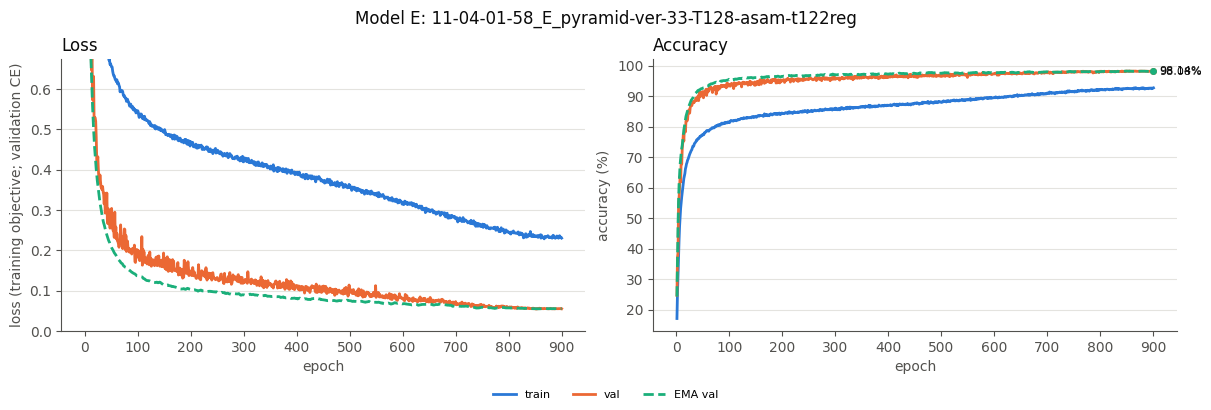

Saved /content/drive/MyDrive/DL_Project1/result/plots/11-04-01-58_E_pyramid-ver-33-T128-asam-t122reg/11-04-01-58_E_pyramid-ver-33-T128-asam-t122reg_curves.png


In [14]:
# Categorical colours in fixed order (one per run, or one per metric for a single run).
SERIES = ["#2a78d6", "#eb6834", "#1baf7a", "#eda100", "#e87ba4", "#008300", "#6250d6", "#e34948"]
INK, INK_MUTED, GRID = "#0b0b0b", "#52514e", "#e4e3df"


def load_log(run_dir):
    df = pd.read_csv(artifact_path(paths_for_run(run_dir), "logs", "log", ".csv"))
    return df.apply(pd.to_numeric, errors="coerce")


def _style(ax, ylabel):
    ax.set_xlabel("epoch", color=INK_MUTED)
    ax.set_ylabel(ylabel, color=INK_MUTED)
    ax.grid(axis="y", color=GRID, linewidth=0.8)
    ax.set_axisbelow(True)
    for side in ("top", "right"):
        ax.spines[side].set_visible(False)
    for side in ("left", "bottom"):
        ax.spines[side].set_color(INK_MUTED)
    ax.tick_params(colors=INK_MUTED)
    ax.xaxis.set_major_locator(MaxNLocator(integer=True))


def _end_label(ax, df, col, color):
    s = df[["epoch", col]].dropna()
    if len(s):
        x, y = s.iloc[-1]
        ax.plot([x], [y], "o", color=color, markersize=4)
        ax.annotate(f"{y:.2f}%", (x, y), xytext=(4, 0), textcoords="offset points",
                    va="center", fontsize=8, color=INK)


def plot_runs(run_dirs, labels=None, out=None, title=None):
    """Two panels (loss, accuracy). One run: colour = metric. Several runs: colour = run,
    line style = metric (val solid, EMA val dashed, train dotted)."""
    run_dirs = [Path(r) for r in run_dirs]
    if len(run_dirs) > len(SERIES):
        raise ValueError(f"at most {len(SERIES)} runs per figure; split them into several figures")
    labels = labels or [r.name for r in run_dirs]
    single = len(run_dirs) == 1
    fig, (ax_loss, ax_acc) = plt.subplots(1, 2, figsize=(12, 4), layout="constrained")
    losses = []

    for i, (run, name) in enumerate(zip(run_dirs, labels)):
        df = load_log(run)
        losses += [df[c].dropna().to_numpy() for c in ("train_loss", "val_loss", "ema_val_loss")]
        has_ema = df["ema_val_acc"].notna().any()
        if single:
            c_train, c_val, c_ema = SERIES[0], SERIES[1], SERIES[2]
            ls_train, prefix = "-", ""
        else:
            c_train = c_val = c_ema = SERIES[i]
            ls_train, prefix = ":", f"{name} "
        lw = dict(linewidth=2)
        train_label = "train weighted" if {"mixup_batches", "cutmix_batches"} & set(df.columns) else "train"
        ax_loss.plot(df["epoch"], df["train_loss"], ls_train, color=c_train, label=f"{prefix}{train_label}", **lw)
        ax_acc.plot(df["epoch"], df["train_acc"], ls_train, color=c_train, label=f"{prefix}{train_label}", **lw)
        if df["val_acc"].notna().any():
            ax_loss.plot(df["epoch"], df["val_loss"], "-", color=c_val, label=f"{prefix}val", **lw)
            ax_acc.plot(df["epoch"], df["val_acc"], "-", color=c_val, label=f"{prefix}val", **lw)
            _end_label(ax_acc, df, "val_acc", c_val)
        if has_ema:
            ax_loss.plot(df["epoch"], df["ema_val_loss"], "--", color=c_ema, label=f"{prefix}EMA val", **lw)
            ax_acc.plot(df["epoch"], df["ema_val_acc"], "--", color=c_ema, label=f"{prefix}EMA val", **lw)
            if single:
                _end_label(ax_acc, df, "ema_val_acc", c_ema)

    _style(ax_loss, "loss (training objective; validation CE)")
    _style(ax_acc, "accuracy (%)")
    ax_loss.set_title("Loss", color=INK, loc="left")
    ax_acc.set_title("Accuracy", color=INK, loc="left")
    loss_values = np.concatenate(losses)
    if len(loss_values) > 5:  # keep a few huge early-epoch losses from flattening the curves
        ax_loss.set_ylim(0, min(loss_values.max(), 1.2 * np.percentile(loss_values, 95)) * 1.05)
    handles, names = ax_acc.get_legend_handles_labels()
    fig.legend(handles, names, loc="outside lower center", ncol=3 if not single else len(names),
               frameon=False, fontsize=8)
    if title:
        fig.suptitle(title, color=INK)
    if out is not None:
        fig.savefig(out, dpi=150)
    return fig


fig = plot_runs([RUN_DIR], out=artifact_path(paths_for_run(RUN_DIR), "plots", "curves", ".png"), title=f"Model {MODEL}: {RUN_DIR.name}")
plt.show()
print(f"Saved {artifact_path(paths_for_run(RUN_DIR), 'plots', 'curves', '.png')}")

## 7. Prediction and submission

The checkpoint's dataset and architecture identities are checked before evaluation. For a validation run,
`WEIGHTS="auto"` selects raw or EMA weights using the requested inference mode: plain accuracy when `TTA=False`,
flip-TTA accuracy when `TTA=True`. This choice is among weights at the selected checkpoint; training selects
the best epoch using non-TTA validation. Full-data refits require explicit weights and use the completed `<RUN_ID>_last-ckpt.pt`.

Timestamped validation reports contain all four raw/EMA × plain/flip comparisons, per-class recall,
confusion matrices and per-example probabilities. Selected-model error plots are saved in `plots`.
Test predictions, format checks, checkpoint hashes and submission CSVs go in `evaluations/test`.
The CSV follows the sample's exact ID order; hidden-test accuracy remains unknown until Kaggle returns it.


In [15]:
def resolve_checkpoint(run_dir, which="best"):
    run_dir = Path(run_dir)
    last = checkpoint_path(run_dir, "last")
    if last.exists() and load_checkpoint(last)["args"]["val_size"] == 0:
        return last  # A full-data run always uses its agreed final epoch.
    path = checkpoint_path(run_dir, which)
    if not path.exists():
        raise FileNotFoundError(f"Requested checkpoint missing: {path}; resume the run to repair/recover it")
    return path


def choose_weights(ckpt, requested, tta=False, val_report=None):
    if requested not in ("auto", "model", "ema"):
        raise ValueError("weights must be auto, model or ema")
    if requested != "auto":
        if requested == "ema" and ckpt["ema"] is None:
            raise ValueError("Checkpoint has no EMA weights")
        return requested
    if not len(ckpt["val_idx"]):
        raise ValueError("No validation split: explicitly use the weights selected in earlier validation experiments")
    if not val_report:
        raise ValueError("Automatic selection requires a fresh validation report")
    metric = "flip_tta" if tta else "no_tta"
    # Ties favor raw weights, consistently with training's best-checkpoint convention.
    return max(val_report, key=lambda name: (val_report[name][metric], name == "model"))


def load_model(ckpt, weights, device):
    options = saved_architecture(ckpt["args"])
    model, n_params = build_model(architecture=options)
    if "architecture" in ckpt and ckpt["architecture"] != architecture_details(options):
        raise ValueError("Checkpoint resolved architecture differs from its saved options")
    if "n_params" in ckpt and ckpt["n_params"] != n_params:
        raise ValueError("Checkpoint parameter count differs from its saved architecture")
    if ckpt.get("model_fingerprint") != model_fingerprint(model) or ckpt["args"]["model"] != MODEL:
        raise ValueError("Checkpoint architecture differs from this notebook")
    model.load_state_dict(ckpt["ema"]["module"] if weights == "ema" else ckpt["model"])
    return model.to(device).eval(), n_params


def validate_submission(path, sample_path):
    sub, sample = pd.read_csv(path), pd.read_csv(sample_path)
    if list(sub.columns) != ["id", "label"] or len(sub) != len(sample):
        raise ValueError("Submission columns or row count differ from the sample")
    if not sub["id"].is_unique or not np.array_equal(sub["id"], sample["id"]):
        raise ValueError("Submission IDs are duplicated or differ from sample order")
    if not pd.api.types.is_integer_dtype(sub["label"]) or not sub["label"].between(0,9).all():
        raise ValueError("Submission labels must be integers in 0..9")
    return len(sub)


def classification_metrics(probs, labels):
    labels = np.asarray(labels)
    probs = np.asarray(probs)
    pred = probs.argmax(1)
    cm = np.bincount(labels * NUM_CLASSES + pred, minlength=NUM_CLASSES**2).reshape(NUM_CLASSES, NUM_CLASSES)
    support = cm.sum(1)
    recall = np.divide(cm.diagonal(), support, out=np.zeros(NUM_CLASSES, dtype=float), where=support > 0)
    return {"accuracy_pct": float((pred == labels).mean()*100), "correct": int((pred == labels).sum()),
            "n": len(labels), "cross_entropy": float(-np.log(probs[np.arange(len(labels)), labels].clip(1e-12)).mean()),
            "per_class_recall": {name: float(value) if count else None
                                 for name, value, count in zip(CLASSES, recall, support)},
            "confusion_matrix": cm.tolist()}


def val_accuracy(ckpt, data_dir, cache_dir, device, batch_size=1000, save_prefix=None):
    fingerprint = verify_cache(ensure_cache(data_dir, cache_dir))["fingerprint"]
    validate_checkpoint(ckpt, fingerprint)
    val_idx = ckpt["val_idx"].numpy()
    if not len(val_idx):
        return {}
    images, labels, ids = load_train(data_dir, cache_dir)
    vx, vy = images[val_idx], labels[val_idx]
    mean, std = ckpt["norm"]["mean"], ckpt["norm"]["std"]
    report, arrays = {}, {"ids": ids[val_idx], "indices": val_idx, "labels": vy}
    for weights in (["model", "ema"] if ckpt["ema"] is not None else ["model"]):
        model = load_model(ckpt, weights, device)[0]
        plain = F.softmax(predict_logits(model, vx, mean, std, device, batch_size), 1).numpy()
        flipped = F.softmax(predict_logits(model, vx, mean, std, device, batch_size, flip=True), 1).numpy()
        report[weights] = {"details": {}}
        for name, probs in (("no_tta", plain), ("flip_tta", 0.5*(plain+flipped))):
            metrics = classification_metrics(probs, vy)
            report[weights][name] = metrics["accuracy_pct"]
            report[weights]["details"][name] = metrics
            arrays[f"{weights}_{name}_probabilities"] = probs
            arrays[f"{weights}_{name}_predictions"] = probs.argmax(1)
    if save_prefix is not None:
        save_prefix = Path(save_prefix)
        with save_prefix.with_suffix(".npz").open("wb") as f:
            np.savez_compressed(f, **arrays)
        write_json_atomic({"epoch": ckpt["epoch"], "cache_fingerprint": fingerprint,
                           "normalization": ckpt["norm"],
                           "crop_padding_mode": ckpt["args"].get("crop_padding_mode", "constant"),
                           "metrics": report}, save_prefix.with_suffix(".json"))
    return report


def plot_validation_diagnostics(ckpt, weights, tta, report, arrays_path, data_dir, cache_dir, out_prefix):
    mode = "flip_tta" if tta else "no_tta"
    cm = np.array(report[weights]["details"][mode]["confusion_matrix"])
    fig, ax = plt.subplots(figsize=(8,7), layout="constrained")
    ax.imshow(cm, cmap="Blues")
    ax.set(xticks=range(10), yticks=range(10), xticklabels=CLASSES, yticklabels=CLASSES,
           xlabel="Predicted label", ylabel="True label", title=f"Validation confusion matrix: {weights}, {mode}")
    plt.setp(ax.get_xticklabels(), rotation=45, ha="right")
    for i in range(10):
        for j in range(10):
            ax.text(j, i, str(cm[i,j]), ha="center", va="center", fontsize=8,
                    color="white" if cm[i,j] > cm.max()/2 else "black")
    fig.savefig(str(out_prefix)+"-confusion.png", dpi=150)
    plt.close(fig)
    with np.load(arrays_path, allow_pickle=False) as arrays:
        labels = arrays["labels"]
        predictions = arrays[f"{weights}_{mode}_predictions"]
        indices = arrays["indices"]
        wrong = np.flatnonzero(predictions != labels)[:12]
        if len(wrong):
            images = load_train(data_dir, cache_dir)[0]
            fig, axes = plt.subplots(3,4,figsize=(10,8),layout="constrained")
            for ax in axes.flat:
                ax.axis("off")
            for ax, pos in zip(axes.flat, wrong):
                ax.imshow(images[indices[pos]])
                ax.set_title(f"true: {CLASSES[labels[pos]]}\npred: {CLASSES[predictions[pos]]}", fontsize=9)
            fig.savefig(str(out_prefix)+"-errors.png", dpi=150)
            plt.close(fig)


def predict_run(run_dir, which="best", weights="auto", tta=True, data_dir=None, cache_dir=None, device=None,
                batch_size=1000):
    device = device or get_device(DEVICE)
    fingerprint = verify_cache(ensure_cache(data_dir, cache_dir))["fingerprint"]
    artifacts = paths_for_run(run_dir)
    ckpt_path = resolve_checkpoint(run_dir, which)
    ckpt = load_checkpoint(ckpt_path)
    validate_checkpoint(ckpt, fingerprint, run_id=artifacts.run_id)
    if ckpt["args"]["val_size"] == 0 and (ckpt["epoch"] != ckpt["args"]["epochs"] or ckpt["args"]["train_subset"]):
        raise ValueError("Full-data submission requires a completed run without a training subset")
    checkpoint_role = "last" if ckpt["args"]["val_size"] == 0 else which
    val_prefix = artifact_path(artifacts, "validation", f"{checkpoint_role}-validation", "", event=True, unique=True)
    val_report = val_accuracy(ckpt, data_dir, cache_dir, device, batch_size, save_prefix=val_prefix)
    weights = choose_weights(ckpt, weights, tta, val_report)
    model, n_params = load_model(ckpt, weights, device)
    mean, std = ckpt["norm"]["mean"], ckpt["norm"]["std"]
    print(f"Checkpoint {ckpt_path.name}, epoch {ckpt['epoch']}; weights {weights}; flip TTA {tta}; params {n_params:,}")
    for name, metrics in val_report.items():
        print(f"Validation {name}: plain {metrics['no_tta']:.2f}%, flip {metrics['flip_tta']:.2f}%")
    if val_report:
        plot_validation_diagnostics(ckpt, weights, tta, val_report, val_prefix.with_suffix(".npz"),
                                    data_dir, cache_dir, artifact_path(artifacts, "plots", checkpoint_role, "", event=True, unique=True))
    test_images, test_ids = load_test(data_dir, cache_dir)
    probs = predict_probs(model, test_images, mean, std, device, batch_size, tta=tta).numpy()
    sample_path = Path(cache_dir) / "sample_submission.csv"
    sample = pd.read_csv(sample_path)
    row_of = {int(value): i for i, value in enumerate(test_ids)}
    if len(row_of) != len(test_ids) or set(sample["id"]) != set(row_of):
        raise ValueError("Test IDs differ from sample or contain duplicates")
    order = np.array([row_of[int(value)] for value in sample["id"]])
    ordered = probs[order]
    out = artifact_path(artifacts, "test", "submission", ".csv", event=True, unique=True)
    pd.DataFrame({"id": sample["id"], "label": ordered.argmax(1).astype(np.int64)}).to_csv(out,index=False)
    n = validate_submission(out, sample_path)
    np.savez_compressed(out.with_name(out.stem.replace("_submission", "_probabilities") + ".npz"), ids=sample["id"].to_numpy(), probabilities=ordered)
    if detect_env() == "kaggle":
        shutil.copyfile(out, work_dir() / "submission.csv")
    report = {"checkpoint": str(ckpt_path), "checkpoint_sha256": sha256_file(ckpt_path),
              "epoch": ckpt["epoch"], "epochs": ckpt["args"]["epochs"], "model": MODEL, "n_params": n_params,
              "architecture": architecture_details(saved_architecture(ckpt["args"])),
              "model_description": model._project_description,
              "crop_padding_mode": ckpt["args"].get("crop_padding_mode", "constant"),
              "n_train": ckpt["n_train"], "n_val": len(ckpt["val_idx"]), "weights": weights, "tta": tta,
              "val": val_report, "submission": str(out), "rows": n, "format_check": "passed",
              "cache_fingerprint": fingerprint, "validation_artifact_prefix": str(val_prefix) if val_report else None,
              "kaggle_public_accuracy": None, "kaggle_private_accuracy": None}
    write_json_atomic(report, out.with_name(out.stem.replace("_submission", "_prediction-report") + ".json"))
    print(f"Submission saved: {out}. Hidden-test accuracy is not available locally.")
    return report


def export_run(run_dir, include_checkpoints=False):
    artifacts = paths_for_run(run_dir)
    records = []
    for name, folder in vars(artifacts).items():
        if name in ("root", "run_id", "exports", "manifests"):
            continue
        for path in sorted(folder.glob("*")):
            if path.is_file() and not path.name.endswith(".tmp"):
                records.append({"path": str(path.relative_to(artifacts.root)), "bytes": path.stat().st_size,
                                "sha256": sha256_file(path), "included_in_bundle": name != "checkpoints" or include_checkpoints})
    manifest = artifact_path(artifacts, "manifests", "manifest", ".json", event=True, unique=True)
    write_json_atomic({"run_id": artifacts.run_id, "files": records}, manifest)
    bundle = artifact_path(artifacts, "exports", "review-bundle", ".zip", event=True, unique=True)
    with zipfile.ZipFile(bundle, "w", zipfile.ZIP_DEFLATED) as z:
        for record in records:
            if record["included_in_bundle"]:
                z.write(artifacts.root / record["path"], record["path"])
        z.write(manifest, str(manifest.relative_to(artifacts.root)))
    print(f"Review bundle: {bundle}")
    print(f"Keep full checkpoints separately in {artifacts.checkpoints}")
    return bundle


In [16]:
SUBMISSION = predict_run(RUN_DIR, CHECKPOINT, WEIGHTS, TTA, PATHS.data_dir, CACHE, DEV, EVAL_BATCH_SIZE)

# Compare the final and selected best epochs without confusing their identities.
VAL_RESULTS = {}
for key, name in (("final", "last-ckpt.pt"), ("best", "best-ckpt.pt")):
    path = checkpoint_path(RUN_DIR, key if key == "best" else "last")
    if not path.exists():
        continue
    ck = load_checkpoint(path)
    if ck["epoch"] == SUBMISSION["epoch"]:
        acc = SUBMISSION["val"]
    else:
        prefix = artifact_path(paths_for_run(RUN_DIR), "validation", f"{key}-validation", "", event=True, unique=True)
        acc = val_accuracy(ck, PATHS.data_dir, CACHE, DEV, EVAL_BATCH_SIZE, save_prefix=prefix)
    if acc:
        weights = choose_weights(ck, WEIGHTS, TTA, acc)
        VAL_RESULTS[key] = {"epoch": ck["epoch"], "weights": weights,
                            "no_tta": acc[weights]["no_tta"], "flip_tta": acc[weights]["flip_tta"]}
write_json_atomic(VAL_RESULTS, artifact_path(paths_for_run(RUN_DIR), "validation", "epoch-comparison", ".json", event=True, unique=True))


Checkpoint 11-04-01-58_E_pyramid-ver-33-T128-asam-t122reg_last-ckpt.pt, epoch 900; weights ema; flip TTA True; params 4,948,490
Validation model: plain 98.14%, flip 98.02%
Validation ema: plain 98.08%, flip 98.00%
Submission saved: /content/drive/MyDrive/DL_Project1/result/evaluations/test/11-04-01-58_E_pyramid-ver-33-T128-asam-t122reg/11-04-14-24_E_pyramid-ver-33-T128-asam-t122reg_submission.csv. Hidden-test accuracy is not available locally.


## 8. Final results and review bundle

The last cell creates a compact ZIP with configuration, logs, evaluations, plots and a checksum manifest.
Full checkpoints stay separately on Drive and are excluded from this review bundle by default. Download the
bundle for each experiment after training. These bundles and actual Kaggle scores will support the next review
and the later `Archive/improvement.md`; no model refinements are inferred from unrun experiments.


In [17]:
artifacts = paths_for_run(RUN_DIR)
results = json.loads((artifact_path(artifacts, "logs", "report", ".json")).read_text())
print(f"FINAL RESULTS | scheme {MODEL}: {results.get('model_description', MODEL_DESCRIPTION)}")
print(f"Run ID: {artifacts.run_id}")
print(f"Parameters: {results['n_params']:,} / {PARAM_BUDGET:,}")
print(f"Training images: {results['n_train']:,}; validation images: {results['n_val']:,}")
print(f"Epochs: {results['epochs']}; compute time: {results['compute_time_min']:.2f} min; "
      f"wall time: {results['wall_time_s']/60:.2f} min; peak CUDA allocation: {results['peak_vram_mib']:.0f} MiB")
for key, value in VAL_RESULTS.items():
    print(f"{key}: epoch {value['epoch']}, {value['weights']}; plain {value['no_tta']:.2f}%, flip {value['flip_tta']:.2f}%")
if not VAL_RESULTS:
    print("No validation score for this full-data refit; use the earlier validation runs for model selection.")
print(f"Submission: {SUBMISSION['submission']}")
print(f"Format check: {SUBMISSION['format_check']}; rows: {SUBMISSION['rows']}")
print("Hidden-test accuracy: record the actual score returned by Kaggle separately.")
REVIEW_BUNDLE = export_run(RUN_DIR, include_checkpoints=False)


FINAL RESULTS | scheme E: PyramidNet-110 bottleneck, alpha=128 (widths 16->144, block outputs 80->576), stochastic depth DROP_PATH=0.0, ShakeDrop SHAKEDROP=0.5 (block l of L=36 perturbed with probability 0.5*l/L, p_L=0.5; gate per image, alpha/beta per element)
Run ID: 11-04-01-58_E_pyramid-ver-33-T128-asam-t122reg
Parameters: 4,948,490 / 5,000,000
Training images: 45,000; validation images: 5,000
Epochs: 900; compute time: 738.05 min; wall time: 745.89 min; peak CUDA allocation: 5511 MiB
final: epoch 900, ema; plain 98.08%, flip 98.00%
best: epoch 848, ema; plain 98.16%, flip 97.96%
Submission: /content/drive/MyDrive/DL_Project1/result/evaluations/test/11-04-01-58_E_pyramid-ver-33-T128-asam-t122reg/11-04-14-24_E_pyramid-ver-33-T128-asam-t122reg_submission.csv
Format check: passed; rows: 2000
Hidden-test accuracy: record the actual score returned by Kaggle separately.
Review bundle: /content/drive/MyDrive/DL_Project1/result/exports/11-04-01-58_E_pyramid-ver-33-T128-asam-t122reg/11-04-1